# P6 Fit Test — model / bounds / range

Loads the saved corrected events (`sr3_master_corrected_P6.pkl`, **70,104 events**)
and compares fit configurations *without* re-running the corrections.

Tests:
1. **3-component** fit with widened mu bounds (the Po-214 upper bound was clipping).
2. **5-component** fit (Rn-222 + Po-218 + Rn-220 + Po-216 + Po-214).
3. **Fit range** (50 / 48 / 45 kPE) and **background** (linear / quadratic).
4. Residuals `(data - fit) / sqrt(data)` vs area.

After choosing a config, port `FIT_PEAKS` / `FIT_RANGE` / `bg_deg` back to
`rn222_analysis_master.ipynb` and rerun its fit/rate sections.


In [1]:
# ═══════════════════════════════════════════════════════════════
# IMPORTS & XENON PLOT STYLE
# ═══════════════════════════════════════════════════════════════
import sys
sys.path.insert(0, '/home/jietang/xenon_plot_style')
from xenonnt_plot_style import XENONPlotStyle as xps
xps.use('xenonnt')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from datetime import datetime, timezone
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 300)
pd.set_option('display.max_columns', 25)
pd.set_option('display.expand_frame_repr', False)

def safe_tight(fig=None):
    try: (fig or plt).tight_layout()
    except Exception: pass

print('Setup complete.')


Setup complete.


In [2]:
# ═══════════════════════════════════════════════════════════════
# LOAD CORRECTED EVENTS  (post-FV sample used by the master fit)
# ═══════════════════════════════════════════════════════════════
SAVE_PATH = '/project2/lgrandi/jietang/sr3_commissioning/sr3_master_corrected_P6.pkl'

ev = pd.read_pickle(SAVE_PATH)

required = ['area_2_corrected', 'time', 'run_name']
missing = [c for c in required if c not in ev.columns]
if missing:
    raise KeyError('corrected pickle is missing columns: %s' % missing)

print('Loaded :', SAVE_PATH)
print('  shape   :', ev.shape)
print('  columns :', list(ev.columns))
print('  events  : %d  |  runs: %d' % (len(ev), ev['run_name'].nunique()))
print('  time    : %s -> %s UTC' % (
    pd.to_datetime(ev['time'].min(), unit='ns', utc=True).strftime('%Y-%m-%d %H:%M'),
    pd.to_datetime(ev['time'].max(), unit='ns', utc=True).strftime('%Y-%m-%d %H:%M')))
_show = [c for c in ['area', 'area_2_corrected', 'area_fraction_top', 'r2_aft_corrected'] if c in ev.columns]
print(ev[_show].describe().round(1).to_string())


Loaded : /project2/lgrandi/jietang/sr3_commissioning/sr3_master_corrected_P6.pkl
  shape   : (70104, 12)
  columns : ['time', 'area', 'area_fraction_top', 'range_50p_area', 'r2', 'x', 'y', 'run_name', 'partition', 'area_aft_corrected', 'r2_aft_corrected', 'area_2_corrected']
  events  : 70104  |  runs: 404
  time    : 2026-09-03 14:54 -> 2026-09-19 19:39 UTC
           area  area_2_corrected  area_fraction_top  r2_aft_corrected
count   70104.0           70104.0            70104.0           70104.0
mean    50443.4           50823.2                0.3            2715.0
std     13937.9           12622.9                0.1             954.3
min     20001.6           16093.0                0.1               0.3
25%     43018.8           46631.5                0.2            2236.7
50%     49956.3           51825.6                0.3            3149.0
75%     57980.0           57389.6                0.4            3429.1
max    117225.7          100911.8                0.5            3600.0


In [3]:
# ═══════════════════════════════════════════════════════════════
# FIT MODEL — generic N-Gaussian + polynomial background
# ═══════════════════════════════════════════════════════════════
FIT_RANGE_DEFAULT = (50e3, 80e3)
N_BINS_FIT = 800
X_REF = 61500.0
RN222_REF = 53000.0
E_RN222 = 5.590

# peak tuple: (name, Q [MeV], mu0, (mu_lo, mu_hi), sig0, (sig_lo, sig_hi))
# Eye-balled PE windows: Rn-222 50-57k, Po-218 57-61k, Po-214 73-78k.
PEAKS_3 = [
    ('Rn-222', 5.590, 53000, (50000, 56500),  900, (300, 2500)),
    ('Po-218', 6.115, 58000, (57000, 61000),  900, (300, 2500)),
    ('Po-214', 7.834, 75000, (73000, 78000), 1100, (300, 2500)),
]
PEAKS_5 = [
    ('Rn-222', 5.590, 53000, (50000, 56500),  900, (300, 2500)),
    ('Po-218', 6.115, 58000, (57000, 61000),  900, (300, 2500)),
    ('Rn-220', 6.288, 59000, (58000, 60000),  800, (250, 2000)),
    ('Po-216', 6.778, 63500, (61000, 66000),  900, (250, 2000)),
    ('Po-214', 7.834, 75000, (73000, 78000), 1100, (300, 2500)),
]

def _gauss(x, amp, mu, sig):
    return amp * np.exp(-0.5 * ((x - mu) / sig)**2)

def _poly_bg(x, *coeffs):
    xr = x - X_REF
    return sum(c * xr**i for i, c in enumerate(coeffs))

def _model(x, n_peaks, bg_deg, p):
    out = _poly_bg(x, *p[-bg_deg-1:])
    for i in range(n_peaks):
        out = out + _gauss(x, p[3*i], p[3*i+1], p[3*i+2])
    return out

def find_peak_guess(events, fit_range, n_bins=150):
    counts, edges = np.histogram(events['area_2_corrected'], bins=n_bins, range=fit_range)
    centers = 0.5*(edges[:-1] + edges[1:])
    pk, props = find_peaks(counts, height=counts.max()*0.05, distance=10)
    sel = (centers[pk] >= 50000) & (centers[pk] <= 56000)
    if sel.any():
        i = pk[sel][np.argmax(props['peak_heights'][sel])]
        return centers[i]
    m = (centers >= 50000) & (centers <= 56000)
    return centers[m][np.argmax(counts[m])] if m.any() else None

def fit_spectrum(events, peaks, fit_range=FIT_RANGE_DEFAULT, n_bins=N_BINS_FIT,
                 bg_deg=2, rn222_ref=RN222_REF):
    """Fit N Gaussians + polynomial bg; return p_fit, mu, sigma, amp, metrics."""
    n_ev = len(events)
    if n_ev < 100:
        return {'success': False, 'status': 'too_few_events(%d)' % n_ev, 'n_events': n_ev}

    counts, edges = np.histogram(events['area_2_corrected'], bins=n_bins, range=fit_range)
    centers = 0.5*(edges[:-1] + edges[1:])
    y_err = np.sqrt(np.maximum(counts, 1))

    rn_guess = find_peak_guess(events, fit_range, min(150, n_bins))
    scale = rn_guess if rn_guess is not None else rn222_ref

    p0, lo, hi = [], [], []
    for (name, Q, mu0, (mlo, mhi), sig0, (slo, shi)) in peaks:
        mu_g = float(np.clip(scale * Q / E_RN222, mlo + 50, mhi - 50))
        amp0 = max(float(np.interp(mu_g, centers, counts)) * 0.5, 3.0)
        p0 += [amp0, mu_g, sig0]
        lo += [0, mlo, slo]
        hi += [np.inf, mhi, shi]
    p0 += [max(np.median(counts), 1.0)] + [0.0]*bg_deg
    lo += [0] + [-np.inf]*bg_deg
    hi += [np.inf] + [np.inf]*bg_deg

    def f(x, *p):
        return _model(x, len(peaks), bg_deg, p)

    try:
        popt, pcov = curve_fit(f, centers, counts, p0=p0, sigma=y_err,
                               bounds=(lo, hi), maxfev=100000)
    except Exception as e:
        return {'success': False, 'status': 'fit_failed: %s' % e, 'n_events': n_ev}

    model = f(centers, *popt)
    chi2 = float(np.sum(((counts - model)/y_err)**2))
    k = len(popt)
    ndf = max(n_bins - k, 1)
    n_peaks = len(peaks)
    return {
        'success': True, 'status': 'success',
        'p_fit': popt, 'pcov': pcov,
        'amp': popt[0:3*n_peaks:3],
        'mu': popt[1:3*n_peaks:3],
        'sigma': popt[2:3*n_peaks:3],
        'bg': popt[3*n_peaks:],
        'chi2': chi2, 'ndf': ndf, 'chi2_ndf': chi2/ndf,
        'aic': chi2 + 2*k, 'bic': chi2 + k*np.log(max(n_bins, 2)),
        'n_events': n_ev, 'n_bins': n_bins,
        'centers': centers, 'counts': counts, 'model': model,
        'peaks': peaks, 'fit_range': fit_range, 'bg_deg': bg_deg,
    }


In [4]:
# ═══════════════════════════════════════════════════════════════
# PLOT FIT + RESIDUALS
# ═══════════════════════════════════════════════════════════════
def plot_fit(res, title='', show_components=True):
    if not res.get('success'):
        print(title, 'FAILED:', res.get('status'))
        return

    centers, counts, model = res['centers'], res['counts'], res['model']
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True,
                                   gridspec_kw={'height_ratios': [3, 1]})

    ax1.step(centers, counts, where='mid', color='steelblue', lw=1.0,
             label='Data (%d evts)' % res['n_events'])
    ax1.plot(centers, model, 'r-', lw=1.5, label='Total fit')
    if show_components:
        colors = plt.cm.tab10(np.linspace(0, 1, len(res['peaks'])))
        for i, spec in enumerate(res['peaks']):
            name = spec[0]
            g = _gauss(centers, res['amp'][i], res['mu'][i], res['sigma'][i])
            ax1.plot(centers, g, '--', color=colors[i], lw=1.0,
                     label='%s mu=%.0f sig=%.0f' % (name, res['mu'][i], res['sigma'][i]))

    ax1.set_ylabel('Counts/bin')
    ax1.set_title('%s  |  chi2/ndf=%.2f  AIC=%.1f  BIC=%.1f' % (
        title, res['chi2_ndf'], res['aic'], res['bic']), fontsize=12)
    ax1.legend(fontsize=7, ncol=2, loc='upper right')
    ax1.grid(True, alpha=0.25)

    pull = (counts - model) / np.sqrt(np.maximum(counts, 1))
    ax2.axhline(0, color='k', lw=1)
    ax2.plot(centers, pull, 'o', ms=1.5, color='steelblue')
    ax2.set_ylabel('(data-fit)/sqrt(data)')
    ax2.set_xlabel('AFT + r^2 Corrected Area [PE]')
    ax2.grid(True, alpha=0.25)
    ax2.set_xlim(res['fit_range'])
    safe_tight(fig); plt.show()


def summary_row(label, res):
    if not res.get('success'):
        return {'config': label, 'status': res.get('status')}
    row = {'config': label, 'status': 'ok', 'n_par': len(res['p_fit']),
           'chi2/ndf': round(res['chi2_ndf'], 2),
           'AIC': round(res['aic'], 1), 'BIC': round(res['bic'], 1)}
    for spec, mu, sig in zip(res['peaks'], res['mu'], res['sigma']):
        row['mu_'+spec[0]] = round(float(mu), 1)
        row['sig_'+spec[0]] = round(float(sig), 1)
    return row


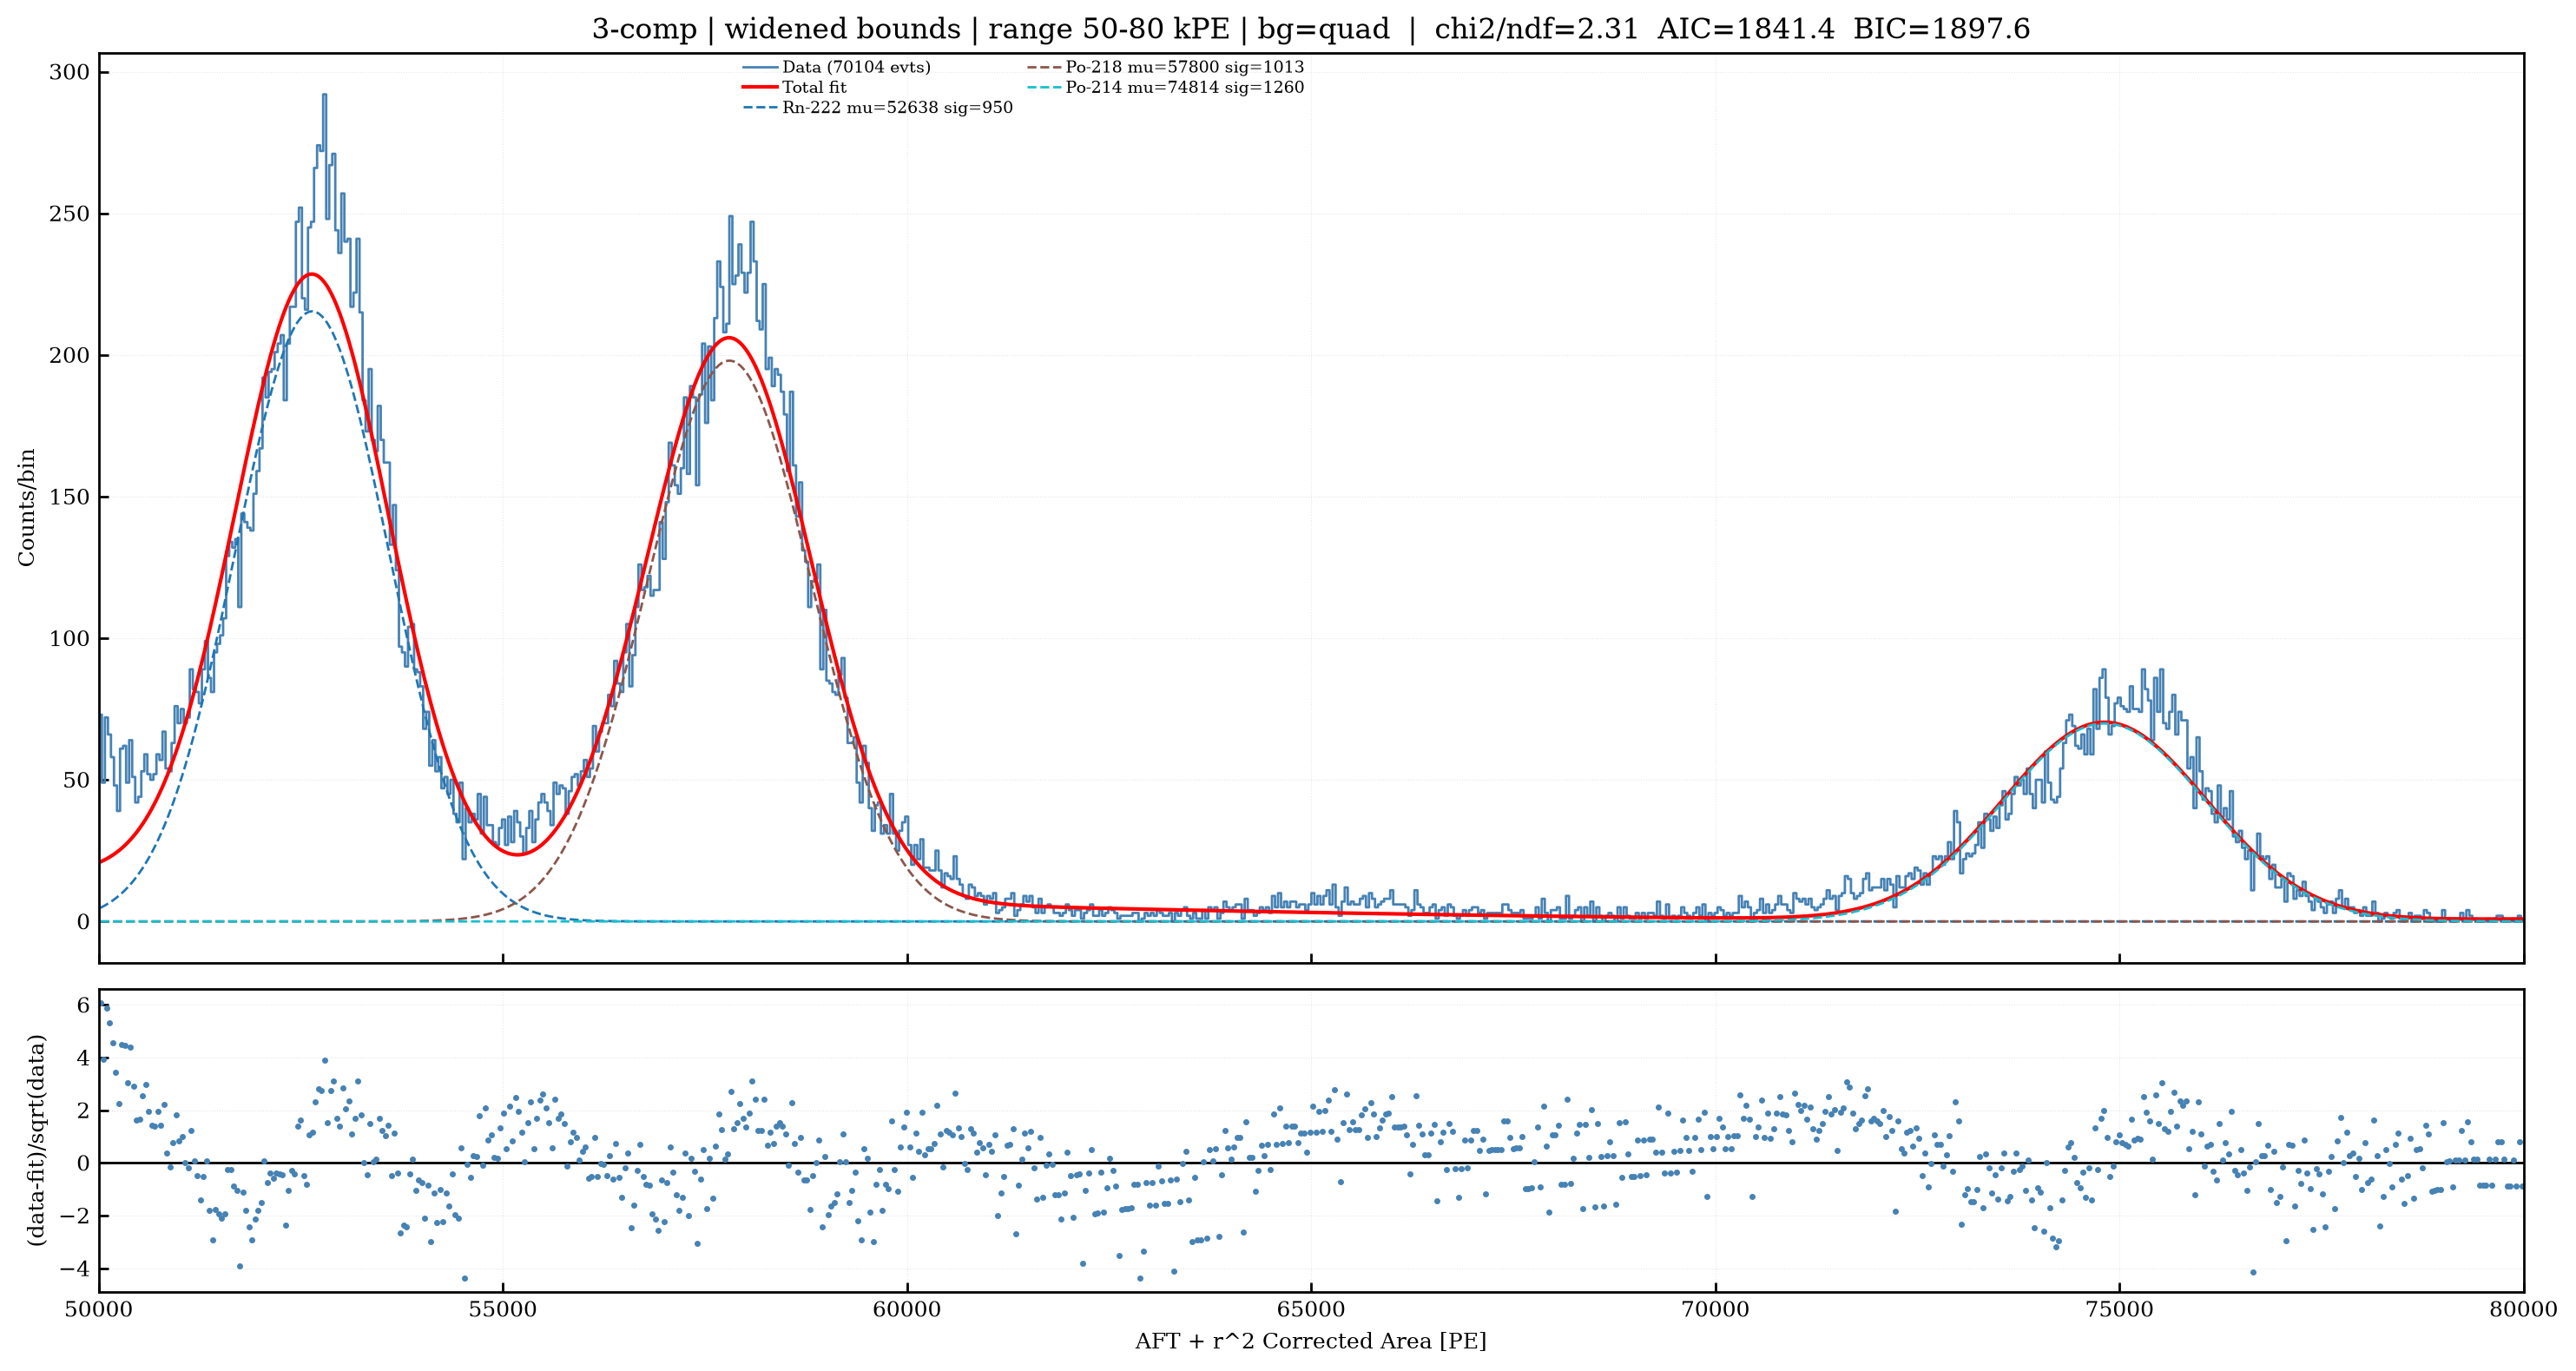

  Rn-222  mu= 52638.4 PE  sigma= 949.8
  Po-218  mu= 57800.0 PE  sigma=1013.5
  Po-214  mu= 74813.8 PE  sigma=1259.9


In [5]:
# ═══════════════════════════════════════════════════════════════
# TEST 1 — 3 components, widened mu bounds
# ═══════════════════════════════════════════════════════════════
res3 = fit_spectrum(ev, PEAKS_3, FIT_RANGE_DEFAULT, N_BINS_FIT, bg_deg=2)
plot_fit(res3, '3-comp | widened bounds | range %.0f-%.0f kPE | bg=quad' % (
    FIT_RANGE_DEFAULT[0]/1e3, FIT_RANGE_DEFAULT[1]/1e3))

if res3.get('success'):
    for spec, mu, sig in zip(PEAKS_3, res3['mu'], res3['sigma']):
        print('  %-7s mu=%8.1f PE  sigma=%6.1f' % (spec[0], mu, sig))
else:
    print('res3 failed:', res3.get('status'))


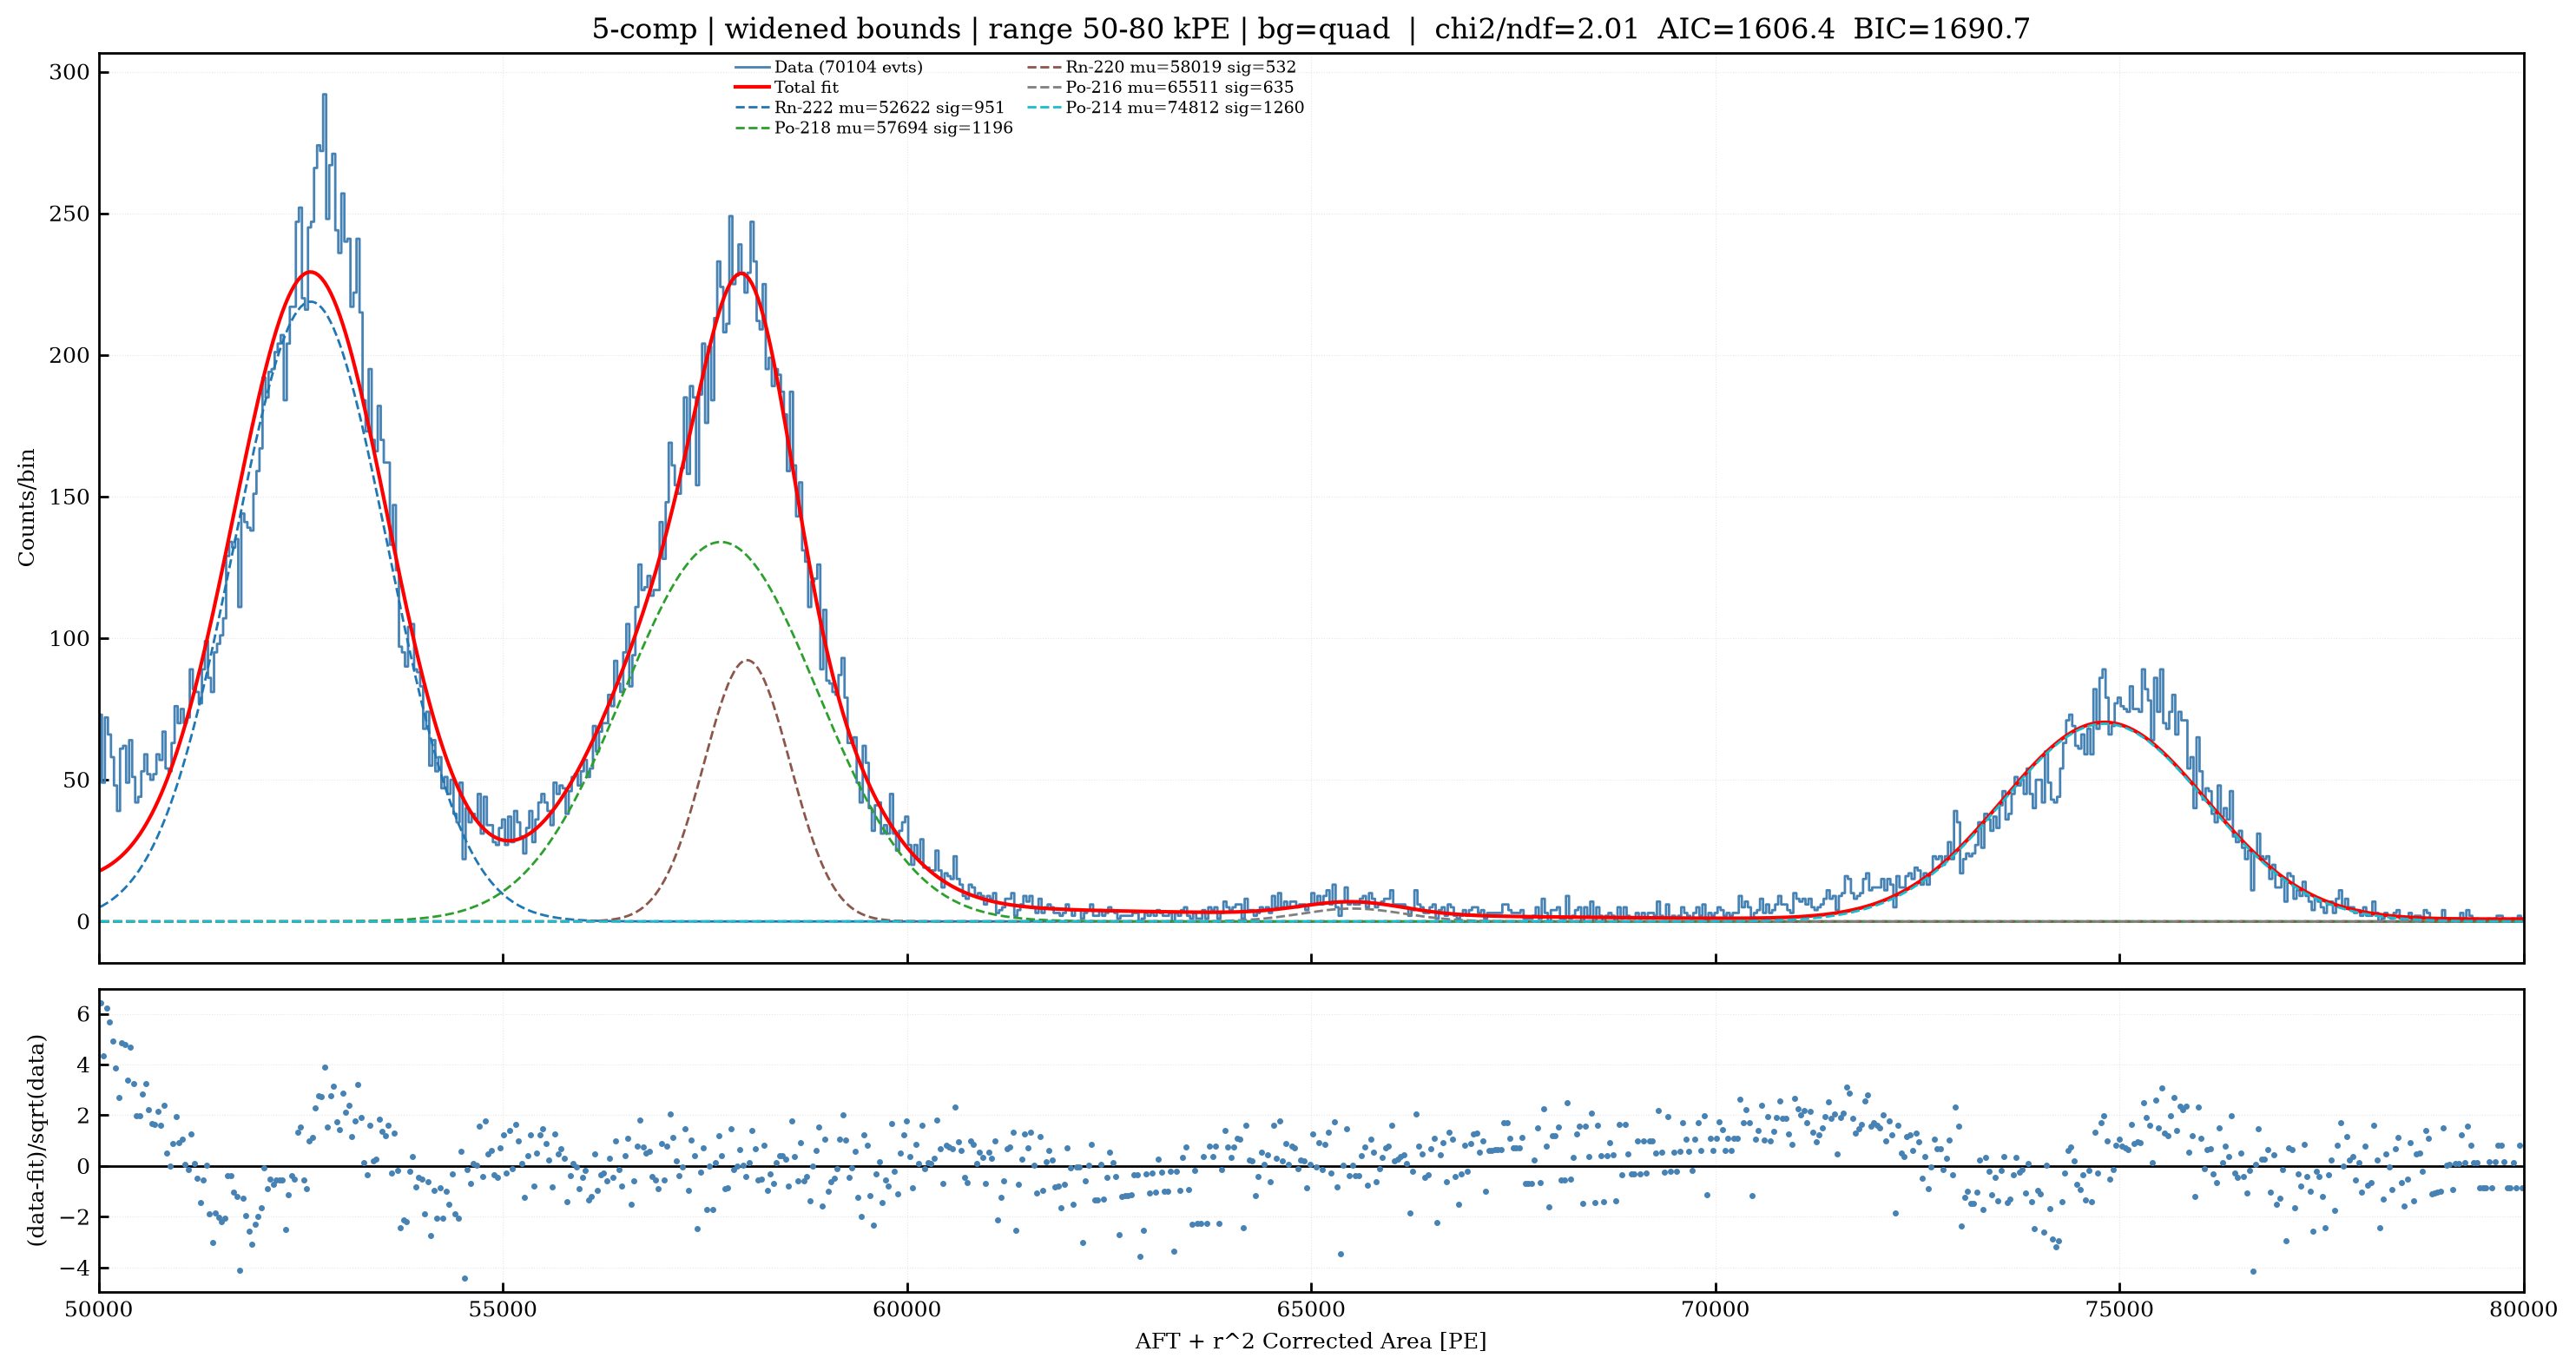

config status  n_par  chi2/ndf    AIC    BIC  mu_Rn-222  sig_Rn-222  mu_Po-218  sig_Po-218  mu_Po-214  sig_Po-214  mu_Rn-220  sig_Rn-220  mu_Po-216  sig_Po-216
3-comp     ok     12      2.31 1841.4 1897.6    52638.4       949.8    57800.0      1013.5    74813.8      1259.9        NaN         NaN        NaN         NaN
5-comp     ok     18      2.01 1606.4 1690.7    52621.9       950.7    57694.1      1196.1    74812.0      1260.1    58019.2       531.9    65510.9       635.2


In [6]:
# ═══════════════════════════════════════════════════════════════
# TEST 2 — 5 components (adds Rn-220 / Po-216)
# ═══════════════════════════════════════════════════════════════
res5 = fit_spectrum(ev, PEAKS_5, FIT_RANGE_DEFAULT, N_BINS_FIT, bg_deg=2)
plot_fit(res5, '5-comp | widened bounds | range %.0f-%.0f kPE | bg=quad' % (
    FIT_RANGE_DEFAULT[0]/1e3, FIT_RANGE_DEFAULT[1]/1e3))

cmp = pd.DataFrame([summary_row('3-comp', res3), summary_row('5-comp', res5)])
print(cmp.to_string(index=False))


In [7]:
# ═══════════════════════════════════════════════════════════════
# TEST 3 — fit range × background scan
# ═══════════════════════════════════════════════════════════════
# NOTE: AIC/BIC are only strictly comparable at the same range/binning;
# across ranges prefer chi2/ndf + residual shape + mu stability.
rows = []
for peaks, plabel in [(PEAKS_3, '3-comp'), (PEAKS_5, '5-comp')]:
    for fr in [(50e3, 80e3), (48e3, 80e3), (45e3, 80e3)]:
        for bg_deg in [2, 1]:
            r = fit_spectrum(ev, peaks, fr, N_BINS_FIT, bg_deg=bg_deg)
            row = summary_row('%s | %.0f-%.0f kPE | bg%d' % (
                plabel, fr[0]/1e3, fr[1]/1e3, bg_deg), r)
            rows.append(row)

scan = pd.DataFrame(rows)
print(scan.to_string(index=False))
scan.to_csv('fit_test_scan_P6.csv', index=False)
print('\nWrote fit_test_scan_P6.csv')


                  config status  n_par  chi2/ndf     AIC     BIC  mu_Rn-222  sig_Rn-222  mu_Po-218  sig_Po-218  mu_Po-214  sig_Po-214  mu_Rn-220  sig_Rn-220  mu_Po-216  sig_Po-216
3-comp | 50-80 kPE | bg2     ok     12      2.31  1841.4  1897.6    52638.4       949.8    57800.0      1013.5    74813.8      1259.9        NaN         NaN        NaN         NaN
3-comp | 50-80 kPE | bg1     ok     11      2.38  1901.8  1953.4    52608.6      1023.8    57789.9      1047.7    74842.3      1234.9        NaN         NaN        NaN         NaN
3-comp | 48-80 kPE | bg2     ok     12      6.72  5319.2  5375.4    52718.2       718.2    57853.0       876.3    74678.4      1408.3        NaN         NaN        NaN         NaN
3-comp | 48-80 kPE | bg1     ok     11     10.24  8102.6  8154.1    52578.2      1076.0    57801.4      1009.7    74859.4      1281.0        NaN         NaN        NaN         NaN
3-comp | 45-80 kPE | bg2     ok     12      9.82  7763.6  7819.8    52738.1       650.8    57870.3  

In [8]:
# ═══════════════════════════════════════════════════════════════
# (B preview) DAILY COMBINED FIT — last days
# ═══════════════════════════════════════════════════════════════
ev['day'] = pd.to_datetime(ev['time'], unit='ns', utc=True).dt.date

rows = []
for day, g in ev.groupby('day'):
    r = fit_spectrum(g, PEAKS_3, FIT_RANGE_DEFAULT, 400, bg_deg=2)
    row = summary_row(str(day), r)
    if r.get('success'):
        row['n_events'] = r['n_events']
    rows.append(row)

daily = pd.DataFrame(rows).rename(columns={'config': 'day'}).sort_values('day').reset_index(drop=True)
print(daily.to_string(index=False))
daily.to_csv('fit_test_daily_P6.csv', index=False)
print('\nWrote fit_test_daily_P6.csv')


       day status  n_par  chi2/ndf   AIC   BIC  mu_Rn-222  sig_Rn-222  mu_Po-218  sig_Po-218  mu_Po-214  sig_Po-214  n_events
2026-09-03     ok     12      0.50 218.9 266.8    52468.7       642.7    57580.7       805.0    74166.2      1333.5      1624
2026-09-04     ok     12      0.89 368.5 416.4    52598.4       666.7    57713.6       786.3    74708.0      1096.6      3696
2026-09-05     ok     12      0.70 294.5 342.4    52702.0       732.7    57878.1       791.6    74840.4      1086.5      4713
2026-09-06     ok     12      0.83 345.4 393.3    52714.3       620.4    57811.4       776.0    75112.5       891.0      4597
2026-09-07     ok     12      0.87 361.2 409.1    52780.2       692.5    57920.8       792.9    75014.2       952.6      4851
2026-09-08     ok     12      0.69 292.6 340.5    52767.9       667.3    57930.7       811.3    75031.3       990.2      4728
2026-09-09     ok     12      0.73 307.3 355.2    52805.0       698.3    57935.0       742.0    75043.3      1022.7   

In [9]:
# ═══════════════════════════════════════════════════════════════
# SAVE PARTITION-FIT SUMMARY
# ═══════════════════════════════════════════════════════════════
part = pd.DataFrame([summary_row('3-comp', res3), summary_row('5-comp', res5)])
part.to_csv('fit_test_partition_P6.csv', index=False)
print('Wrote fit_test_partition_P6.csv')
print(part.to_string(index=False))


Wrote fit_test_partition_P6.csv
config status  n_par  chi2/ndf    AIC    BIC  mu_Rn-222  sig_Rn-222  mu_Po-218  sig_Po-218  mu_Po-214  sig_Po-214  mu_Rn-220  sig_Rn-220  mu_Po-216  sig_Po-216
3-comp     ok     12      2.31 1841.4 1897.6    52638.4       949.8    57800.0      1013.5    74813.8      1259.9        NaN         NaN        NaN         NaN
5-comp     ok     18      2.01 1606.4 1690.7    52621.9       950.7    57694.1      1196.1    74812.0      1260.1    58019.2       531.9    65510.9       635.2


## AFT-dependence study (step 0 / scheme 1 / scheme 3)

The residual low-AFT shift is not removed by corr1/2/3. This section:

1. measures the Rn-222 peak position vs AFT (and r² slices) — is it **AFT-only** or **2D**?
2. scans a tighter AFT cut (**scheme 1**; uniform-FMass approximation).
3. applies a second, non-parametric AFT correction on `area_2_corrected` (**scheme 3**).
4. prototypes 4-bin AFT fits with uniform FMass (**scheme 2**).


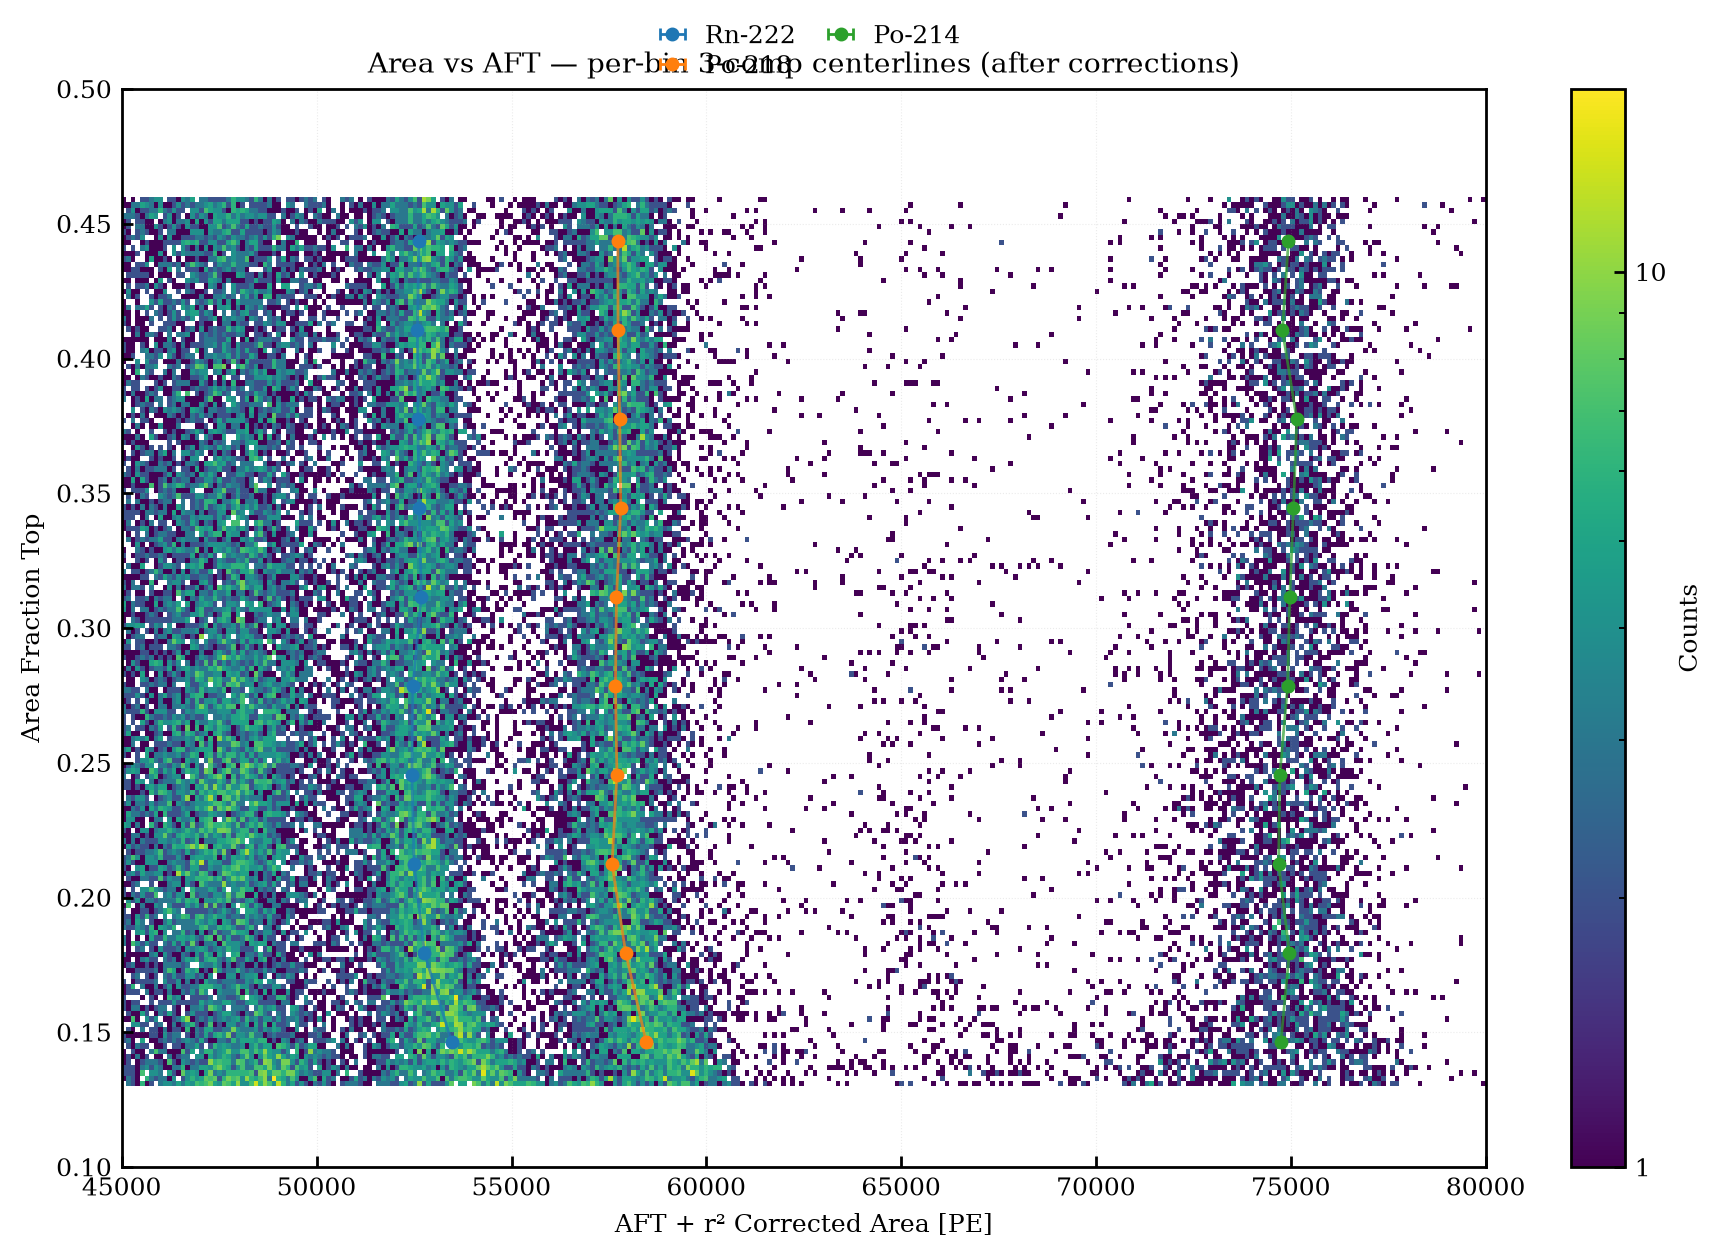

isotope  aft_lo  aft_hi  aft_mid           mu    mu_err  n_events
 Rn-222   0.130   0.163   0.1465 53460.968697 39.370175     10710
 Po-218   0.130   0.163   0.1465 58453.493751 36.375393     10710
 Po-214   0.130   0.163   0.1465 74740.866404 81.949751     10710
 Rn-222   0.163   0.196   0.1795 52763.954009 26.380578      8231
 Po-218   0.163   0.196   0.1795 57928.646449 29.723310      8231
 Po-214   0.163   0.196   0.1795 74957.190669 46.919264      8231
 Rn-222   0.196   0.229   0.2125 52499.982250 23.099140      8115
 Po-218   0.196   0.229   0.2125 57579.053300 26.709618      8115
 Po-214   0.196   0.229   0.2125 74682.661539 48.276356      8115
 Rn-222   0.229   0.262   0.2455 52442.284006 26.855521      7525
 Po-218   0.229   0.262   0.2455 57703.638531 27.658907      7525
 Po-214   0.229   0.262   0.2455 74713.183584 64.023685      7525
 Rn-222   0.262   0.295   0.2785 52467.452220 28.226201      6759
 Po-218   0.262   0.295   0.2785 57666.302549 26.272818      6759
 Po-214   

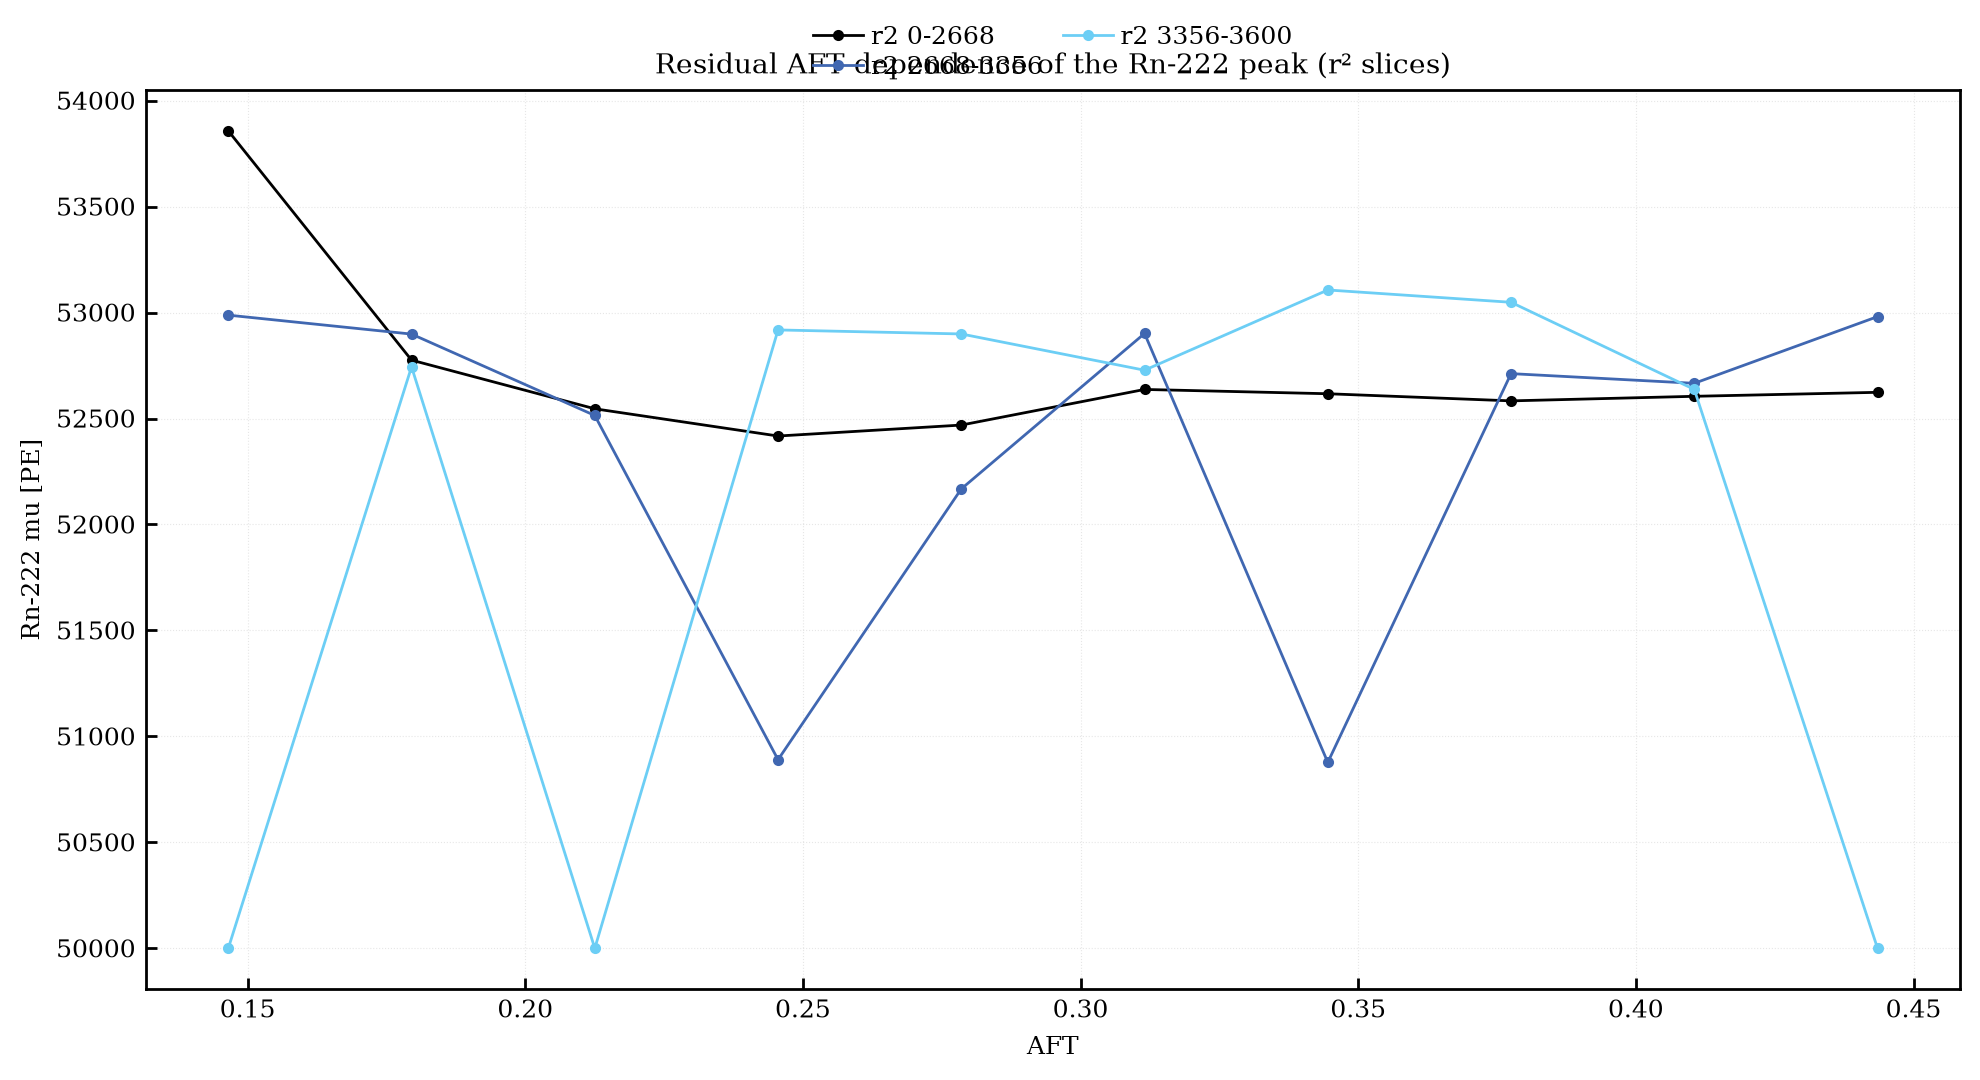

    r2_slice  aft_mid     mu_Rn222      mu_err  n_events
   r2 0-2668   0.1465 53857.265432   31.238704      3603
   r2 0-2668   0.1795 52775.488244   25.782939      2945
   r2 0-2668   0.2125 52545.871620   29.866202      2676
   r2 0-2668   0.2455 52417.336209   28.558602      2349
   r2 0-2668   0.2785 52469.055412   30.748813      2192
   r2 0-2668   0.3115 52637.133833   28.764842      2036
   r2 0-2668   0.3445 52616.865593   29.500888      1912
   r2 0-2668   0.3775 52583.194713   29.394722      1872
   r2 0-2668   0.4105 52604.763038   31.365693      1894
   r2 0-2668   0.4435 52623.537911   32.832394      1889
r2 2668-3356   0.1465 52987.804885   58.153721      3084
r2 2668-3356   0.1795 52898.350224   83.014417      2359
r2 2668-3356   0.2125 52514.321006   82.006266      2567
r2 2668-3356   0.2455 50890.068992 1693.918546      2618
r2 2668-3356   0.2785 52167.821146  246.784061      2532
r2 2668-3356   0.3115 52901.187507   77.462165      2231
r2 2668-3356   0.3445 50877.277

In [10]:
# ═══════════════════════════════════════════════════════════════
# STEP 0 — residual AFT dependence + Area vs AFT centerlines
# ═══════════════════════════════════════════════════════════════
# Peak windows (eye-balled): Rn-222 50-57k | Po-218 57-61k | Po-214 73-78k.
# The 2D centerlines use the 3-component fit per AFT bin; the r² slices use
# a single-Gaussian Rn-222 fit (more stable at low statistics).

R2_COL = 'r2_aft_corrected' if 'r2_aft_corrected' in ev.columns else 'r2'
AFT_LO, AFT_HI = 0.13, 0.46
N_AFT_BINS = 10
ISO_LIST = ['Rn-222', 'Po-218', 'Po-214']

ISO_SPECS = {
    'Rn-222': [('Rn-222', 5.590, 53000, (50000, 57000),  900, (300, 2500))],
    'Po-218': [('Po-218', 6.115, 58000, (57000, 61000),  900, (300, 2500))],
    'Po-214': [('Po-214', 7.834, 75000, (73000, 78000), 1100, (300, 2500))],
}
ISO_WINDOWS = {'Rn-222': (50e3, 57e3), 'Po-218': (57e3, 61e3), 'Po-214': (73e3, 78e3)}
ISO_COLORS  = {'Rn-222': 'tab:blue', 'Po-218': 'tab:orange', 'Po-214': 'tab:green'}

def peak_position(sub, iso):
    r = fit_spectrum(sub, ISO_SPECS[iso], ISO_WINDOWS[iso], 200, bg_deg=1)
    if not r.get('success'):
        return np.nan, np.nan, r.get('n_events', 0)
    mu = float(r['mu'][0])
    err = float(np.sqrt(max(r['pcov'][1, 1], 0.0)))
    return mu, err, r['n_events']

def fit_peaks(sub):
    """3-component fit; returns (mu, mu_err, n_events) arrays or None."""
    r = fit_spectrum(sub, PEAKS_3, FIT_RANGE_DEFAULT, 400, bg_deg=2)
    if not r.get('success'):
        return None
    diag = np.diag(r['pcov'])
    mu = np.asarray(r['mu'], float)
    err = np.sqrt(np.maximum(diag[[1, 4, 7]], 0.0))
    return mu, err, r['n_events']

aft_edges = np.linspace(AFT_LO, AFT_HI, N_AFT_BINS + 1)
aft_centers = np.asarray(0.5*(aft_edges[:-1] + aft_edges[1:]))

# ── Figure 1: Area vs AFT + the three centerlines (3-comp fit) ──
fig, ax = plt.subplots(figsize=(11, 7))
h = ax.hist2d(ev['area_2_corrected'], ev['area_fraction_top'],
              bins=[300, 200], range=[[45e3, 80e3], [0.10, 0.50]],
              cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
plt.colorbar(h[3], ax=ax, label='Counts')

rows = []
pos = {iso: {'aft': [], 'mu': [], 'err': []} for iso in ISO_LIST}
for lo, hi in zip(aft_edges[:-1], aft_edges[1:]):
    sub = ev[(ev['area_fraction_top'] >= lo) & (ev['area_fraction_top'] < hi)]
    out = fit_peaks(sub)
    if out is None:
        continue
    mus, errs, n = out
    for iso, mu, me in zip(ISO_LIST, mus, errs):
        pos[iso]['aft'].append(0.5*(lo+hi))
        pos[iso]['mu'].append(float(mu))
        pos[iso]['err'].append(float(me))
        rows.append({'isotope': iso, 'aft_lo': lo, 'aft_hi': hi, 'aft_mid': 0.5*(lo+hi),
                     'mu': float(mu), 'mu_err': float(me), 'n_events': n})

for iso in ISO_LIST:
    aft = np.asarray(pos[iso]['aft']); mu = np.asarray(pos[iso]['mu']); err = np.asarray(pos[iso]['err'])
    m = np.isfinite(mu)
    ax.errorbar(mu[m], aft[m], xerr=err[m], fmt='o', ms=4, capsize=2,
                color=ISO_COLORS[iso], lw=1, label=iso)
    ax.plot(mu[m], aft[m], '-', color=ISO_COLORS[iso], lw=1, alpha=0.7)

ax.set_xlabel('AFT + r² Corrected Area [PE]')
ax.set_ylabel('Area Fraction Top')
ax.set_title('Area vs AFT — per-bin 3-comp centerlines (after corrections)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.2)
safe_tight(fig); plt.show()

aft_diag = pd.DataFrame(rows)
print(aft_diag.to_string(index=False))
aft_diag.to_csv('fit_test_aft_dependence_P6.csv', index=False)

# ── Figure 2: Rn-222 mu vs AFT for equal-count r² slices (2D test) ──
_r2v = ev[R2_COL].dropna().values
r2_edges = np.nanquantile(_r2v, [0.0, 1/3, 2/3, 1.0])
r2_edges[0] -= 1e-6; r2_edges[-1] += 1e-6
r2_labels = ['r2 %.0f-%.0f' % (r2_edges[i], r2_edges[i+1]) for i in range(3)]

fig, ax = plt.subplots(figsize=(10, 5.5))
rows_r2 = []
for j, lab in enumerate(r2_labels):
    r2lo, r2hi = r2_edges[j], r2_edges[j+1]
    mus = []
    for lo, hi in zip(aft_edges[:-1], aft_edges[1:]):
        sub = ev[(ev['area_fraction_top'] >= lo) & (ev['area_fraction_top'] < hi) &
                 (ev[R2_COL] >= r2lo) & (ev[R2_COL] < r2hi)]
        mu, me, n = peak_position(sub, 'Rn-222')
        mus.append(mu)
        rows_r2.append({'r2_slice': lab, 'aft_mid': 0.5*(lo+hi),
                        'mu_Rn222': mu, 'mu_err': me, 'n_events': n})
    ax.plot(aft_centers, mus, 'o-', label=lab)

ax.set_xlabel('AFT'); ax.set_ylabel('Rn-222 mu [PE]')
ax.set_title('Residual AFT dependence of the Rn-222 peak (r² slices)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.25)
safe_tight(fig); plt.show()

aft_r2 = pd.DataFrame(rows_r2)
print(aft_r2.to_string(index=False))
aft_r2.to_csv('fit_test_aft_r2_P6.csv', index=False)
print('\nWrote fit_test_aft_dependence_P6.csv and fit_test_aft_r2_P6.csv')


In [11]:
# ═══════════════════════════════════════════════════════════════
# SCHEME 1 — tighter AFT cut scan
# ═══════════════════════════════════════════════════════════════
# Uniform-FMass assumption: mass fraction = (AFT_HI - AFT_MIN)/(AFT_HI - AFT_LO)
# (used only if you want a mass-scaled rate; the fit-shape test does not need it.)
AFT_CUTS = [0.13, 0.18, 0.20, 0.22, 0.25]
rows = []
for amin in AFT_CUTS:
    sub = ev[ev['area_fraction_top'] >= amin]
    r = fit_spectrum(sub, PEAKS_3, FIT_RANGE_DEFAULT, N_BINS_FIT, bg_deg=2)
    row = summary_row('AFT>%.2f' % amin, r)
    row['n_events'] = len(sub)
    row['mass_frac'] = (AFT_HI - amin) / (AFT_HI - AFT_LO)
    row['FMASS_kg'] = 3660.0 * row['mass_frac']
    rows.append(row)

aft_scan = pd.DataFrame(rows)
print(aft_scan.to_string(index=False))
aft_scan.to_csv('fit_test_aft_cut_scan_P6.csv', index=False)
print('\nWrote fit_test_aft_cut_scan_P6.csv')


  config status  n_par  chi2/ndf    AIC    BIC  mu_Rn-222  sig_Rn-222  mu_Po-218  sig_Po-218  mu_Po-214  sig_Po-214  n_events  mass_frac    FMASS_kg
AFT>0.13     ok     12      2.31 1841.4 1897.6    52638.4       949.8    57800.0      1013.5    74813.8      1259.9     70104   1.000000 3660.000000
AFT>0.18     ok     12      2.27 1816.3 1872.5    52531.4       837.5    57691.1       900.7    74806.4      1172.5     55136   0.848485 3105.454545
AFT>0.20     ok     12      2.10 1676.1 1732.3    52523.0       841.8    57681.1       902.8    74805.6      1161.6     50175   0.787879 2883.636364
AFT>0.22     ok     12      2.05 1641.6 1697.9    52525.5       846.7    57694.9       886.3    74833.2      1149.8     45233   0.727273 2661.818182
AFT>0.25     ok     12      1.86 1488.9 1545.1    52547.5       829.0    57706.4       879.7    74855.6      1142.1     38096   0.636364 2329.090909

Wrote fit_test_aft_cut_scan_P6.csv


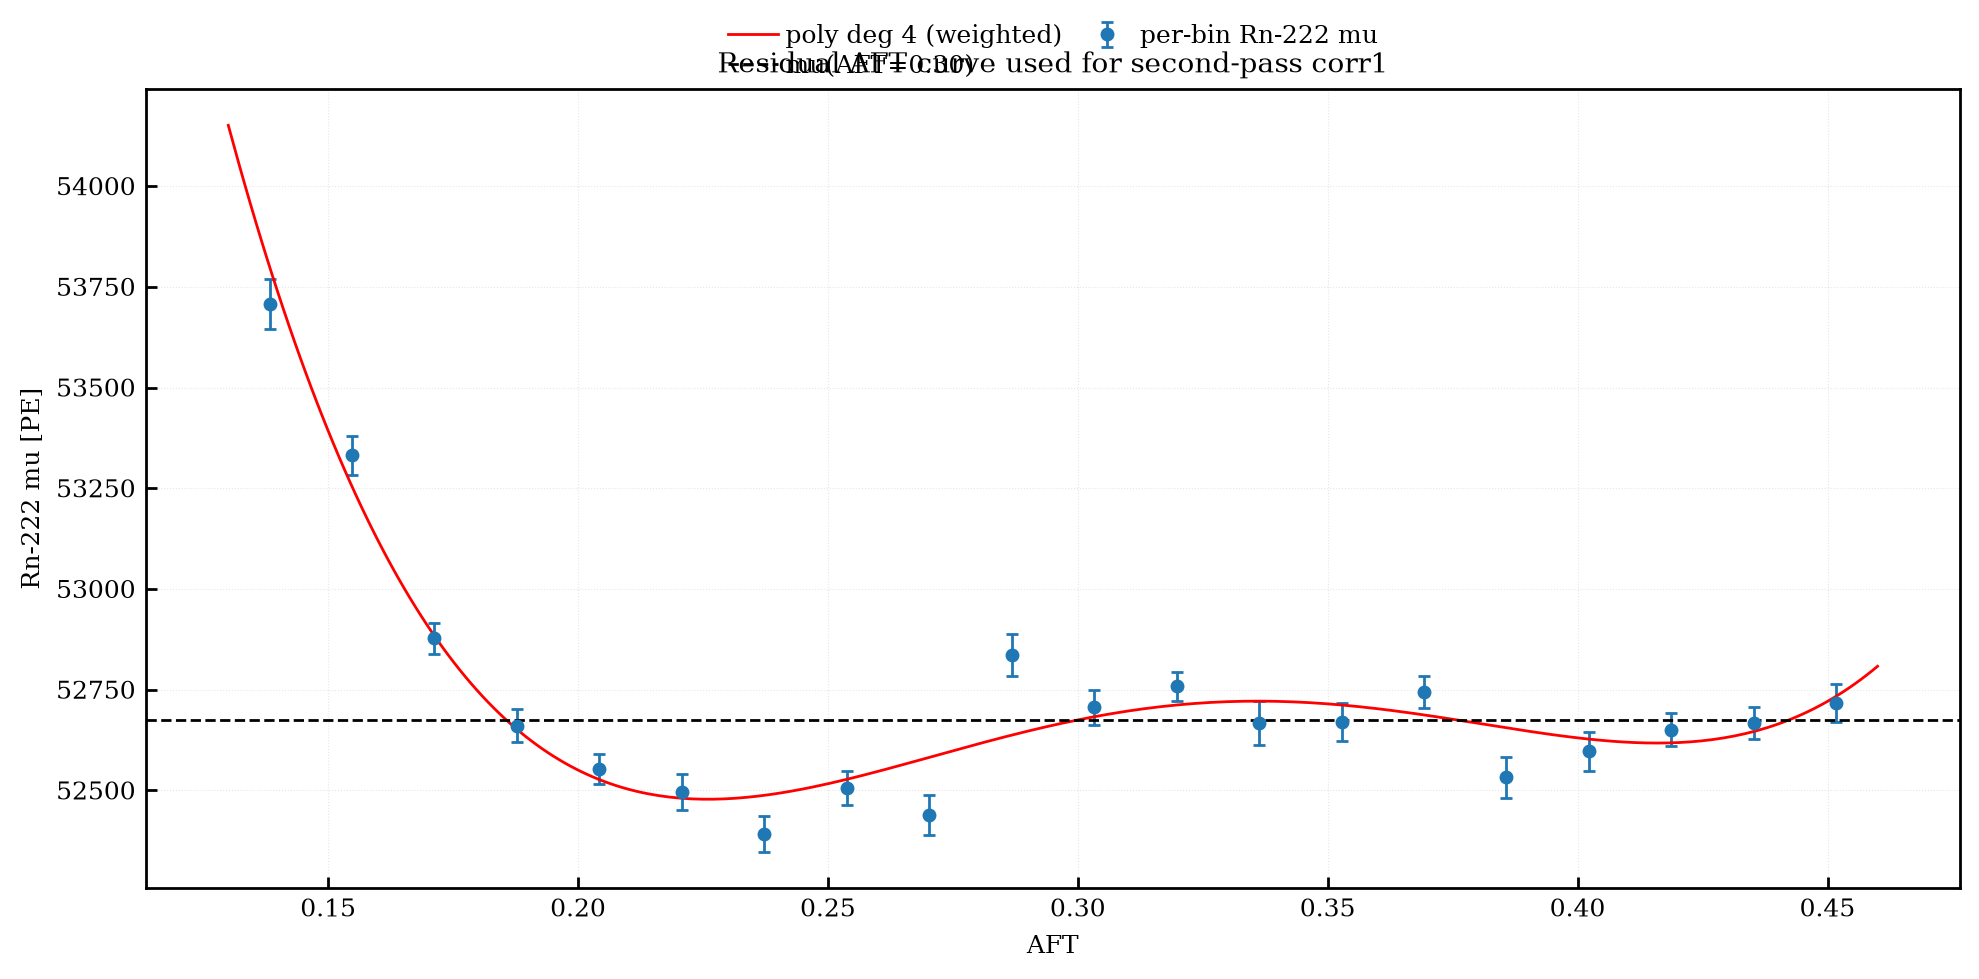

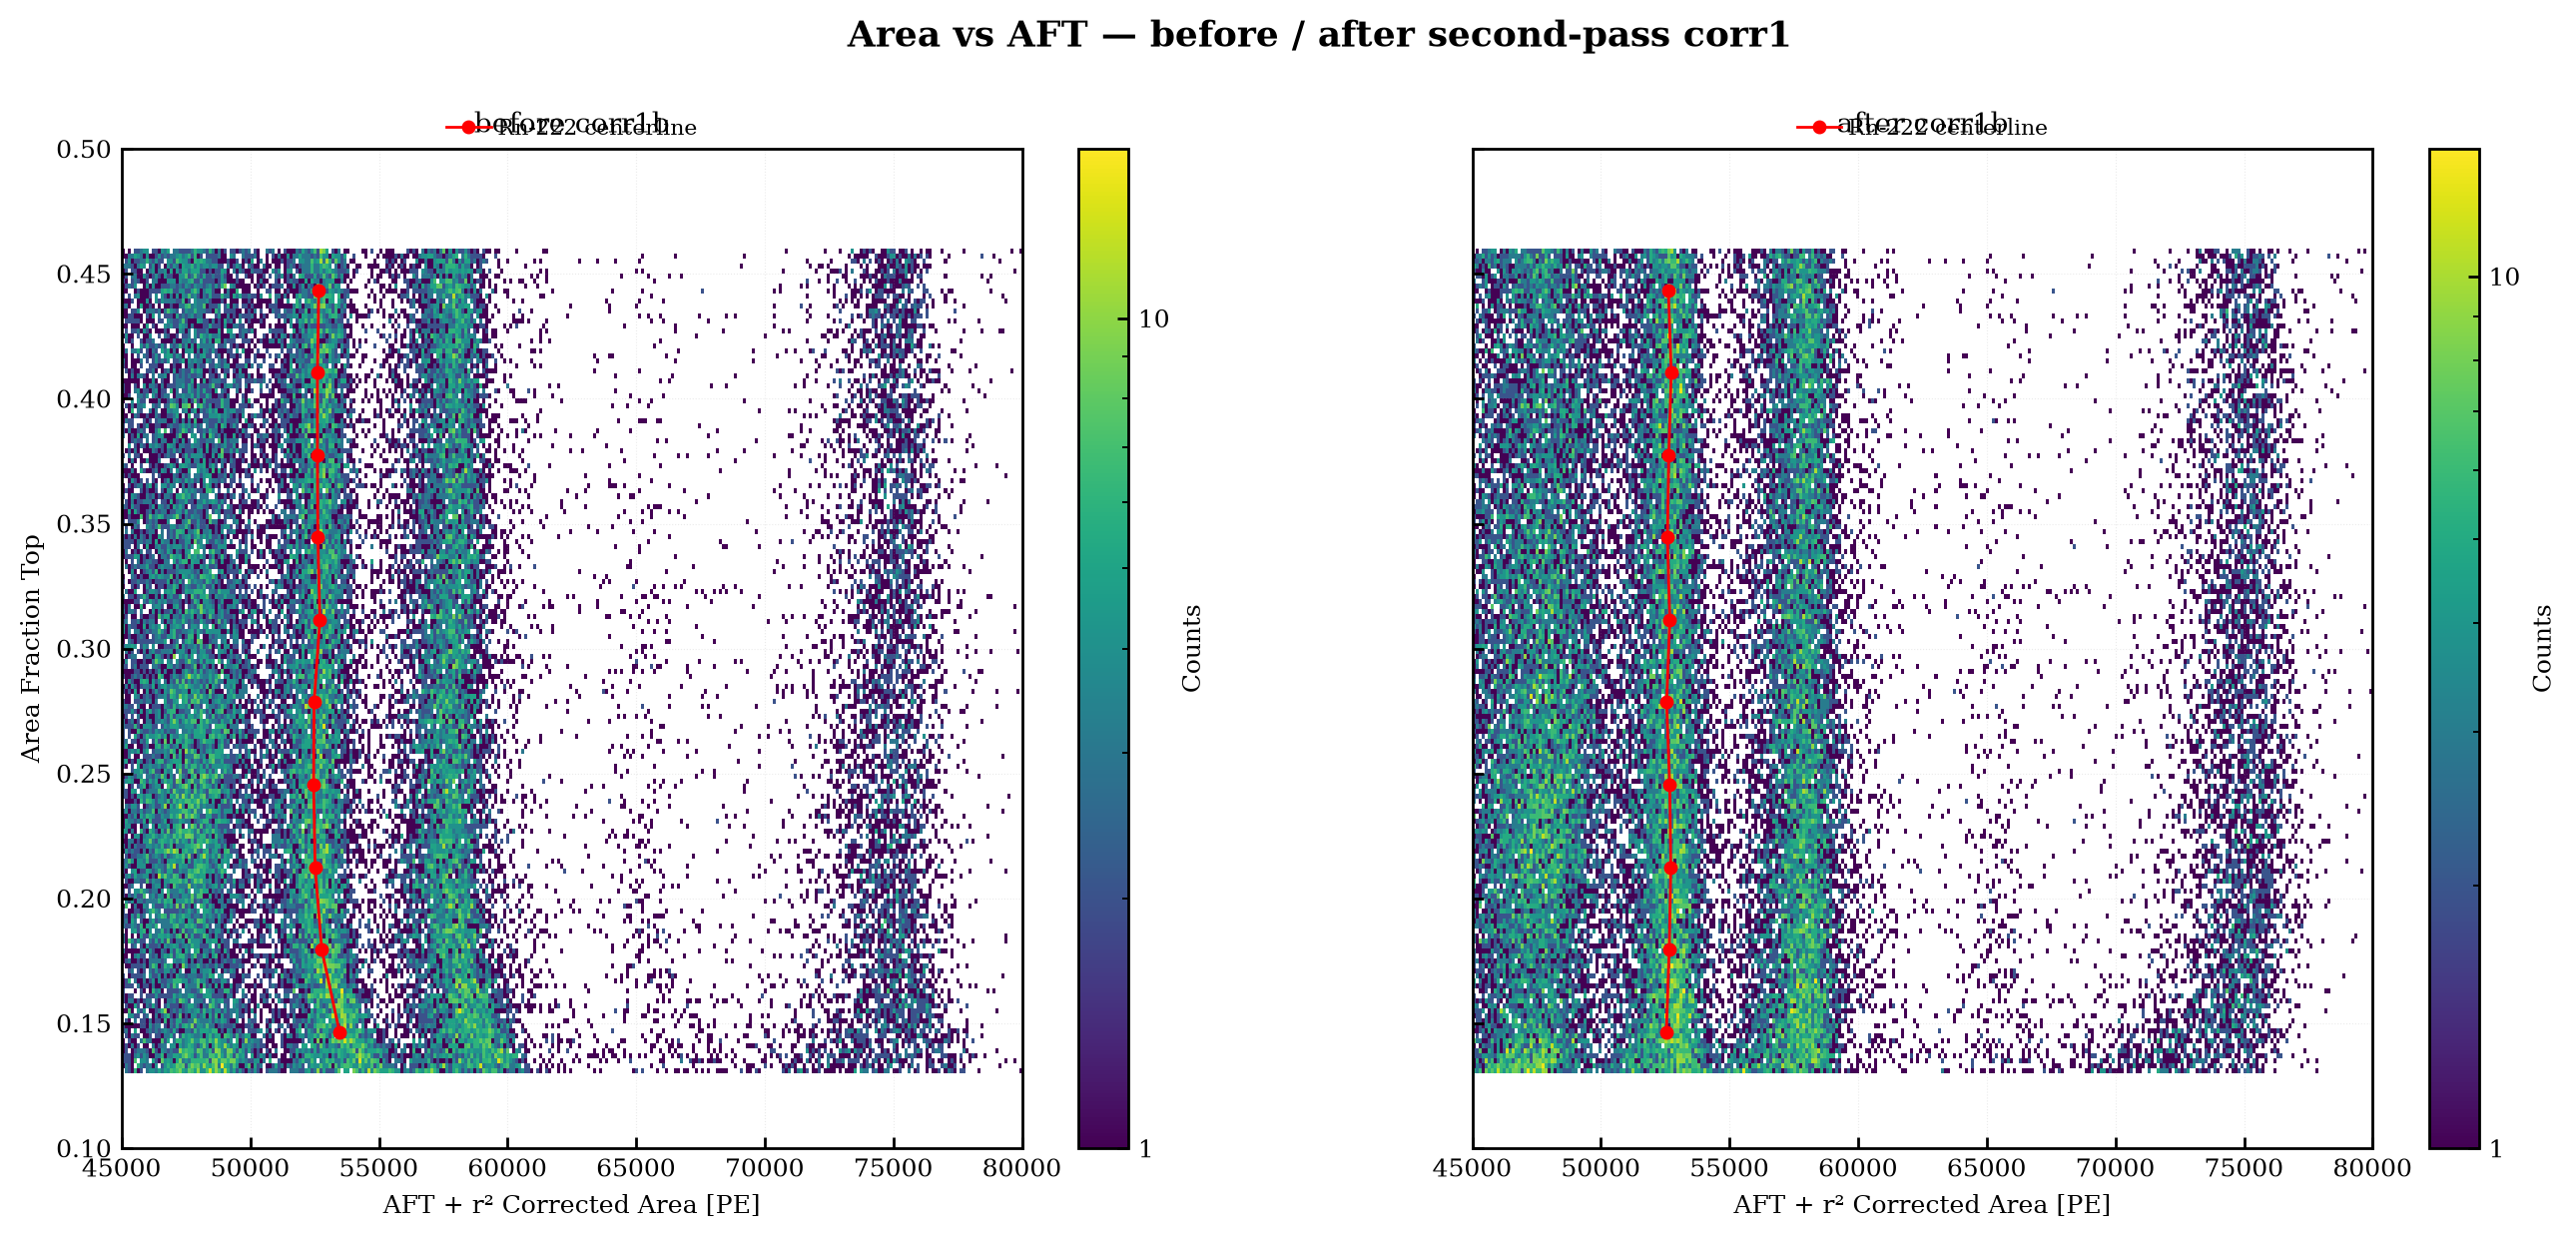

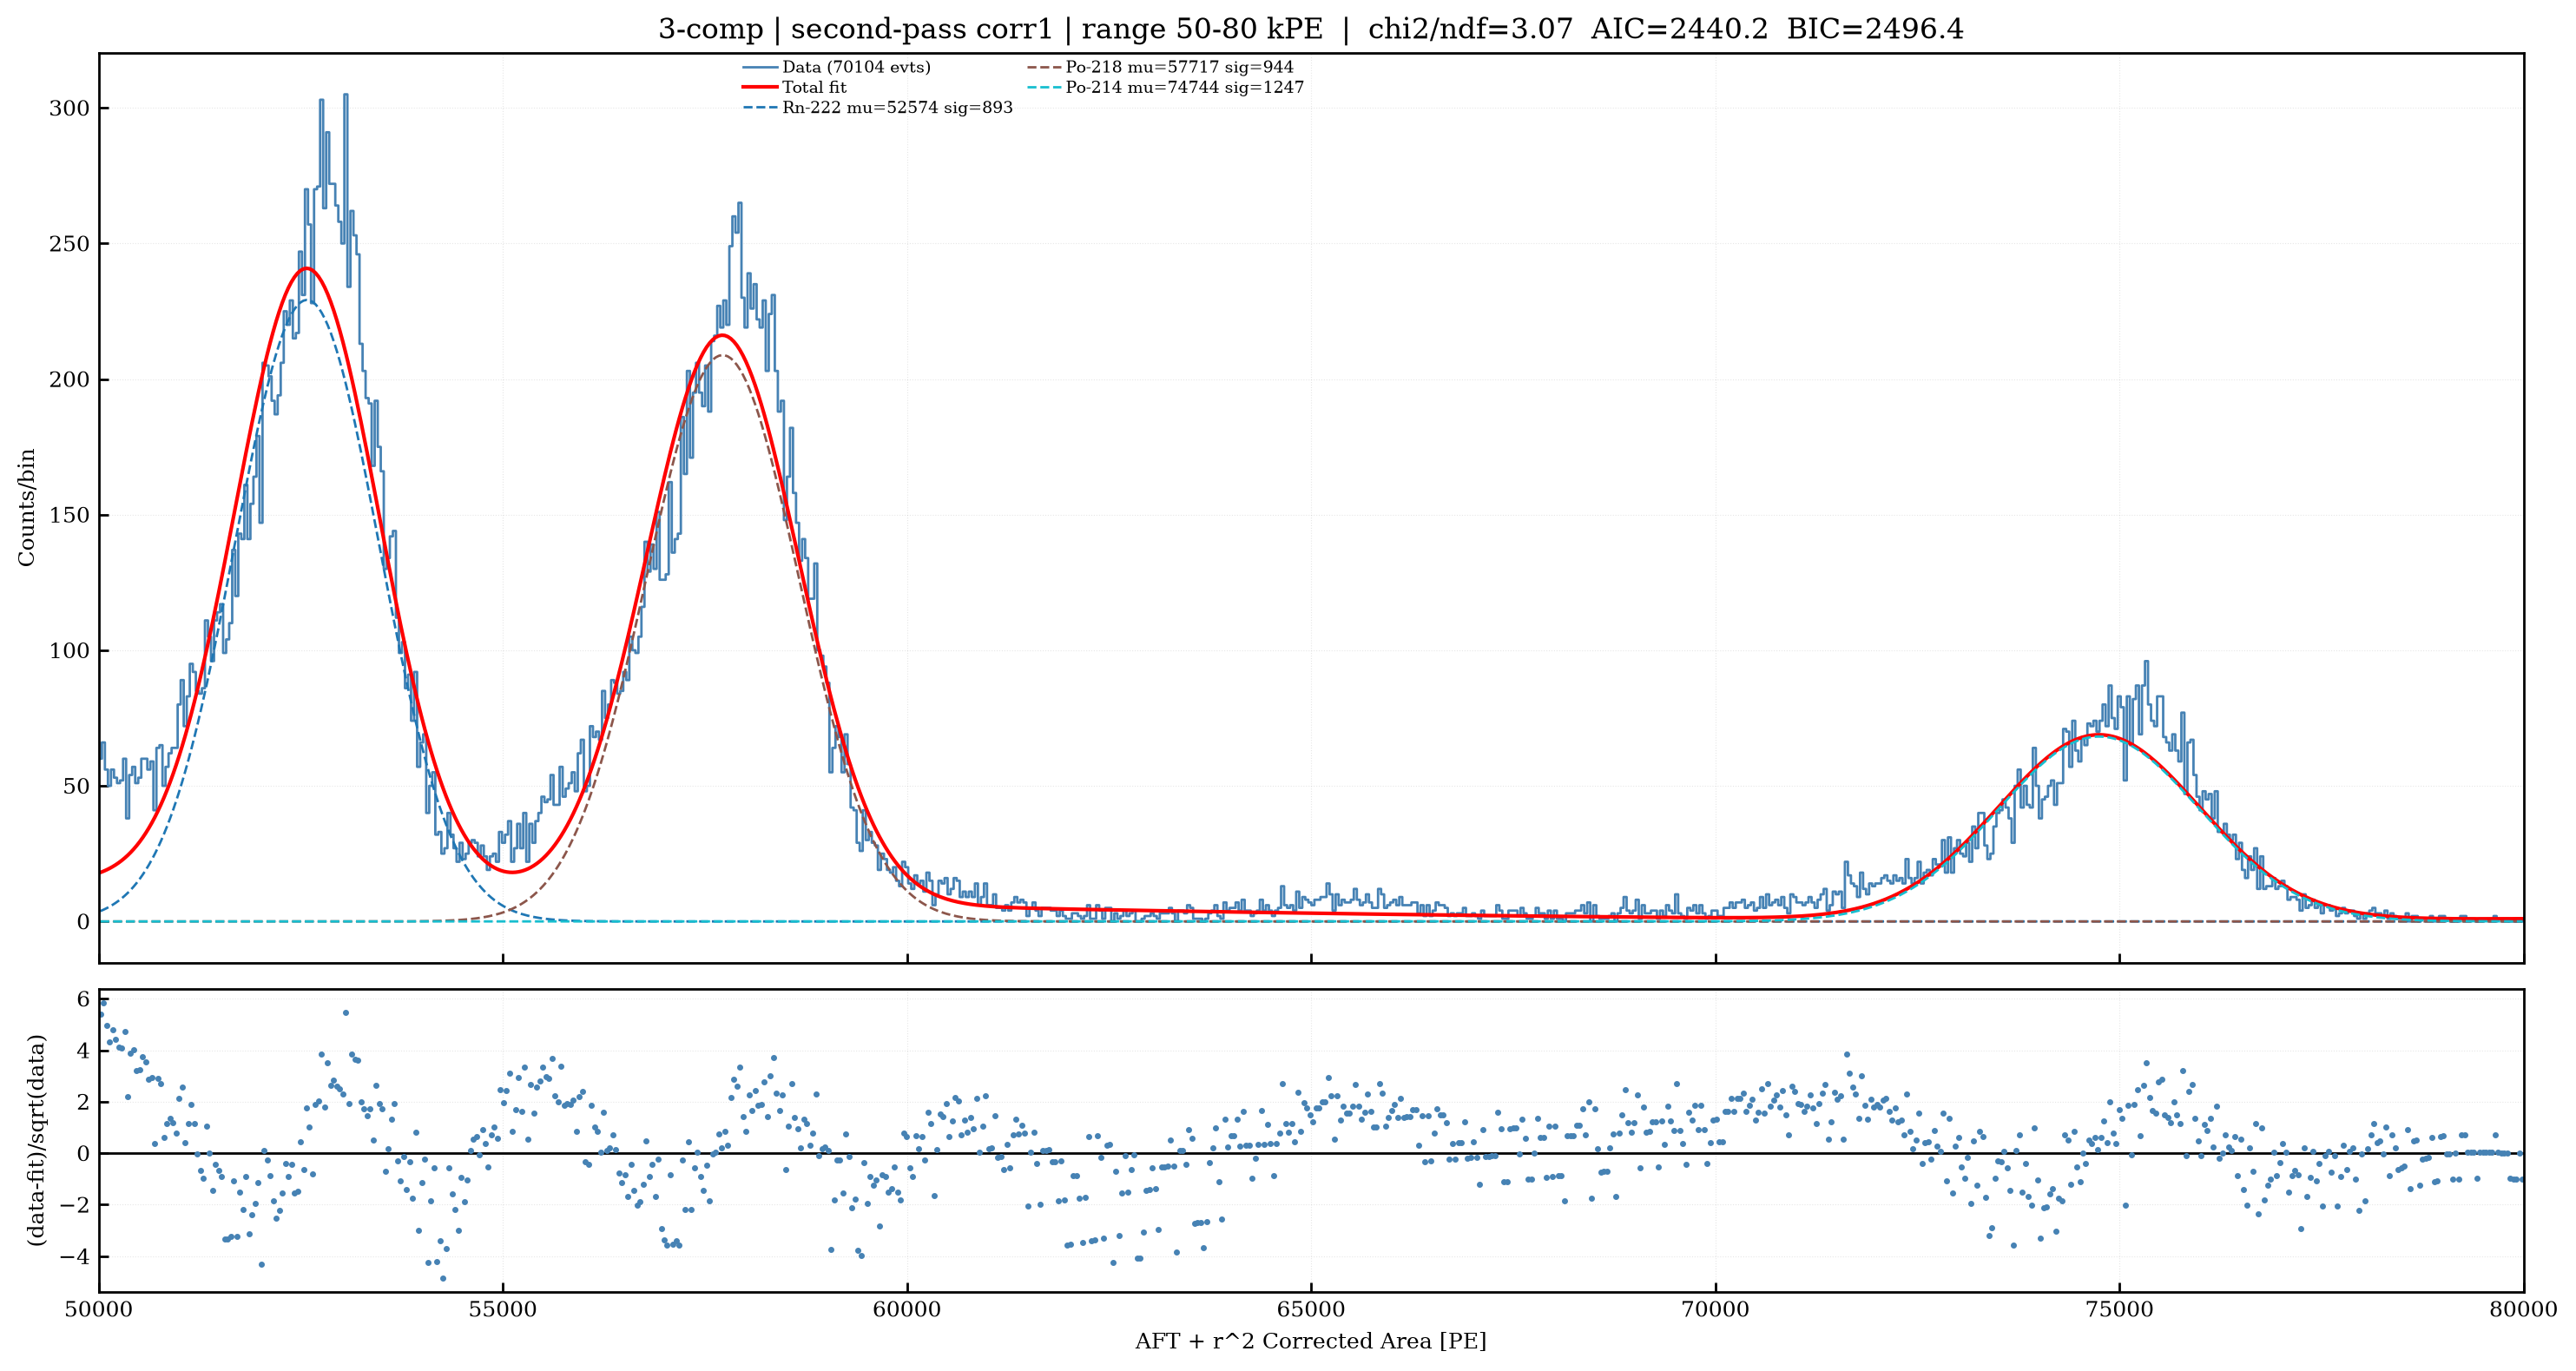

       config status  n_par  chi2/ndf    AIC    BIC  mu_Rn-222  sig_Rn-222  mu_Po-218  sig_Po-218  mu_Po-214  sig_Po-214
before corr1b     ok     12      2.31 1841.4 1897.6    52638.4       949.8    57800.0      1013.5    74813.8      1259.9
 after corr1b     ok     12      3.07 2440.2 2496.4    52574.4       893.1    57716.8       943.9    74744.5      1247.3

Wrote fit_test_corr1b_P6.csv


In [12]:
# ═══════════════════════════════════════════════════════════════
# SCHEME 3 — second-pass AFT correction on area_2_corrected
# ═══════════════════════════════════════════════════════════════
# (a) Rn-222 position vs AFT (50-57 kPE window), with fit errors
# (b) robust, error-weighted smooth residual curve
# (c) divide it out, (d) refit + before/after 2D

N_BINS_CORR = 20
edges_c = np.linspace(AFT_LO, AFT_HI, N_BINS_CORR + 1)
centers_c, mus_c, errs_c, ns_c = [], [], [], []
for lo, hi in zip(edges_c[:-1], edges_c[1:]):
    sub = ev[(ev['area_fraction_top'] >= lo) & (ev['area_fraction_top'] < hi)]
    if len(sub) < 300:
        continue
    mu, me, n = peak_position(sub, 'Rn-222')
    if np.isfinite(mu) and np.isfinite(me) and me > 0:
        centers_c.append(0.5*(lo+hi)); mus_c.append(mu); errs_c.append(me); ns_c.append(n)

centers_c = np.asarray(centers_c); mus_c = np.asarray(mus_c)
errs_c = np.asarray(errs_c); ns_c = np.asarray(ns_c)
good = np.isfinite(mus_c) & np.isfinite(errs_c) & (errs_c > 0)
if good.sum() >= 3:
    med_err = np.median(errs_c[good])
    good &= errs_c < 3.0 * med_err
deg = int(min(4, max(1, good.sum() - 1)))
w = 1.0 / np.maximum(errs_c[good], 1.0)
coef = np.polyfit(centers_c[good], mus_c[good], deg, w=w)
resid_curve = np.poly1d(coef)
mu_ref = float(resid_curve(0.30))

fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(centers_c, mus_c, yerr=errs_c, fmt='o', ms=4, capsize=2,
            color='tab:blue', label='per-bin Rn-222 mu')
xf = np.linspace(AFT_LO, AFT_HI, 300)
ax.plot(xf, resid_curve(xf), 'r-', label='poly deg %d (weighted)' % deg)
ax.axhline(mu_ref, color='k', ls='--', lw=1, label='mu(AFT=0.30)')
ax.set_xlabel('AFT'); ax.set_ylabel('Rn-222 mu [PE]')
ax.set_title('Residual AFT curve used for second-pass corr1')
ax.legend(fontsize=9); ax.grid(True, alpha=0.25)
safe_tight(fig); plt.show()

corr1b = mu_ref / np.maximum(resid_curve(ev['area_fraction_top'].values), 1.0)
ev_fit = ev.copy()
ev_fit['area_2_corrected'] = ev['area_2_corrected'].values * corr1b

# ── before/after 2D hist + Rn centerline ──
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharey=True)
for ax, d, lab in [(axes[0], ev, 'before corr1b'), (axes[1], ev_fit, 'after corr1b')]:
    h = ax.hist2d(d['area_2_corrected'], d['area_fraction_top'],
                  bins=[300, 200], range=[[45e3, 80e3], [0.10, 0.50]],
                  cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
    plt.colorbar(h[3], ax=ax, label='Counts')
    mus = []
    for lo, hi in zip(aft_edges[:-1], aft_edges[1:]):
        sub = d[(d['area_fraction_top'] >= lo) & (d['area_fraction_top'] < hi)]
        mu, me, n = peak_position(sub, 'Rn-222')
        mus.append(mu)
    mus = np.asarray(mus)
    m = np.isfinite(mus)
    ax.plot(mus[m], aft_centers[m], 'o-', color='red', ms=4, lw=1, label='Rn-222 centerline')
    ax.set_xlabel('AFT + r² Corrected Area [PE]')
    ax.set_title(lab); ax.legend(fontsize=8); ax.grid(True, alpha=0.2)
axes[0].set_ylabel('Area Fraction Top')
fig.suptitle('Area vs AFT — before / after second-pass corr1', fontsize=13, fontweight='bold')
safe_tight(fig); plt.show()

res3b = fit_spectrum(ev_fit, PEAKS_3, FIT_RANGE_DEFAULT, N_BINS_FIT, bg_deg=2)
plot_fit(res3b, '3-comp | second-pass corr1 | range %.0f-%.0f kPE' % (
    FIT_RANGE_DEFAULT[0]/1e3, FIT_RANGE_DEFAULT[1]/1e3))

cmp_b = pd.DataFrame([summary_row('before corr1b', res3),
                      summary_row('after corr1b', res3b)])
print(cmp_b.to_string(index=False))
cmp_b.to_csv('fit_test_corr1b_P6.csv', index=False)
print('\nWrote fit_test_corr1b_P6.csv')


Livetime: 1283569.1 s (356.55 h)  |  trend_per_run_P6.csv  |  403 runs

PER-BIN FIT — ev (no corr1b)  (4 bins, 915 kg/bin, LT=1283569.1 s)
           tag  bin  aft_lo  aft_hi  aft_mid  n_events  status  chi2/ndf  mu_Rn-222  sig_Rn-222  yield_Rn-222  yield_err_Rn-222  rate_Rn-222  rate_err_Rn-222  mu_Po-218  sig_Po-218  yield_Po-218  yield_err_Po-218  rate_Po-218  rate_err_Po-218  mu_Po-214  sig_Po-214  yield_Po-214  yield_err_Po-214  rate_Po-214  rate_err_Po-214
ev (no corr1b)    0  0.1300  0.2125  0.17125     22981 success      1.23    52962.9      1060.7        4319.7              65.7     3.677978         0.055961    58092.3      1103.1        4307.1              65.6     3.667268         0.055879    74793.6      1381.7        1855.4              43.1     1.579756         0.036675
ev (no corr1b)    1  0.2125  0.2950  0.25375     18359 success      1.03    52454.4       867.4        3280.4              57.3     2.793115         0.048767    57652.2       855.1        3049.6           

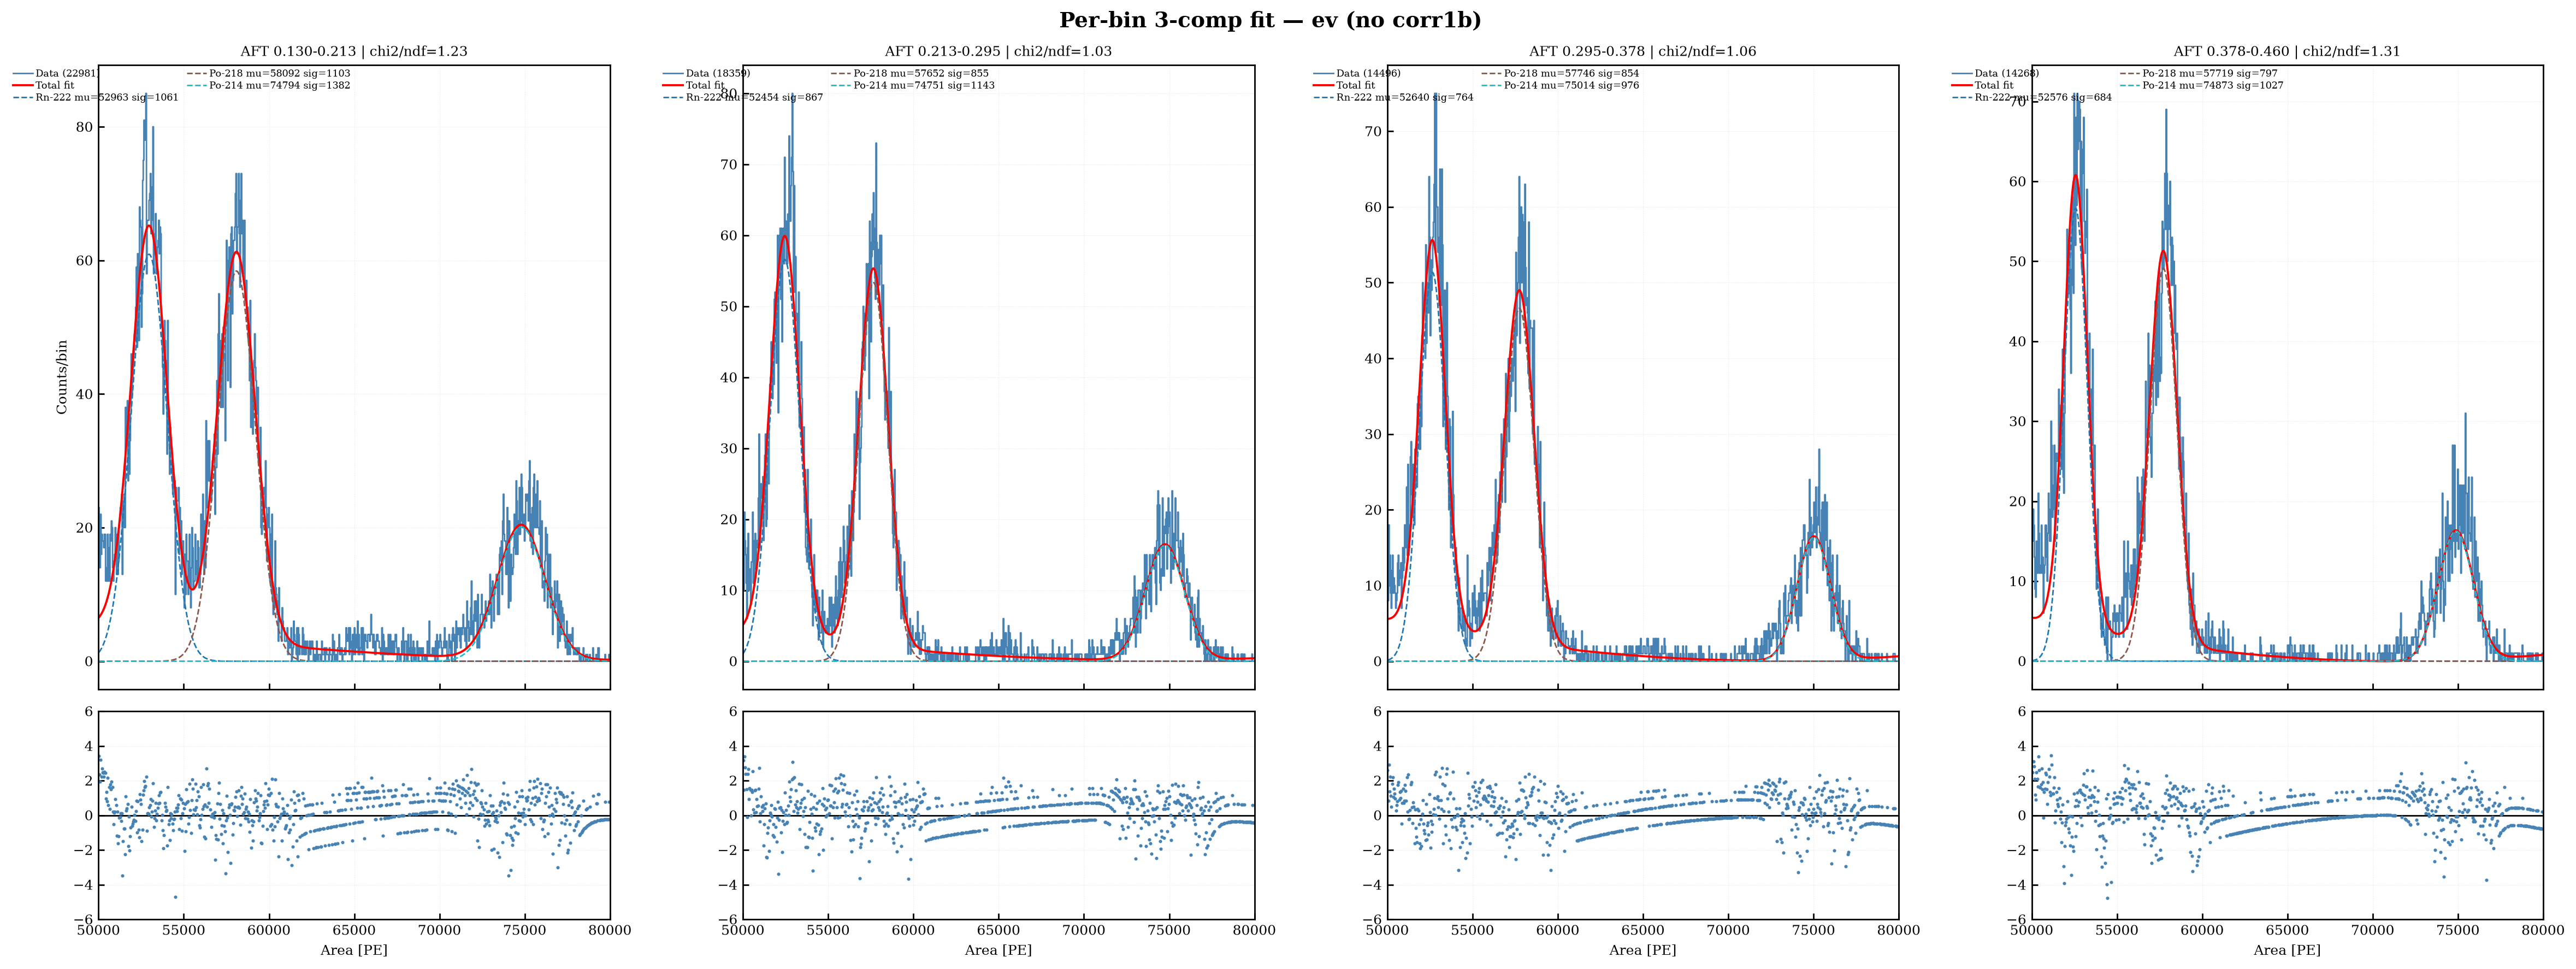

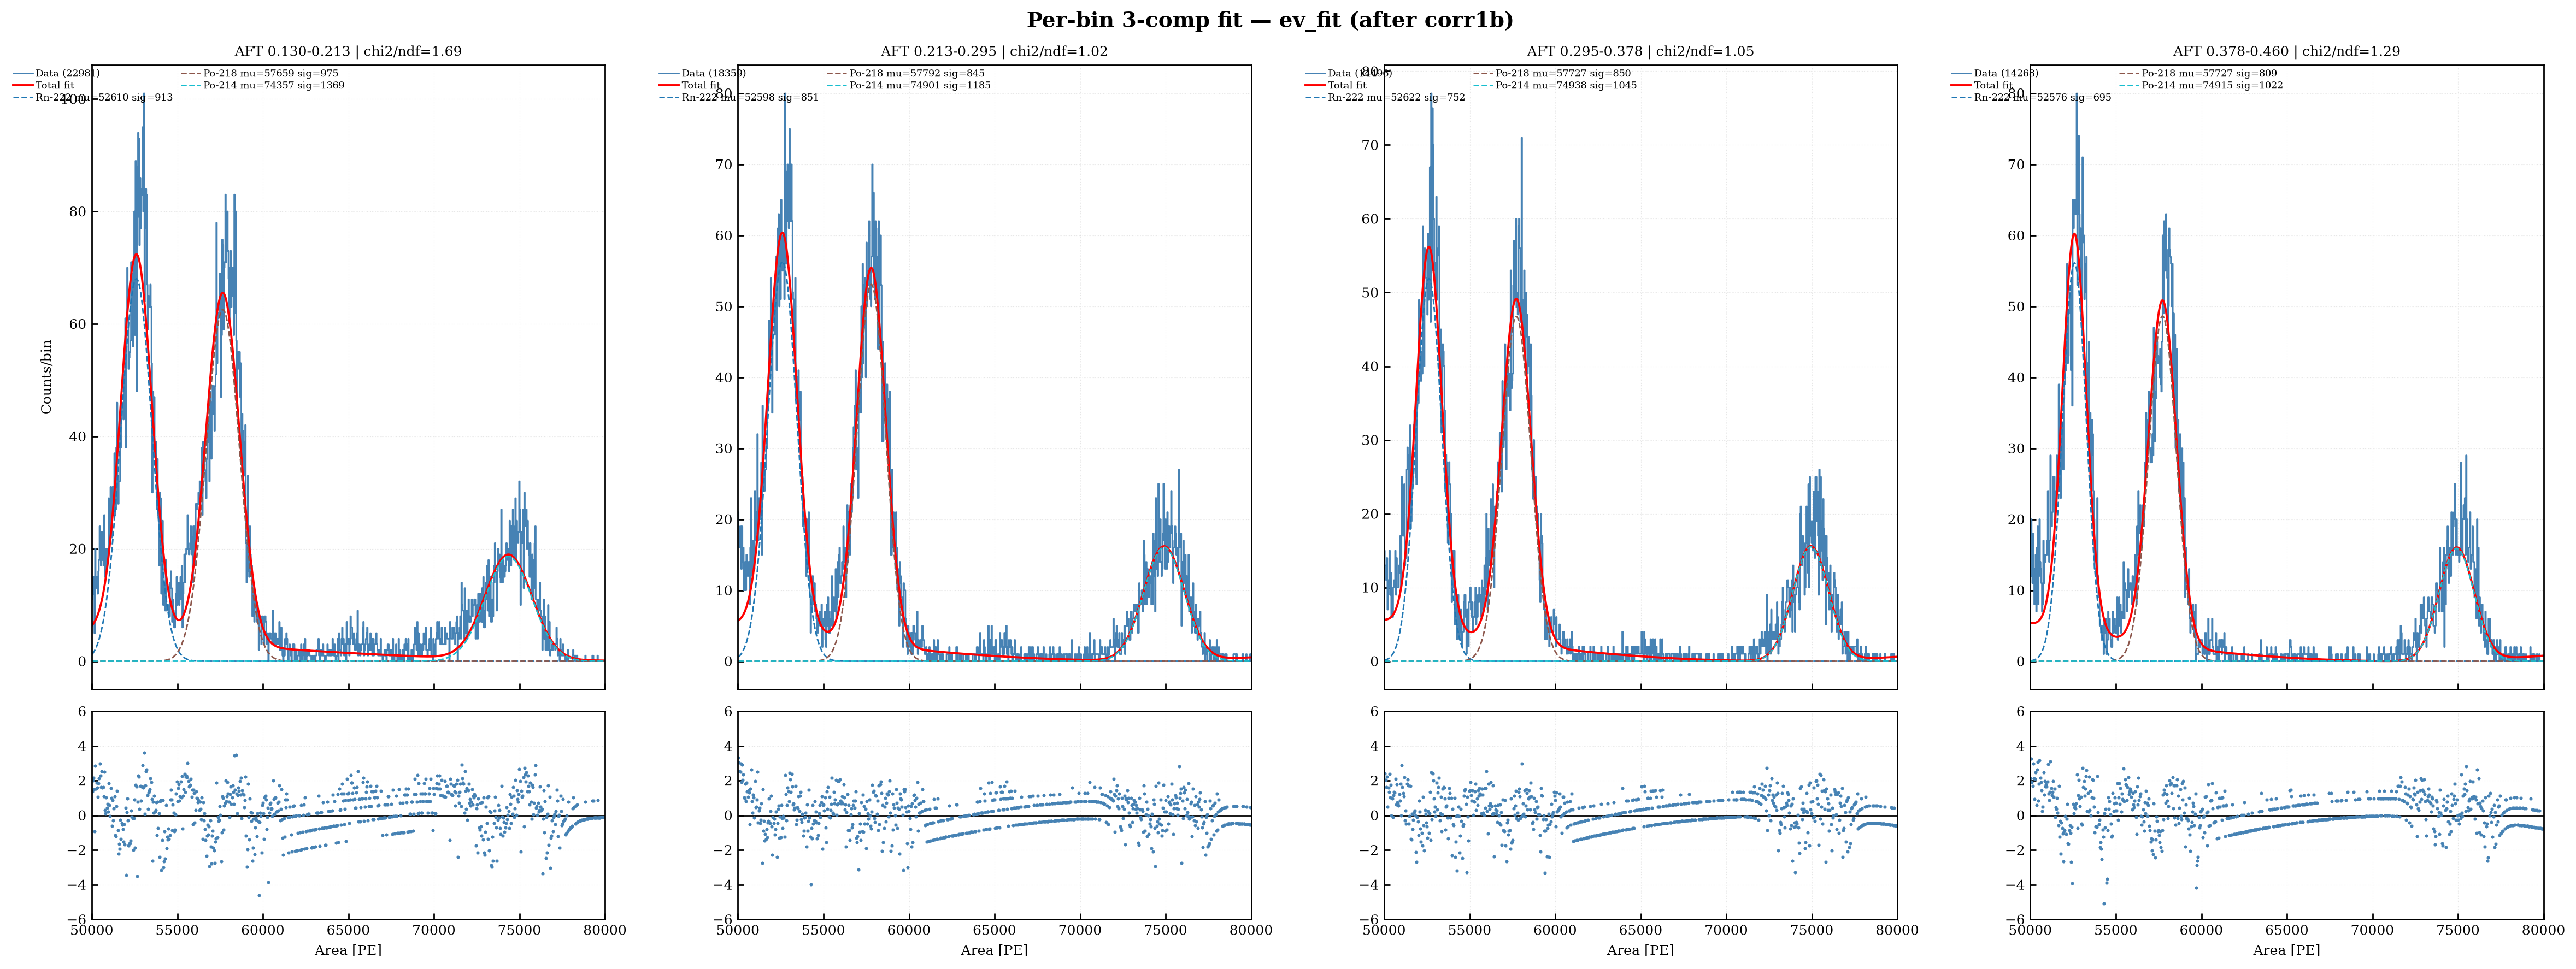

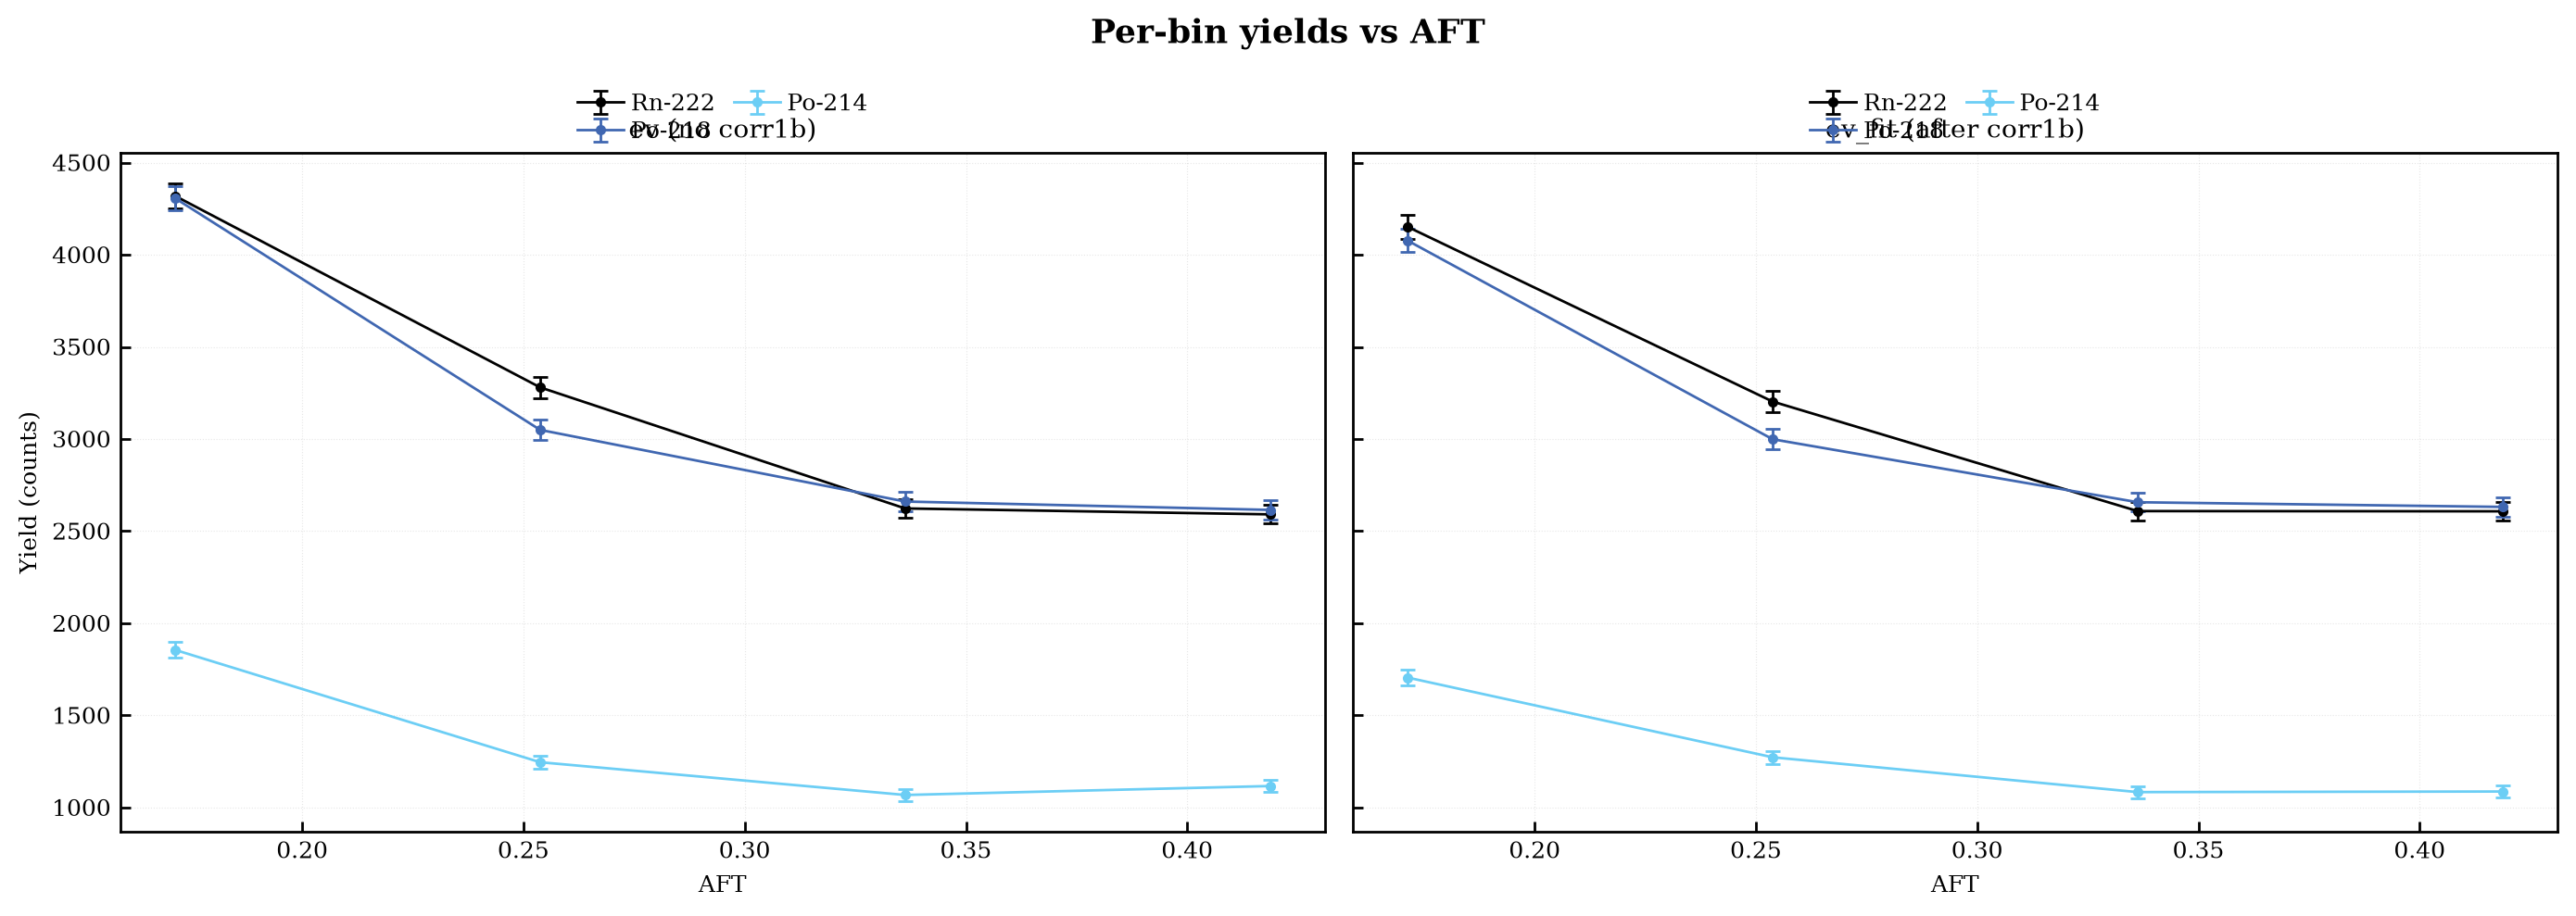

In [13]:
# ═══════════════════════════════════════════════════════════════
# SCHEME 2 — AFT-binned fit (4 bins, uniform FMass) + comparison
# ═══════════════════════════════════════════════════════════════
# per-bin fits on:
#   - ev      : no second-pass corr1 (production-style)
#   - ev_fit  : after second-pass corr1
# combined: only res3b (after corr1b)
# mass/bin = 3660/4 = 915 kg; livetime from trend_per_run_P6.csv

import os

RUNS_CSV_CANDIDATES = [
    'trend_per_run_P6.csv',
    'data/trend_per_run_P6.csv',
    '/project2/lgrandi/jietang/sr3_commissioning/trend_per_run_P6.csv',
]
RUNS_CSV = next((p for p in RUNS_CSV_CANDIDATES if os.path.exists(p)), None)
if RUNS_CSV is None:
    raise FileNotFoundError('trend_per_run_P6.csv not found; update RUNS_CSV_CANDIDATES')

_runs = pd.read_csv(RUNS_CSV).drop_duplicates('run')
TOTAL_LIVETIME_S = float(_runs['livetime_s'].sum())
print('Livetime: %.1f s (%.2f h)  |  %s  |  %d runs'
      % (TOTAL_LIVETIME_S, TOTAL_LIVETIME_S/3600, RUNS_CSV, _runs['run'].nunique()))

N_AFT_FIT_BINS = 4
MASS_TOTAL_KG = 3660.0
MASS_BIN_KG = MASS_TOTAL_KG / N_AFT_FIT_BINS
BIN_WIDTH_PE = (FIT_RANGE_DEFAULT[1] - FIT_RANGE_DEFAULT[0]) / N_BINS_FIT
ISO_NAMES = [p[0] for p in PEAKS_3]


def gauss_yield(res, i):
    """Gaussian integral in counts = amp*sig*sqrt(2pi)/bin_width."""
    return float(res['amp'][i] * res['sigma'][i] * np.sqrt(2*np.pi) / BIN_WIDTH_PE)


def run_binned_fit(events, tag):
    edges = np.linspace(AFT_LO, AFT_HI, N_AFT_FIT_BINS + 1)
    items, rows = [], []
    for j, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
        sub = events[(events['area_fraction_top'] >= lo) & (events['area_fraction_top'] < hi)]
        r = fit_spectrum(sub, PEAKS_3, FIT_RANGE_DEFAULT, N_BINS_FIT, bg_deg=2)
        items.append({'bin': j, 'lo': lo, 'hi': hi, 'aft_mid': 0.5*(lo+hi),
                      'n_events': len(sub), 'res': r})
        row = {'tag': tag, 'bin': j, 'aft_lo': lo, 'aft_hi': hi, 'aft_mid': 0.5*(lo+hi),
               'n_events': len(sub), 'status': r.get('status'),
               'chi2/ndf': (round(r['chi2_ndf'], 2) if r.get('success') else np.nan)}
        if r.get('success'):
            for i, iso in enumerate(ISO_NAMES):
                y = gauss_yield(r, i)
                e = float(np.sqrt(max(y, 1.0)))
                row['mu_'+iso] = round(float(r['mu'][i]), 1)
                row['sig_'+iso] = round(float(r['sigma'][i]), 1)
                row['yield_'+iso] = round(y, 1)
                row['yield_err_'+iso] = round(e, 1)
                row['rate_'+iso] = y / (MASS_BIN_KG * TOTAL_LIVETIME_S) * 1e6
                row['rate_err_'+iso] = e / (MASS_BIN_KG * TOTAL_LIVETIME_S) * 1e6
        rows.append(row)

    df = pd.DataFrame(rows)
    print('\n' + '='*100)
    print('PER-BIN FIT — %s  (4 bins, %.0f kg/bin, LT=%.1f s)' % (tag, MASS_BIN_KG, TOTAL_LIVETIME_S))
    print('='*100)
    print(df.to_string(index=False))

    r0 = df[df['bin'] == 0].iloc[0]
    bad0 = (r0['status'] != 'success') or (np.isfinite(r0['chi2/ndf']) and r0['chi2/ndf'] > 2.0)
    if bad0:
        print('\nWARNING: lowest AFT bin (%.3f-%.3f) chi2/ndf=%s — looks non-Gaussian; '
              'keeping 4 bins for now.' % (r0['aft_lo'], r0['aft_hi'], r0['chi2/ndf']))
    return df, items


binfit_ev, items_ev = run_binned_fit(ev, 'ev (no corr1b)')
binfit_evfit, items_evfit = run_binned_fit(ev_fit, 'ev_fit (after corr1b)')

# ── combined (only after corr1b) vs per-bin sums ──
rows = []
for i, iso in enumerate(ISO_NAMES):
    yc = gauss_yield(res3b, i) if res3b.get('success') else np.nan
    ec = float(np.sqrt(max(yc, 1.0))) if np.isfinite(yc) else np.nan
    for label, df in [('combined (corr1b)', None),
                      ('per-bin ev', binfit_ev),
                      ('per-bin ev_fit', binfit_evfit)]:
        if df is None:
            y, e = yc, ec
        elif 'yield_'+iso in df.columns:
            y = float(df['yield_'+iso].fillna(0).sum())
            e = float(np.sqrt((df['yield_err_'+iso].fillna(0)**2).sum()))
        else:
            y, e = np.nan, np.nan
        rows.append({'method': label, 'isotope': iso, 'yield': y, 'yield_err': e,
                     'rate_ukgb': y / (MASS_TOTAL_KG * TOTAL_LIVETIME_S) * 1e6,
                     'rate_err_ukgb': e / (MASS_TOTAL_KG * TOTAL_LIVETIME_S) * 1e6})

comp = pd.DataFrame(rows)
print('\n' + '='*100)
print('COMBINED vs PER-BIN  (rate = yield / (3660 kg * livetime))')
print('='*100)
print(comp.round(3).to_string(index=False))
comp.to_csv('fit_test_combined_vs_perbin_P6.csv', index=False)
print('\nWrote fit_test_combined_vs_perbin_P6.csv')


# ── 2×4 fit + pull grid ──
def plot_binned_grid(items, tag):
    n = len(items)
    fig, axes = plt.subplots(2, n, figsize=(6*n, 9), sharex=True,
                             gridspec_kw={'height_ratios': [3, 1]})
    if n == 1:
        axes = np.asarray(axes).reshape(2, 1)
    colors = plt.cm.tab10(np.linspace(0, 1, len(PEAKS_3)))

    for j, item in enumerate(items):
        ax, axp = axes[0, j], axes[1, j]
        r = item['res']
        if not r.get('success'):
            ax.text(0.5, 0.55, 'fit failed\n%s' % r.get('status'),
                    ha='center', va='center', transform=ax.transAxes, fontsize=9)
            ax.set_title('AFT %.3f-%.3f | FAILED' % (item['lo'], item['hi']), fontsize=9)
            axp.axhline(0, color='k', lw=1)
            continue

        c, y, m = r['centers'], r['counts'], r['model']
        ax.step(c, y, where='mid', color='steelblue', lw=1.0,
                label='Data (%d)' % r['n_events'])
        ax.plot(c, m, 'r-', lw=1.4, label='Total fit')
        for i, spec in enumerate(PEAKS_3):
            g = _gauss(c, r['amp'][i], r['mu'][i], r['sigma'][i])
            ax.plot(c, g, '--', color=colors[i], lw=1.0,
                    label='%s mu=%.0f sig=%.0f' % (spec[0], r['mu'][i], r['sigma'][i]))
        ax.set_title('AFT %.3f-%.3f | chi2/ndf=%.2f' % (item['lo'], item['hi'], r['chi2_ndf']),
                     fontsize=9)
        ax.legend(fontsize=6.5, loc='upper right')
        ax.grid(True, alpha=0.25)
        ax.set_ylabel('Counts/bin' if j == 0 else '')

        pull = (y - m) / np.sqrt(np.maximum(y, 1))
        axp.axhline(0, color='k', lw=1)
        axp.plot(c, pull, 'o', ms=1.2, color='steelblue')
        axp.set_ylim(-6, 6)
        axp.set_xlabel('Area [PE]')
        axp.grid(True, alpha=0.25)
        axp.set_xlim(FIT_RANGE_DEFAULT)

    fig.suptitle('Per-bin 3-comp fit — %s' % tag, fontsize=14, fontweight='bold')
    safe_tight(fig); plt.show()


plot_binned_grid(items_ev, 'ev (no corr1b)')
plot_binned_grid(items_evfit, 'ev_fit (after corr1b)')

# ── yield vs AFT summary ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, df, tag in [(axes[0], binfit_ev, 'ev (no corr1b)'),
                    (axes[1], binfit_evfit, 'ev_fit (after corr1b)')]:
    for iso in ISO_NAMES:
        col, ecol = 'yield_'+iso, 'yield_err_'+iso
        if col in df.columns:
            ax.errorbar(df['aft_mid'], df[col], yerr=df[ecol],
                        fmt='o-', capsize=3, label=iso)
    ax.set_xlabel('AFT')
    ax.set_ylabel('Yield (counts)' if ax is axes[0] else '')
    ax.set_title(tag)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.25)

fig.suptitle('Per-bin yields vs AFT', fontsize=13, fontweight='bold')
safe_tight(fig); plt.show()


### How to read the AFT study

- **Step 0**: if the three r² slices overlap and all tilt at low AFT → AFT-only residual
  (scheme 3 has a good chance). If they separate → 2D/wall effect; scheme 1/2 are safer.
- **Scheme 1**: look for `chi2/ndf` and residual shape improving as AFT_MIN rises.
  `FMASS_kg` uses the uniform-mass assumption.
- **Scheme 3**: compare `before corr1b` vs `after corr1b`; if the right-tail pull disappears,
  this is the preferred fix (no mass loss).
- **Scheme 2**: 4 AFT bins, 915 kg/bin. Per-bin fits are run on both `ev` and `ev_fit`;
  the comparison table gives combined (corr1b) vs per-bin sums. This is the production-style
  estimator: total rate = Σ yield / (3660 kg · livetime).


## Fit diagnosis & v2 fit (drift correction + Poisson likelihood)

Why the 3-comp Gaussian sits **low and shifted** w.r.t. the data:

1. **The combined peak is a mixture, not a Gaussian.** The light yield drifts in time
   (daily Rn-222 mu: 52.47k → 53.11k → 51.18k; on 09-17..19 Po-218/Po-214 sit on their
   absolute lower bounds), and mu/sigma still depend on AFT (lowest bin +900 PE, sigma 1060 → 684).
   Daily sigma ≈ 700, combined sigma ≈ 950. Summing shifted Gaussians with different widths gives a sharp core with
   broad shoulders: a single Gaussian then has a lower peak, a larger sigma, and a mu pulled toward the heavier side.
2. **Neyman chi2** (`sigma=sqrt(counts)`, 37.5 PE bins) biases amplitudes low.
3. **Model degeneracies:** Q-values for Rn-222/Po-218/Po-214 but alpha energies for Rn-220/Po-216.
   The true Rn-220 position (~60.5–61k) is outside its bound (58–60k), so "Rn-220" collapses onto Po-218 as a shape patch.
   Free sigma per peak plus a free quadratic bg trade off against the tails, and Po-210 (~48–51k) is not modelled at the 50k edge.
4. **Rate:** a fixed ±2σ window taken from the combined fit loses up to ~25% (Rn-222) and more (Po-218/Po-214) on the drifted days.
   It also has no acceptance, background or leakage correction.

Cells below:

- **A**: per-day window capture plus a log-scale view.
- **B**: time light-yield correction → `area_3`.
- **C**: `fit_spectrum_v2` (binned Poisson NLL via iminuit, yields as parameters, one alpha-energy table,
  relative mu bounds, linked sigma, Po-210, optional core+halo / EMG tail). Default `V2_DEFAULT`.
- **D**: ±2σ rate with acceptance + leakage correction, plus an AFT-binned cross-check.
- **E**: comparison table, daily window check, and toy-MC bias check.

       day  n_events  capture_Rn-222  at_bound_Rn-222  capture_Po-218  at_bound_Po-218  capture_Po-214  at_bound_Po-214
2026-09-03      1624           1.043            False           1.032            False           0.955            False
2026-09-04      3696           1.043            False           1.037            False           1.024            False
2026-09-05      4713           1.037            False           1.036            False           1.026            False
2026-09-06      4597           1.045            False           1.038            False           1.040            False
2026-09-07      4851           1.040            False           1.036            False           1.038            False
2026-09-08      4728           1.042            False           1.033            False           1.034            False
2026-09-09      4677           1.039            False           1.040            False           1.031            False
2026-09-10      4644           1.040    

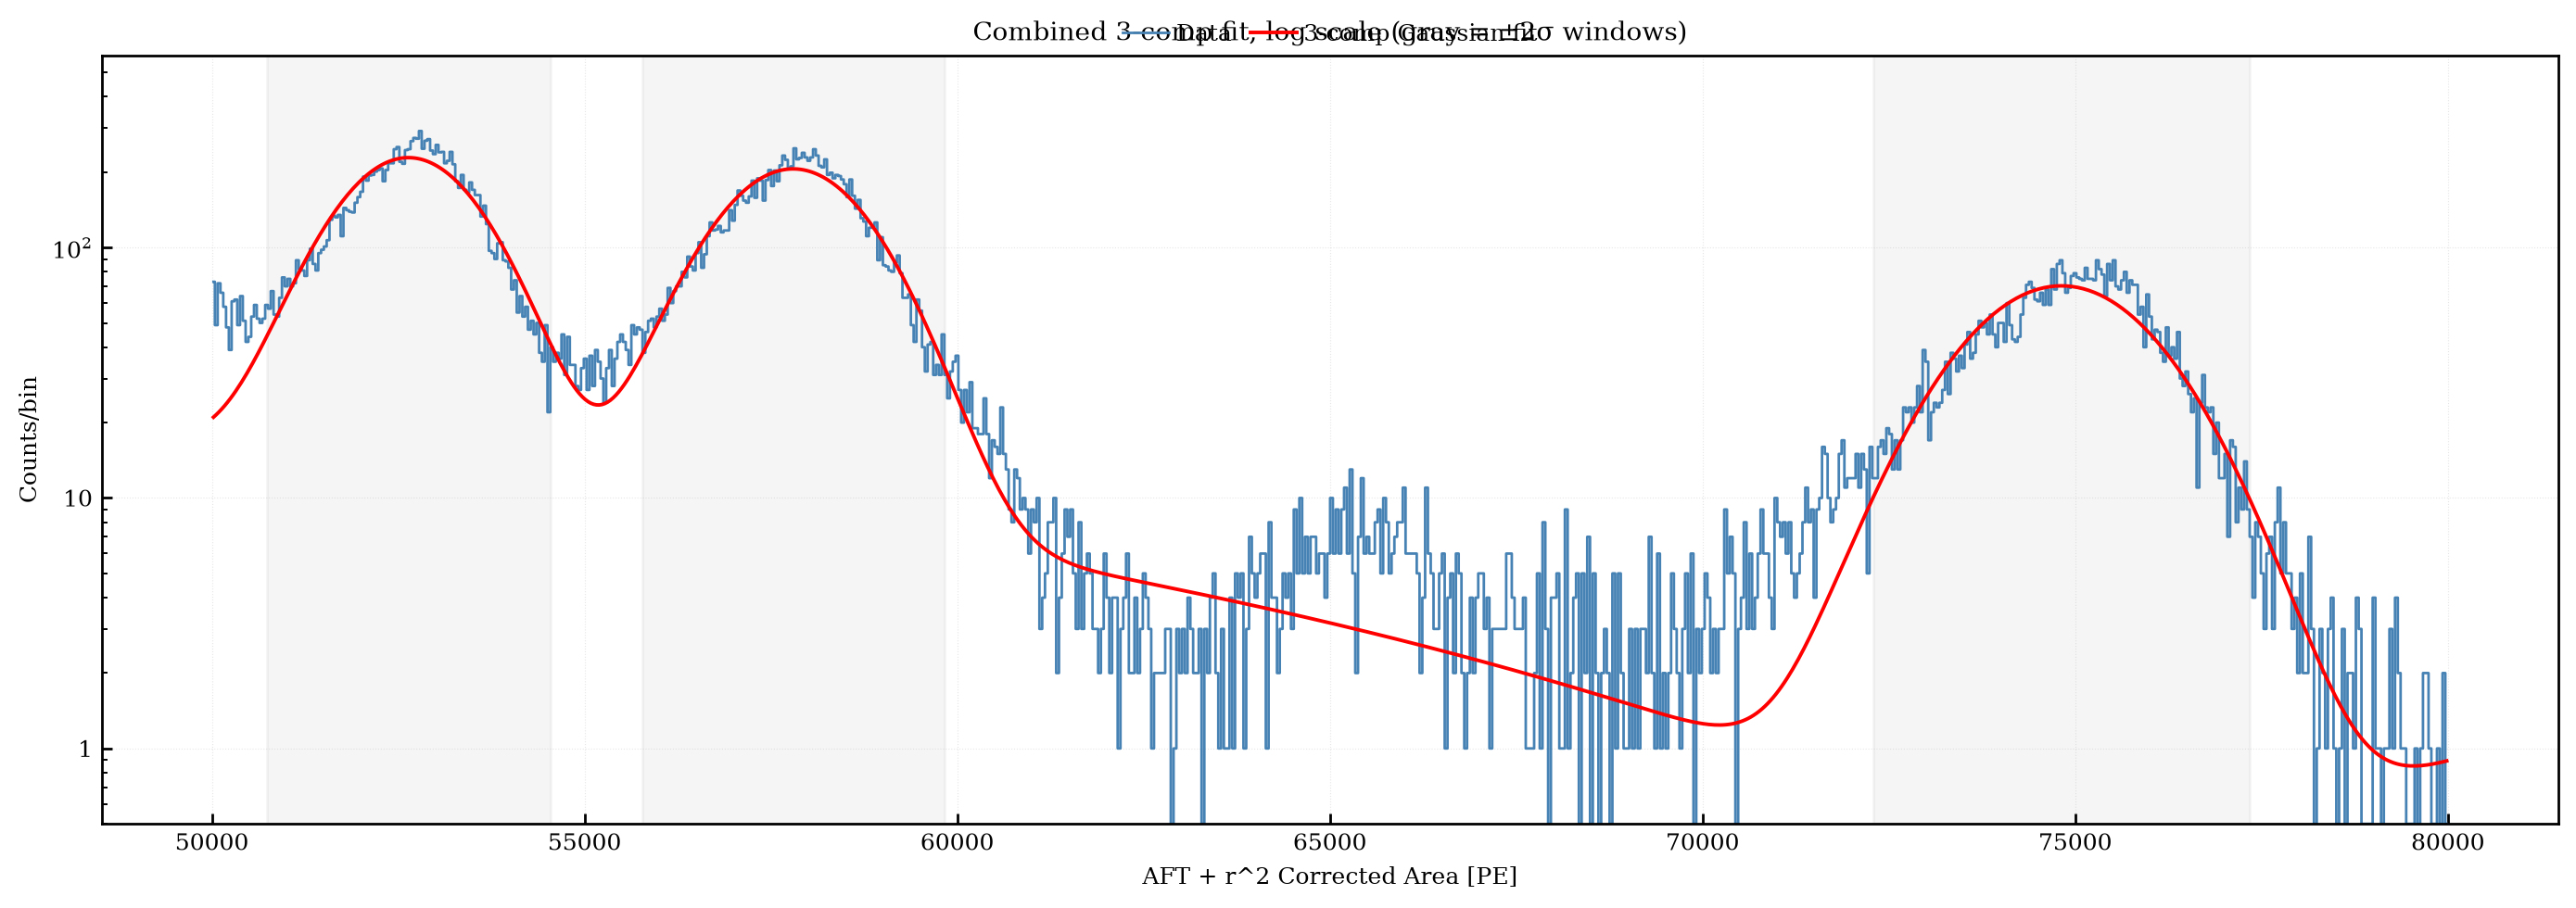

In [14]:
# ═══════════════════════════════════════════════════════════════
# CELL A — DRIFT DIAGNOSTIC: fixed ±2σ window vs the daily peaks
# ═══════════════════════════════════════════════════════════════
# capture = fraction of each day's Gaussian (daily-fit mu/sigma) inside the
# combined-fit ±2σ window, divided by 0.9545 (1.0 = nothing lost).
from scipy.stats import norm

ACC_2SIG = norm.cdf(2) - norm.cdf(-2)

def window_capture(mu_day, sig_day, mu_w, sig_w, n_sig=2.0):
    lo, hi = mu_w - n_sig*sig_w, mu_w + n_sig*sig_w
    return norm.cdf(hi, mu_day, sig_day) - norm.cdf(lo, mu_day, sig_day)

rows = []
for _, d in daily[daily['status'] == 'ok'].iterrows():
    row = {'day': d['day'], 'n_events': d['n_events']}
    for k, spec in enumerate(PEAKS_3):
        iso, (mlo, mhi) = spec[0], spec[3]
        mu_d, sig_d = d['mu_'+iso], d['sig_'+iso]
        row['capture_'+iso] = round(window_capture(mu_d, sig_d, res3['mu'][k], res3['sigma'][k]) / ACC_2SIG, 3)
        row['at_bound_'+iso] = bool(min(abs(mu_d - mlo), abs(mu_d - mhi)) < 1.0)
    rows.append(row)

drift_diag = pd.DataFrame(rows)
print(drift_diag.to_string(index=False))

# ── combined fit on a log scale: core vs shoulders/tails ──
fig, ax = plt.subplots(figsize=(14, 5))
c, y, m = res3['centers'], res3['counts'], res3['model']
ax.step(c, np.maximum(y, 0.5), where='mid', color='steelblue', lw=1.0, label='Data')
ax.plot(c, m, 'r-', lw=1.4, label='3-comp Gaussian fit')
for k, spec in enumerate(PEAKS_3):
    ax.axvspan(res3['mu'][k] - 2*res3['sigma'][k], res3['mu'][k] + 2*res3['sigma'][k],
               color='gray', alpha=0.08)
ax.set_yscale('log'); ax.set_ylim(0.5, y.max()*2)
ax.set_xlabel('AFT + r^2 Corrected Area [PE]'); ax.set_ylabel('Counts/bin')
ax.set_title('Combined 3-comp fit, log scale (gray = ±2σ windows)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.25)
safe_tight(fig); plt.show()

17 chunks of 24 h
 chunk  n_events  chi2_ndf  mu_Rn-222  mu_Po-218  mu_Po-214  ratio_Rn-222  ratio_Po-218  ratio_Po-214  scale
 20699      1624    0.5658 52405.1969 57573.3070 74213.7755        0.9959        0.9966        0.9924 0.9960
 20700      3696    0.8314 52545.4012 57684.4915 74827.9768        0.9986        0.9986        1.0007 0.9989
 20701      4713    0.8370 52675.8841 57859.8817 74846.8576        1.0011        1.0016        1.0009 1.0013
 20702      4597    0.8589 52698.8889 57818.4181 75147.4741        1.0015        1.0009        1.0049 1.0019
 20703      4851    1.0109 52755.0402 57918.0388 74928.1128        1.0026        1.0026        1.0020 1.0025
 20704      4728    0.8667 52748.6399 57913.7455 75036.2150        1.0024        1.0025        1.0034 1.0027
 20705      4677    0.9608 52818.0836 57927.8497 75063.9168        1.0038        1.0028        1.0038 1.0034
 20706      4644    0.8300 52859.4213 57976.2360 75093.9793        1.0045        1.0036        1.0042 1.0041
 

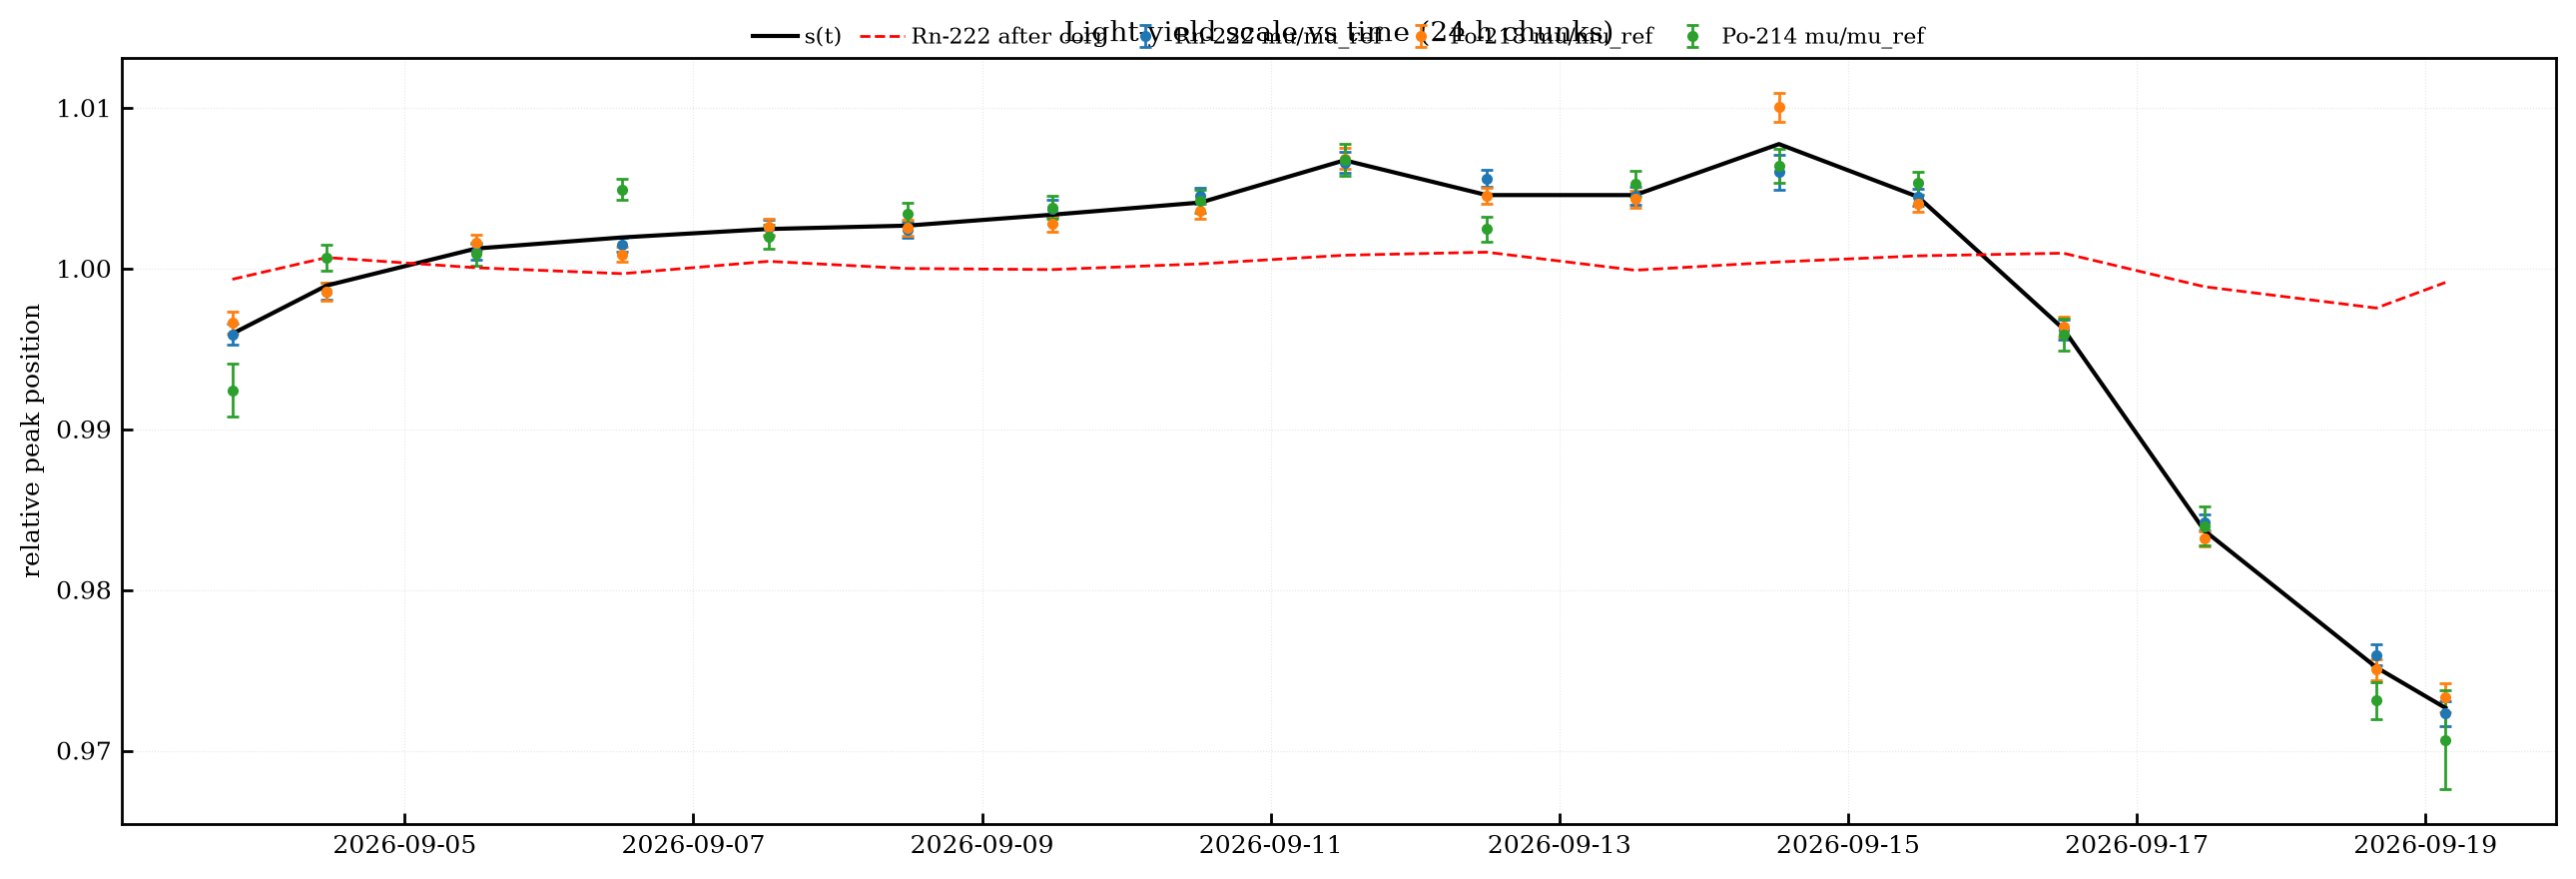

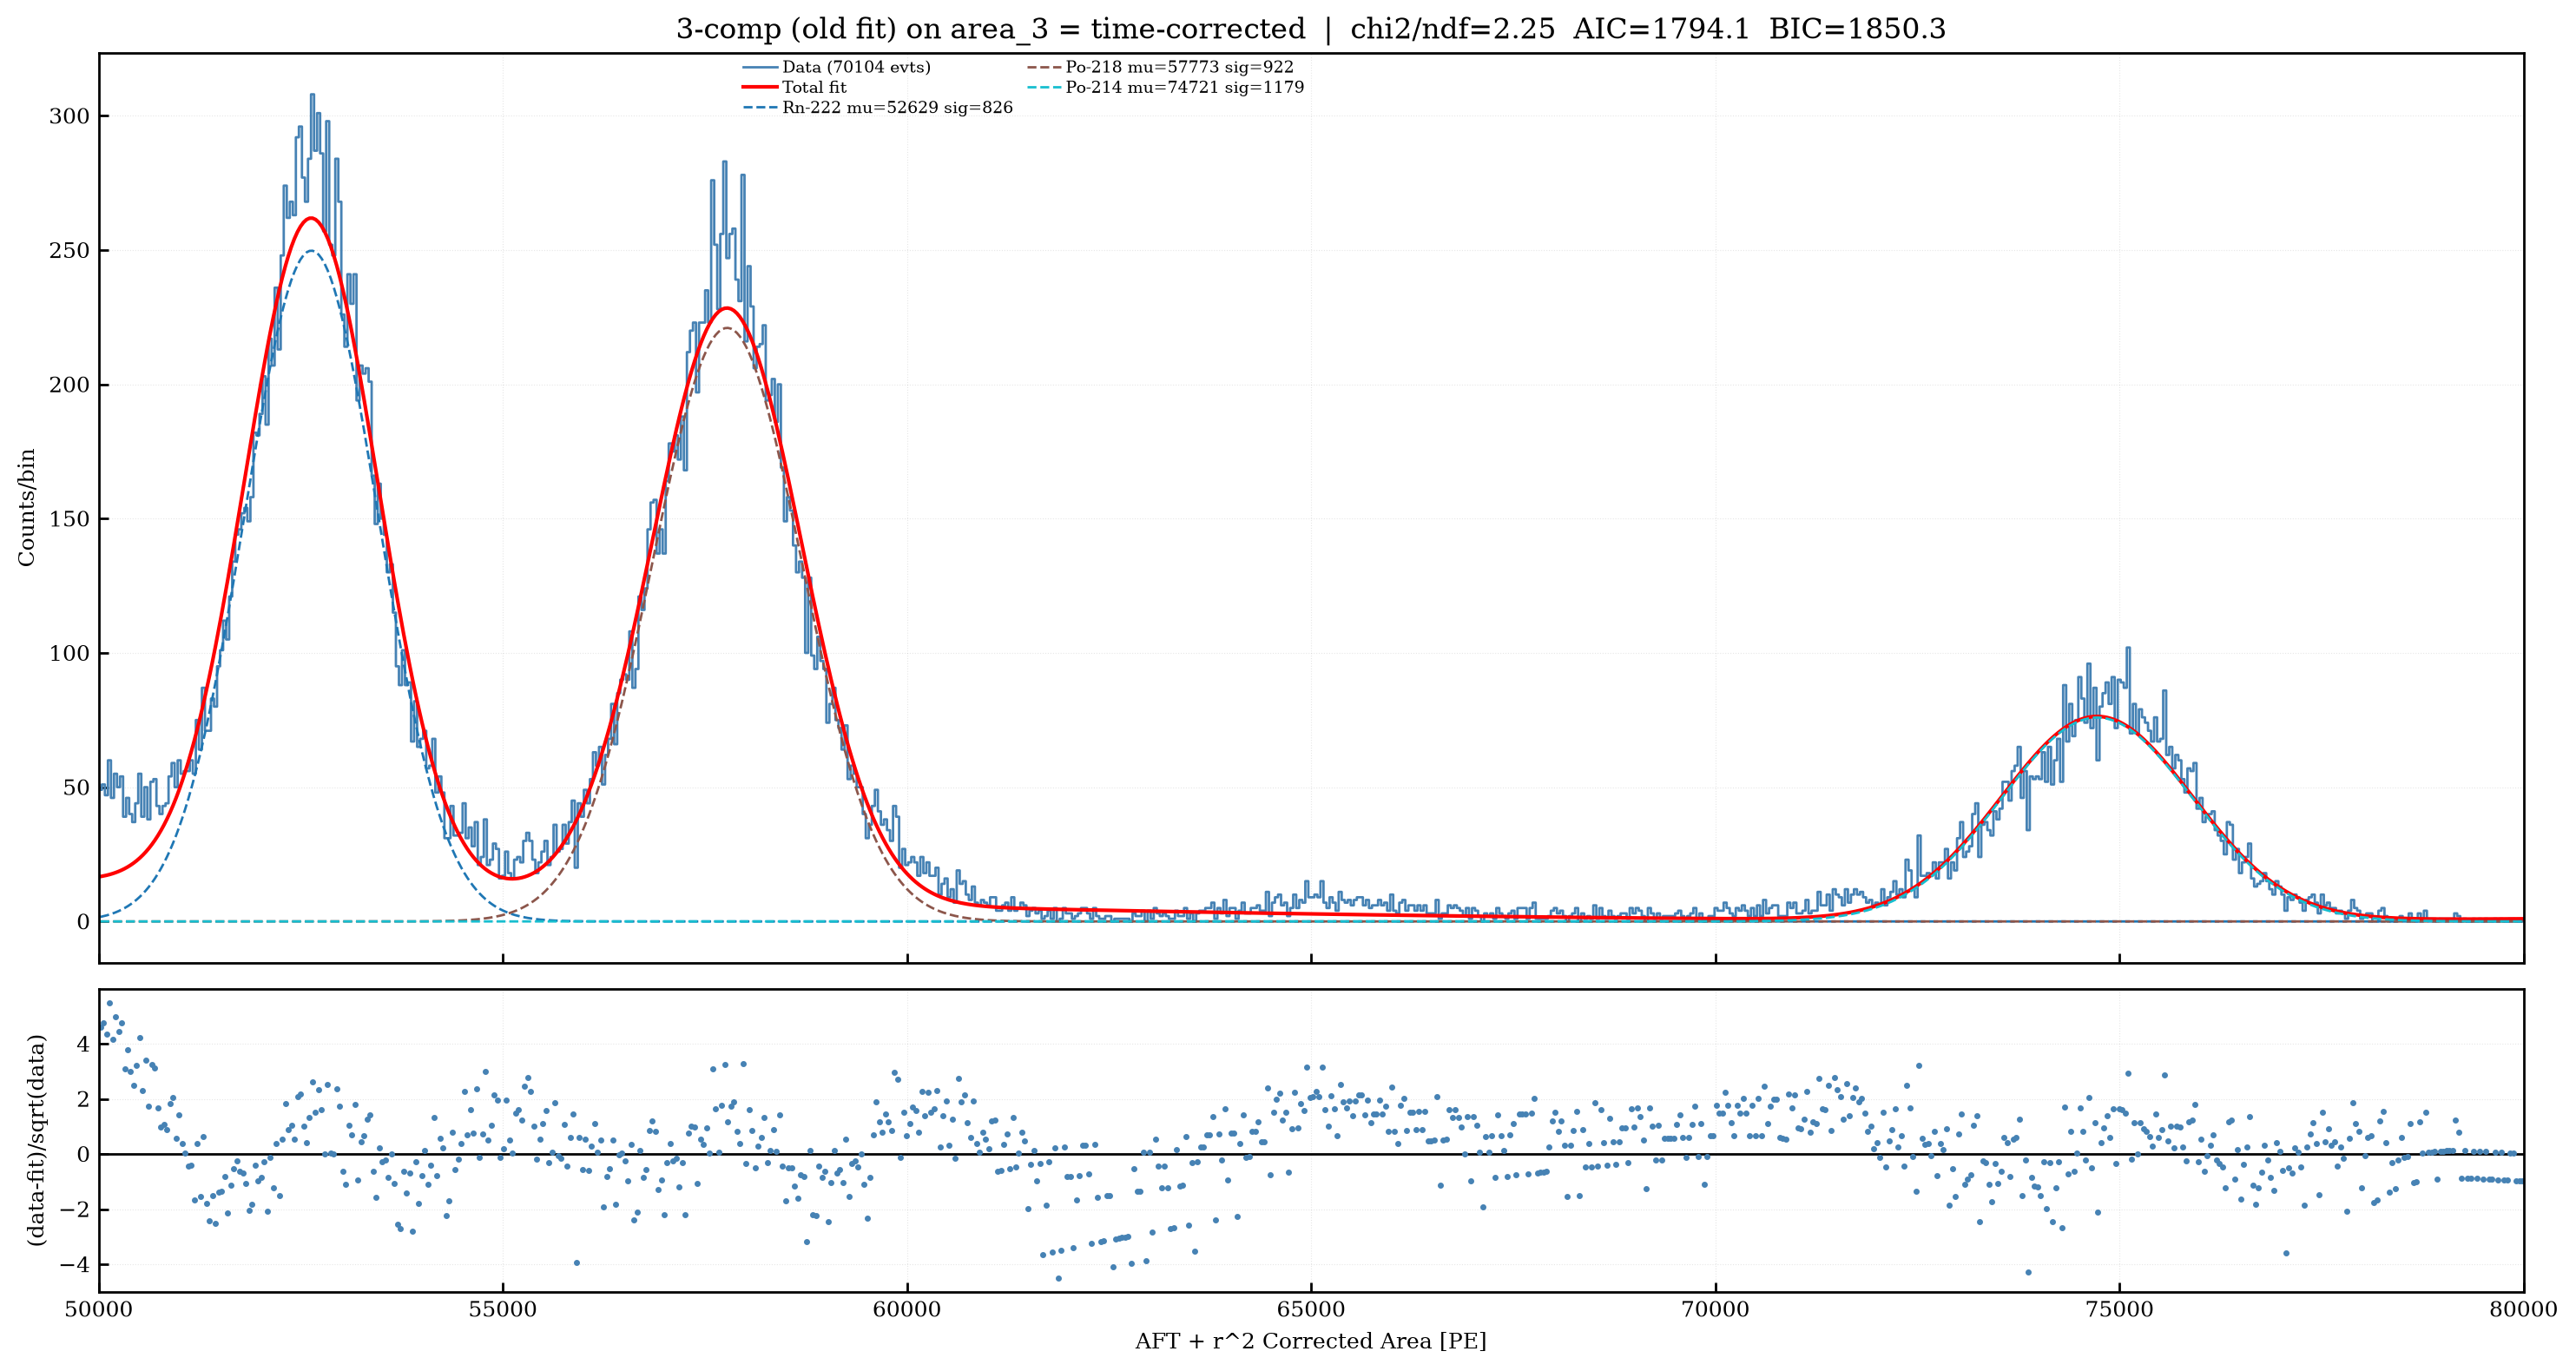

          config status  n_par  chi2/ndf    AIC    BIC  mu_Rn-222  sig_Rn-222  mu_Po-218  sig_Po-218  mu_Po-214  sig_Po-214
old fit | area_2     ok     12      2.31 1841.4 1897.6    52638.4       949.8    57800.0      1013.5    74813.8      1259.9
old fit | area_3     ok     12      2.25 1794.1 1850.3    52629.1       825.6    57773.1       922.4    74720.6      1179.1


In [15]:
# ═══════════════════════════════════════════════════════════════
# CELL B — TIME LIGHT-YIELD CORRECTION   area_3 = area_2_corrected / s(t)
# ═══════════════════════════════════════════════════════════════
# Per time chunk: 3-comp fit with mu bounds RELATIVE to the chunk's own
# Rn-222 guess (the absolute bounds clip on 09-17..19).
# s(t) = error-weighted mean of mu_i(t)/mu_i,ref over Rn-222/Po-218/Po-214,
# linearly interpolated in time per event.
CHUNK_H = 24            # chunk length [h]; try 12 for a finer s(t)
REL_BOUND = 0.04        # mu bounds = expected * (1 ± REL_BOUND)
MIN_CHUNK_EVENTS = 800
LY_ISO = [p[0] for p in PEAKS_3]

def peaks_relative(peaks, scale, rel=REL_BOUND):
    out = []
    for (name, Q, mu0, _, sig0, sig_b) in peaks:
        m = scale * Q / E_RN222
        out.append((name, Q, m, (m*(1 - rel), m*(1 + rel)), sig0, sig_b))
    return out

def fit_chunks(events, chunk_h=CHUNK_H, n_bins=300):
    chunk = events['time'].values // int(chunk_h * 3600e9)
    rows = []
    for cid in np.unique(chunk):
        sub = events[chunk == cid]
        if len(sub) < MIN_CHUNK_EVENTS:
            continue
        scale = find_peak_guess(sub, FIT_RANGE_DEFAULT)
        if scale is None:
            continue
        peaks = peaks_relative(PEAKS_3, scale)
        r = fit_spectrum(sub, peaks, FIT_RANGE_DEFAULT, n_bins, bg_deg=1)
        if not r.get('success'):
            continue
        err = np.sqrt(np.maximum(np.diag(r['pcov'])[[1, 4, 7]], 0.0))
        row = {'chunk': cid, 't_mid': float(np.median(sub['time'])),
               'n_events': len(sub), 'chi2_ndf': r['chi2_ndf']}
        for k, iso in enumerate(LY_ISO):
            mlo, mhi = peaks[k][3]
            row['mu_'+iso] = r['mu'][k]
            row['err_'+iso] = err[k]
            row['sig_'+iso] = r['sigma'][k]
            row['at_bound_'+iso] = bool(min(abs(r['mu'][k] - mlo), abs(r['mu'][k] - mhi)) < 1.0)
        rows.append(row)
    return pd.DataFrame(rows).sort_values('t_mid').reset_index(drop=True)

def ly_scale(chunks):
    w_sum = np.zeros(len(chunks)); r_sum = np.zeros(len(chunks))
    for iso in LY_ISO:
        ref = np.average(chunks['mu_'+iso], weights=chunks['n_events'])
        ratio = chunks['mu_'+iso].values / ref
        rerr = chunks['err_'+iso].values / ref
        ok = np.isfinite(rerr) & (rerr > 0) & ~chunks['at_bound_'+iso].values
        w = np.where(ok, 1.0 / np.where(ok, rerr, 1.0)**2, 0.0)
        chunks['ratio_'+iso] = ratio
        r_sum += w * ratio; w_sum += w
    chunks['scale'] = np.where(w_sum > 0, r_sum / np.maximum(w_sum, 1e-300), np.nan)
    return chunks[np.isfinite(chunks['scale'])].reset_index(drop=True)

chunks = ly_scale(fit_chunks(ev))
print('%d chunks of %d h' % (len(chunks), CHUNK_H))
print(chunks[['chunk', 'n_events', 'chi2_ndf'] + ['mu_'+i for i in LY_ISO]
             + ['ratio_'+i for i in LY_ISO] + ['scale']].round(4).to_string(index=False))

ev['ly_scale'] = np.interp(ev['time'].values.astype(float), chunks['t_mid'].values, chunks['scale'].values)
ev['area_3'] = ev['area_2_corrected'] / ev['ly_scale']
ev3 = ev.copy()
ev3['area_2_corrected'] = ev['area_3']      # so fit_spectrum() / find_peak_guess() see area_3

# ── after correction: refit the chunks, the peak positions should be flat ──
chunks3 = fit_chunks(ev3)
for iso in LY_ISO:
    print('  %-7s chunk mu spread (std): before %6.1f PE  ->  after %6.1f PE'
          % (iso, chunks['mu_'+iso].std(), chunks3['mu_'+iso].std()))

fig, ax = plt.subplots(figsize=(13, 4.5))
t = pd.to_datetime(chunks['t_mid'], unit='ns', utc=True)
for iso, col in zip(LY_ISO, ['tab:blue', 'tab:orange', 'tab:green']):
    ax.errorbar(t, chunks['ratio_'+iso], yerr=chunks['err_'+iso] / chunks['mu_'+iso],
                fmt='o', ms=3, capsize=2, color=col, label=iso + ' mu/mu_ref')
ax.plot(t, chunks['scale'], 'k-', lw=1.5, label='s(t)')
t3 = pd.to_datetime(chunks3['t_mid'], unit='ns', utc=True)
ax.plot(t3, chunks3['mu_Rn-222'] / chunks3['mu_Rn-222'].mean(), 'r--', lw=1, label='Rn-222 after corr')
ax.set_ylabel('relative peak position'); ax.set_title('Light-yield scale vs time (%d h chunks)' % CHUNK_H)
ax.legend(fontsize=8, ncol=5); ax.grid(True, alpha=0.25)
safe_tight(fig); plt.show()

res3_t = fit_spectrum(ev3, PEAKS_3, FIT_RANGE_DEFAULT, N_BINS_FIT, bg_deg=2)
plot_fit(res3_t, '3-comp (old fit) on area_3 = time-corrected')
print(pd.DataFrame([summary_row('old fit | area_2', res3),
                    summary_row('old fit | area_3', res3_t)]).to_string(index=False))

halo: f=0.227 r=1.857   (sigma = core width)


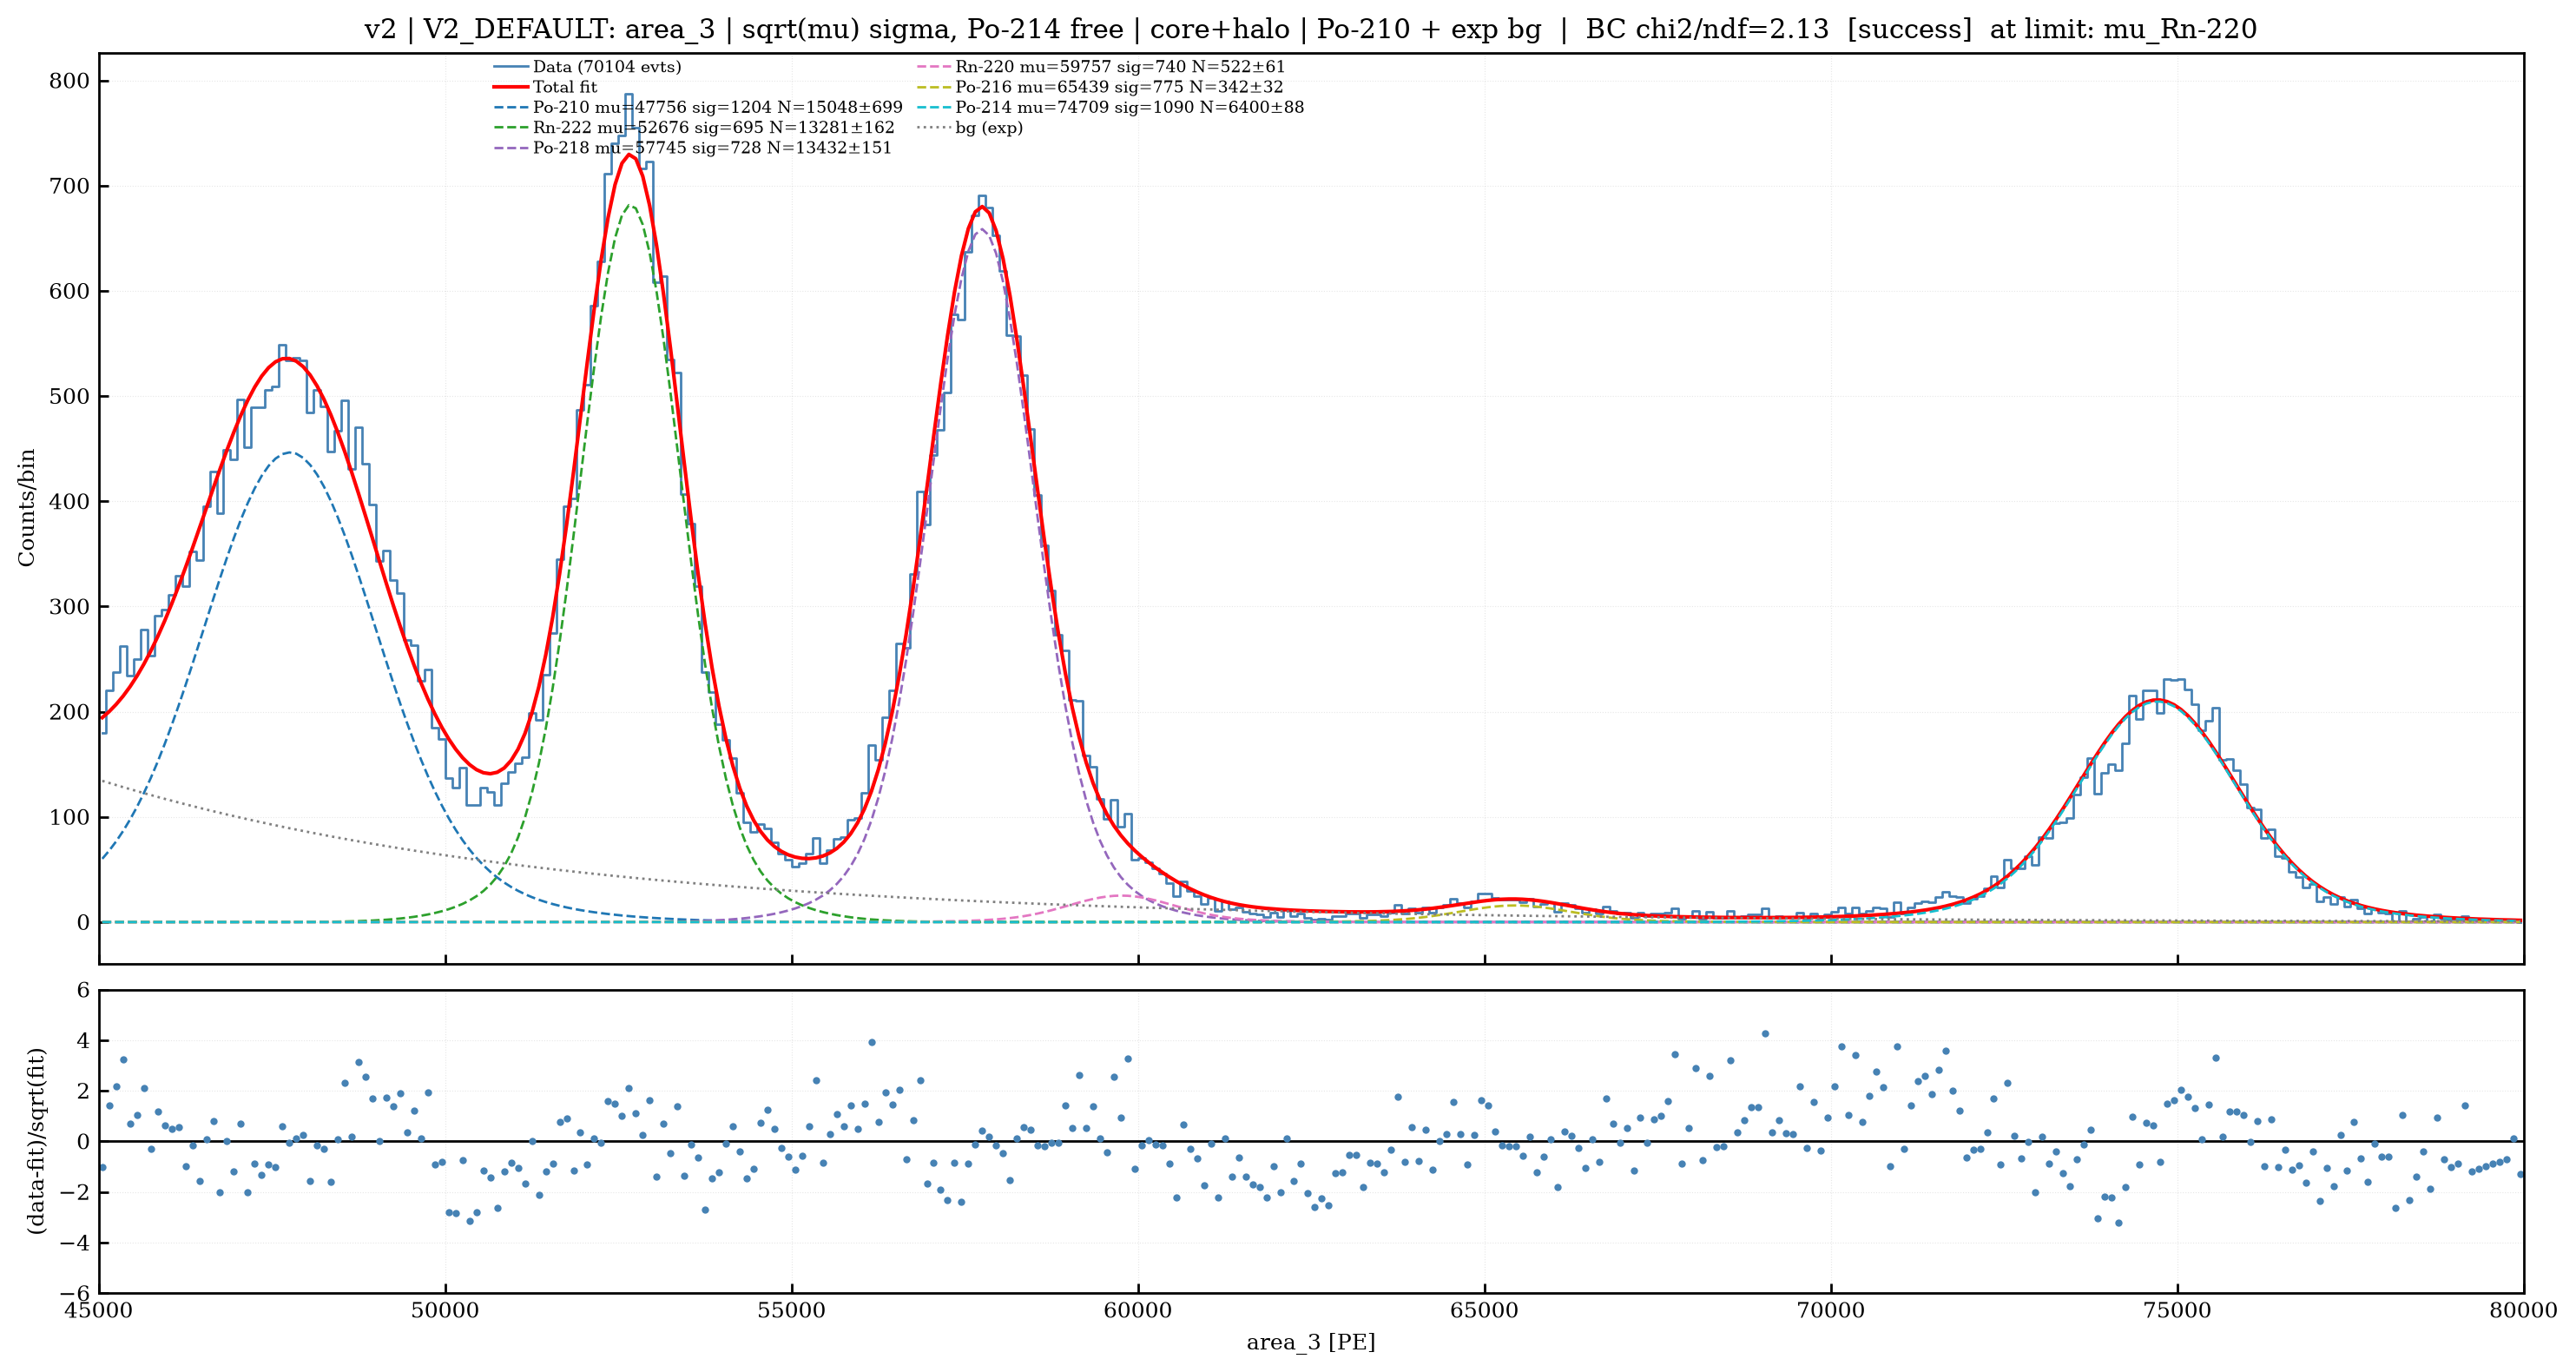

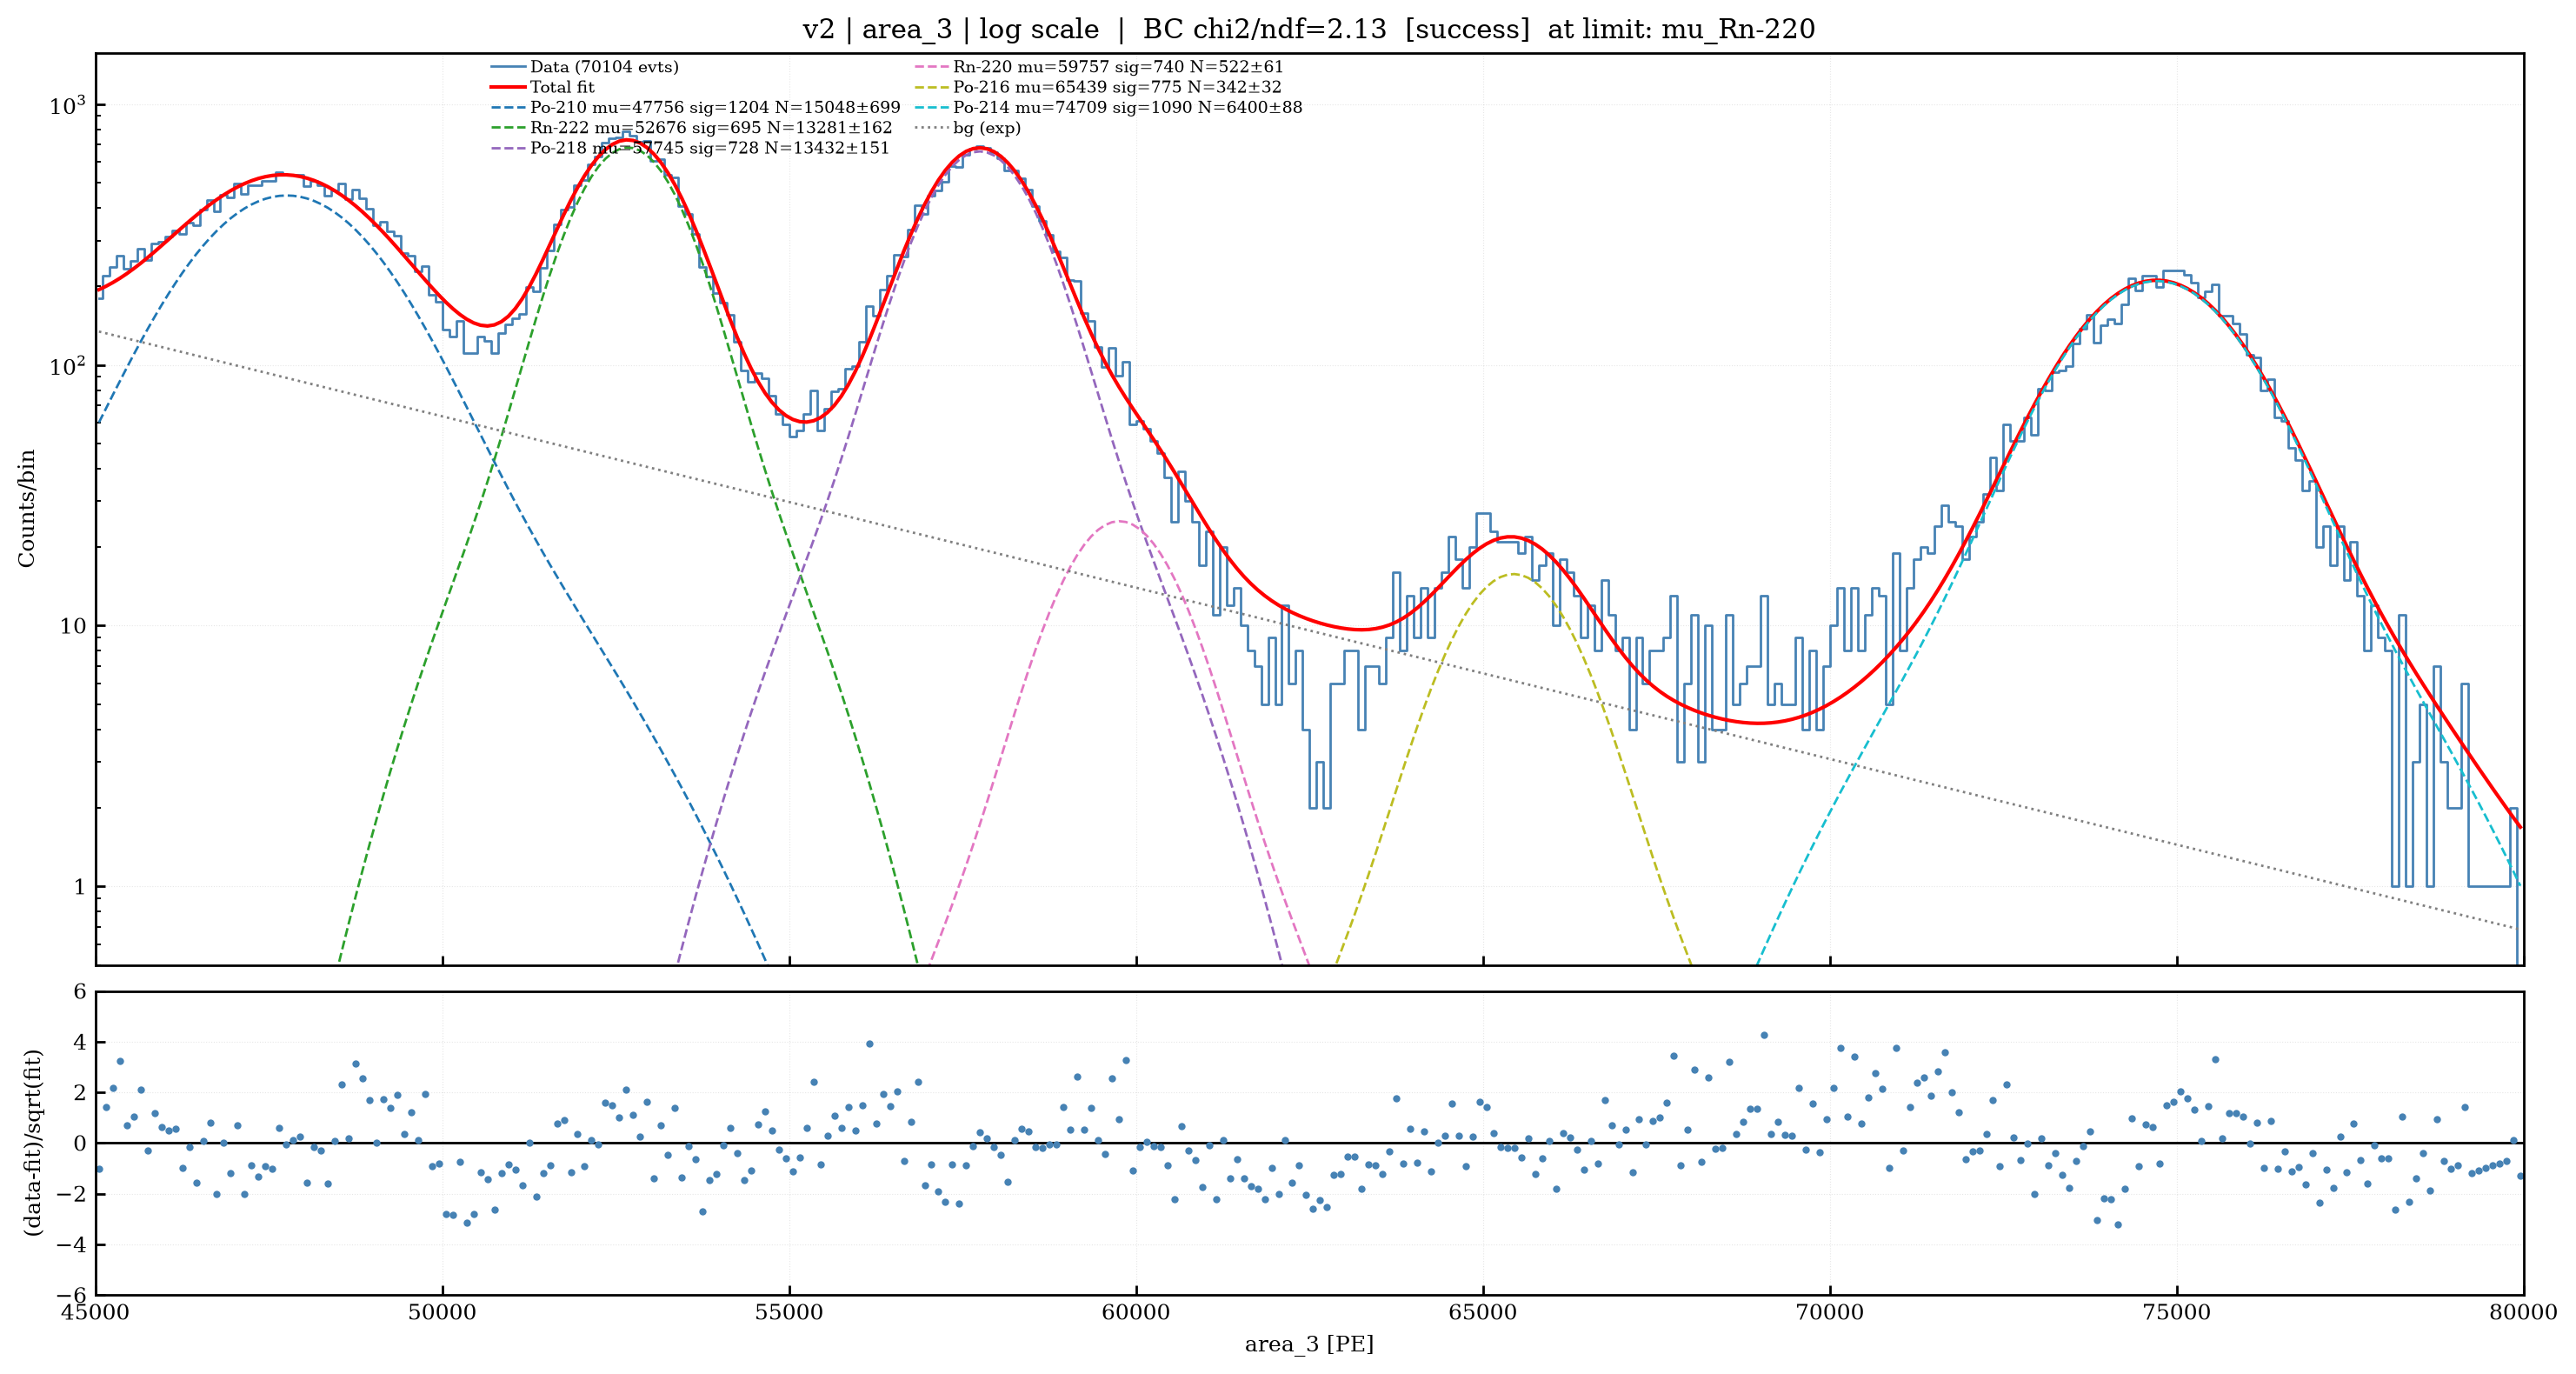

In [19]:
# ═══════════════════════════════════════════════════════════════
# CELL C — fit_spectrum_v2: binned Poisson likelihood (iminuit)
# ═══════════════════════════════════════════════════════════════
# - cost: Poisson deviance on bins (no sqrt(counts) weighting); model is the
#   CDF integrated over each bin, so it does not depend on bin-centre sampling
# - parameters: yield N_i (total counts) + mu_i per peak -> yields/errors direct
# - one energy table (alpha kinetic energies); mu bounds relative to the
#   expected position scale*E/E_Rn222, so they follow the light yield
# - sigma_mode: 'free' | 'sqrt' (sigma_i = k*sqrt(mu_i), production) |
#               'sqrt_po214free' (Po-214 own sigma). Po-210 always has its own.
# - bg: 'exp' | 'flat' | 'none'
# - tail: None | 'right' | 'left' (shared EMG tau) |
#         'halo' (core + wider Gaussian, shared fraction f and width ratio r:
#         the shape a mixture of AFT/time-dependent widths produces)
from iminuit import Minuit
from scipy.special import ndtr, log_ndtr

E_ALPHA_RN222 = 5.490
# (name, E_alpha [MeV], (rel_lo, rel_hi) around scale*E/E_ALPHA_RN222)
PEAKS_V2 = [
    ('Po-210', 5.304, (0.90, 1.01)),
    ('Rn-222', 5.490, (0.96, 1.04)),
    ('Po-218', 6.002, (0.97, 1.04)),
    ('Rn-220', 6.288, (0.99, 1.04)),
    ('Po-216', 6.778, (0.98, 1.04)),
    ('Po-214', 7.687, (0.98, 1.05)),
]
PEAKS_V2_NO_PO210 = [p for p in PEAKS_V2 if p[0] != 'Po-210']
SMALL_PEAKS = ('Po-210', 'Rn-220', 'Po-216')

def _peak_cdf(x, mu, sig, tau=None, side=+1):
    """Gaussian CDF, or exponentially-modified Gaussian with tail on `side`."""
    u = (x - mu) / sig
    if tau is None:
        return ndtr(u)
    if side < 0:
        return 1.0 - _peak_cdf(-x, -mu, sig, tau, +1)
    ls = sig / tau
    return ndtr(u) - np.exp(-u*ls + 0.5*ls**2 + log_ndtr(u - ls))


def fit_spectrum_v2(events, peaks=PEAKS_V2, fit_range=(45e3, 80e3), bin_w=100.0,
                    sigma_mode='sqrt', bg='exp', tail=None, col='area_2_corrected',
                    scale=None, fix=None):
    """fix: {param_name: value} held constant (e.g. halo shape from the combined fit)."""
    x_all = np.asarray(events[col].values, float)
    n_ev = len(x_all)
    if n_ev < 100:
        return {'success': False, 'status': 'too_few_events(%d)' % n_ev, 'n_events': n_ev}

    n_bins = int(round((fit_range[1] - fit_range[0]) / bin_w))
    counts, edges = np.histogram(x_all, bins=n_bins, range=fit_range)
    centers = 0.5*(edges[:-1] + edges[1:])
    nlogn = np.where(counts > 0, counts*np.log(np.maximum(counts, 1)), 0.0)
    if scale is None:
        scale = find_peak_guess(pd.DataFrame({'area_2_corrected': x_all}), FIT_RANGE_DEFAULT) or RN222_REF

    pk_names = [p[0] for p in peaks]
    own_sig = [nm for nm in pk_names if sigma_mode == 'free' or nm == 'Po-210'
               or (sigma_mode == 'sqrt_po214free' and nm == 'Po-214')]
    linked = [nm for nm in pk_names if nm not in own_sig]
    side = -1 if tail == 'left' else +1

    names, p0, lims = [], [], []
    def add(n, v, lim):
        names.append(n); p0.append(v); lims.append(lim)
    for (nm, E, (rlo, rhi)) in peaks:
        m = scale * E / E_ALPHA_RN222
        n_win = float(((x_all > m - 1500) & (x_all < m + 1500)).sum())
        add('N_'+nm, max(n_win * (0.2 if nm in SMALL_PEAKS else 0.9), 10.0), (0, None))
        add('mu_'+nm, m, (m*rlo, m*rhi))
    for nm in own_sig:
        add('sig_'+nm, 750.0, (200, 3000))
    if linked:
        add('k_sig', 750.0 / np.sqrt(scale), (0.5, 20))
    if tail in ('right', 'left'):
        add('tau', 400.0, (20, 5000))
    elif tail == 'halo':
        add('f_halo', 0.3, (0.0, 0.9))
        add('r_halo', 1.6, (1.05, 5.0))
    if bg in ('exp', 'flat'):
        add('b0', max(np.percentile(counts, 10), 0.5) / bin_w, (0, None))
    if bg == 'exp':
        add('b1', 0.0, (-20, 20))
    idx = {n: i for i, n in enumerate(names)}

    def unpack(p):
        Ns = np.array([p[idx['N_'+nm]] for nm in pk_names])
        mus = np.array([p[idx['mu_'+nm]] for nm in pk_names])
        sigs = np.array([p[idx['sig_'+nm]] if nm in own_sig else p[idx['k_sig']]*np.sqrt(mus[j])
                         for j, nm in enumerate(pk_names)])
        return Ns, mus, sigs, (p[idx['tau']] if 'tau' in idx else None)

    def bg_cdf(x, p):
        x = np.asarray(x, float)
        if bg == 'none':
            return np.zeros_like(x)
        t = (x - X_REF) / 1e4
        b0 = p[idx['b0']]
        b1 = p[idx['b1']] if bg == 'exp' else 0.0
        if abs(b1) < 1e-8:
            return b0 * 1e4 * t
        return b0 * 1e4 * np.expm1(b1*t) / b1

    def comp_cdf(x, p, j):
        Ns, mus, sigs, tau = unpack(p)
        x = np.asarray(x, float)
        if tail == 'halo':
            f, r = p[idx['f_halo']], p[idx['r_halo']]
            return Ns[j] * ((1 - f)*ndtr((x - mus[j])/sigs[j]) + f*ndtr((x - mus[j])/(r*sigs[j])))
        return Ns[j] * _peak_cdf(x, mus[j], sigs[j], tau, side)

    def expected(p):
        e = np.diff(bg_cdf(edges, p))
        for j in range(len(pk_names)):
            e = e + np.diff(comp_cdf(edges, p, j))
        return e

    def nll(p):  # half the Baker-Cousins Poisson chi2
        e = np.maximum(expected(p), 1e-300)
        return float(np.sum(e - counts - counts*np.log(e) + nlogn))

    try:
        m = Minuit(nll, np.array(p0, float), name=names)
        m.errordef = Minuit.LIKELIHOOD
        for n, lim in zip(names, lims):
            m.limits[n] = lim
        for n, v in (fix or {}).items():
            if n in idx:
                m.values[n] = v; m.fixed[n] = True
        m.migrad(ncall=200000)
        if not m.valid:
            m.simplex(ncall=50000).migrad(ncall=200000)
        m.hesse()
    except Exception as e:
        return {'success': False, 'status': 'fit_failed: %s' % e, 'n_events': n_ev}

    p = np.array(m.values, float)
    Ns, mus, sigs, tau = unpack(p)
    model = expected(p)
    chi2 = 2.0 * m.fval
    k = int(np.sum(~np.array(list(m.fixed), bool)))
    ndf = max(n_bins - k, 1)
    at_limit = [n for n, lim in zip(names, lims)
                if (lim[0] is not None and abs(p[idx[n]] - lim[0]) < 1e-3*max(abs(lim[0]), 1))
                or (lim[1] is not None and abs(p[idx[n]] - lim[1]) < 1e-3*max(abs(lim[1]), 1))]

    def cdf(x, j):
        return bg_cdf(x, p) if j == 'bg' else comp_cdf(x, p, j)

    return {
        'success': bool(m.valid), 'status': 'success' if m.valid else 'migrad_invalid',
        'minuit': m, 'names': names, 'p_fit': p,
        'pcov': np.array(m.covariance) if m.covariance is not None else None,
        'amp': Ns * bin_w / (sigs * np.sqrt(2*np.pi)),
        'mu': mus, 'sigma': sigs, 'tau': tau,
        'halo': (p[idx['f_halo']], p[idx['r_halo']]) if tail == 'halo' else None,
        'yield': Ns, 'yield_err': np.array([m.errors['N_'+nm] for nm in pk_names]),
        'at_limit': at_limit,
        'chi2': chi2, 'ndf': ndf, 'chi2_ndf': chi2/ndf,
        'aic': chi2 + 2*k, 'bic': chi2 + k*np.log(max(n_bins, 2)),
        'n_events': n_ev, 'n_bins': n_bins, 'bin_w': bin_w,
        'centers': centers, 'edges': edges, 'counts': counts, 'model': model,
        'comp_model': [np.diff(comp_cdf(edges, p, j)) for j in range(len(pk_names))],
        'bg_model': np.diff(bg_cdf(edges, p)), 'cdf': cdf,
        'peaks': peaks, 'fit_range': fit_range, 'bg_deg': bg, 'col': col, 'scale': scale,
        'config': dict(peaks=peaks, fit_range=fit_range, bin_w=bin_w, sigma_mode=sigma_mode,
                       bg=bg, tail=tail, col=col),
    }


def plot_fit_v2(res, title='', logy=False):
    if 'model' not in res:
        print(title, 'FAILED:', res.get('status'))
        return
    c, y, mdl = res['centers'], res['counts'], res['model']
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True,
                                   gridspec_kw={'height_ratios': [3, 1]})
    ax1.step(c, y, where='mid', color='steelblue', lw=1.0, label='Data (%d evts)' % res['n_events'])
    ax1.plot(c, mdl, 'r-', lw=1.5, label='Total fit')
    colors = plt.cm.tab10(np.linspace(0, 1, len(res['peaks'])))
    for j, spec in enumerate(res['peaks']):
        ax1.plot(c, res['comp_model'][j], '--', color=colors[j], lw=1.0,
                 label='%s mu=%.0f sig=%.0f N=%.0f±%.0f' % (spec[0], res['mu'][j], res['sigma'][j],
                                                            res['yield'][j], res['yield_err'][j]))
    ax1.plot(c, res['bg_model'], ':', color='gray', lw=1.0, label='bg (%s)' % res['bg_deg'])
    if logy:
        ax1.set_yscale('log'); ax1.set_ylim(0.5, y.max()*2)
    ax1.set_ylabel('Counts/bin')
    ax1.set_title('%s  |  BC chi2/ndf=%.2f  [%s]%s' % (
        title, res['chi2_ndf'], res['status'],
        ('  at limit: ' + ', '.join(res['at_limit'])) if res['at_limit'] else ''), fontsize=11)
    ax1.legend(fontsize=7, ncol=2, loc='upper right'); ax1.grid(True, alpha=0.25)

    pull = (y - mdl) / np.sqrt(np.maximum(mdl, 1e-3))
    ax2.axhline(0, color='k', lw=1)
    ax2.plot(c, pull, 'o', ms=2, color='steelblue')
    ax2.set_ylim(-6, 6)
    ax2.set_ylabel('(data-fit)/sqrt(fit)'); ax2.set_xlabel('%s [PE]' % res['col'])
    ax2.grid(True, alpha=0.25); ax2.set_xlim(res['fit_range'])
    safe_tight(fig); plt.show()


# default for the rate: drift-corrected area_3, sigma = k*sqrt(mu) with Po-214 free,
# core+halo shape, Po-210 + exp bg (best peak match / window-vs-yield agreement in tests)
V2_DEFAULT = dict(col='area_3', sigma_mode='sqrt_po214free', tail='halo')
res_v2 = fit_spectrum_v2(ev, **V2_DEFAULT)
print('halo: f=%.3f r=%.3f   (sigma = core width)' % res_v2['halo'] if res_v2.get('halo') else '')
plot_fit_v2(res_v2, 'v2 | V2_DEFAULT: area_3 | sqrt(mu) sigma, Po-214 free | core+halo | Po-210 + exp bg')
plot_fit_v2(res_v2, 'v2 | area_3 | log scale', logy=True)

In [17]:
# ═══════════════════════════════════════════════════════════════
# CELL D — ±2σ WINDOW RATE with acceptance + leakage correction
# ═══════════════════════════════════════════════════════════════
# N_sig = (N_window - expected bg/other peaks in window) / acceptance
# acceptance = fraction of the fitted peak shape inside the window
# (0.9545 for a pure Gaussian; differs if a tail is fitted).
# Uses TOTAL_LIVETIME_S / MASS_TOTAL_KG from the scheme-2 cell.
RATE_ISO = ['Rn-222', 'Po-218', 'Po-214']
RATE_NORM = 1e6 / (MASS_TOTAL_KG * TOTAL_LIVETIME_S)

def window_rate_v2(events, res, iso, n_sig=2.0):
    j = [s[0] for s in res['peaks']].index(iso)
    mu, sig = res['mu'][j], res['sigma'][j]
    lo, hi = mu - n_sig*sig, mu + n_sig*sig
    x = events[res['col']].values
    n_win = int(((x >= lo) & (x <= hi)).sum())
    cdf = res['cdf']
    contam = float(cdf(hi, 'bg') - cdf(lo, 'bg'))
    contam += sum(float(cdf(hi, i) - cdf(lo, i)) for i in range(len(res['peaks'])) if i != j)
    acc = float(cdf(hi, j) - cdf(lo, j)) / res['yield'][j]
    n_corr = (n_win - contam) / acc
    return {'isotope': iso, 'win_lo': lo, 'win_hi': hi, 'n_window': n_win,
            'contam': contam, 'acceptance': acc, 'n_corr': n_corr,
            'n_corr_err': np.sqrt(max(n_win, 1)) / acc,
            'n_fit': res['yield'][j], 'n_fit_err': res['yield_err'][j],
            'rate_window': n_corr * RATE_NORM, 'rate_window_err': np.sqrt(max(n_win, 1)) / acc * RATE_NORM,
            'rate_fit': res['yield'][j] * RATE_NORM, 'rate_fit_err': res['yield_err'][j] * RATE_NORM}

def old_window_rate(events, res, iso, n_sig=2.0):
    """Master-notebook style: raw count in the old fit's ±2σ window."""
    j = [s[0] for s in res['peaks']].index(iso)
    lo, hi = res['mu'][j] - n_sig*res['sigma'][j], res['mu'][j] + n_sig*res['sigma'][j]
    n = int(((events['area_2_corrected'] >= lo) & (events['area_2_corrected'] <= hi)).sum())
    return n, n * RATE_NORM

rows = []
for iso in RATE_ISO:
    r = window_rate_v2(ev, res_v2, iso)
    n_old, rate_old = old_window_rate(ev, res3, iso)
    r['n_window_old'] = n_old
    r['rate_old_raw'] = rate_old
    r['window/fit - 1'] = r['n_corr'] / r['n_fit'] - 1
    rows.append(r)
rates_v2 = pd.DataFrame(rows)
print('rate unit: uBq/kg  (window = acceptance+leakage corrected, fit = fitted yield)')
print(rates_v2.round(4).to_string(index=False))

# ── AFT-binned cross-check (4 bins, V2_DEFAULT config): sum of yields vs combined ──
aft_e = np.linspace(AFT_LO, AFT_HI, N_AFT_FIT_BINS + 1)
rows = []
for lo, hi in zip(aft_e[:-1], aft_e[1:]):
    sub = ev[(ev['area_fraction_top'] >= lo) & (ev['area_fraction_top'] < hi)]
    r = fit_spectrum_v2(sub, **V2_DEFAULT)
    row = {'aft_lo': lo, 'aft_hi': hi, 'n_events': len(sub), 'status': r.get('status'),
           'chi2/ndf': round(r['chi2_ndf'], 2) if 'chi2_ndf' in r else np.nan}
    for iso in RATE_ISO:
        if 'yield' in r:
            j = [s[0] for s in r['peaks']].index(iso)
            row['mu_'+iso] = round(r['mu'][j], 1); row['sig_'+iso] = round(r['sigma'][j], 1)
            row['N_'+iso] = r['yield'][j]; row['Nerr_'+iso] = r['yield_err'][j]
    rows.append(row)
aft_v2 = pd.DataFrame(rows)
print('\nAFT bins, v2 on area_3:')
print(aft_v2.round(1).to_string(index=False))
for iso in RATE_ISO:
    j = [s[0] for s in res_v2['peaks']].index(iso)
    s_bins = aft_v2['N_'+iso].sum(); e_bins = np.sqrt((aft_v2['Nerr_'+iso]**2).sum())
    print('  %-7s combined N = %8.1f ± %5.1f   sum of AFT bins = %8.1f ± %5.1f   (diff %+.2f%%)'
          % (iso, res_v2['yield'][j], res_v2['yield_err'][j], s_bins, e_bins,
             100*(s_bins / res_v2['yield'][j] - 1)))

rate unit: uBq/kg  (window = acceptance+leakage corrected, fit = fitted yield)
isotope     win_lo     win_hi  n_window    contam  acceptance     n_corr  n_corr_err      n_fit  n_fit_err  rate_window  rate_window_err  rate_fit  rate_fit_err  n_window_old  rate_old_raw  window/fit - 1
 Rn-222 51286.3339 54066.4884     13424 1402.1555      0.9009 13344.3725    128.6080 13281.3737   162.2123       2.8405           0.0274    2.8271        0.0345         14503        3.0871          0.0047
 Po-218 56289.4597 59200.2946     12723  716.1204      0.9009 13327.7612    125.2050 13431.6995   150.7776       2.8370           0.0267    2.8591        0.0321         13756        2.9281         -0.0077
 Po-214 72529.6187 76888.3092      5801   67.0163      0.9009  6364.7815     84.5432  6399.6341    88.2403       1.3548           0.0180    1.3622        0.0188          5902        1.2563         -0.0054

AFT bins, v2 on area_3:
 aft_lo  aft_hi  n_events         status  chi2/ndf  mu_Rn-222  sig_Rn-222  N

In [18]:
# ═══════════════════════════════════════════════════════════════
# CELL E — CONFIG COMPARISON + DAILY WINDOW CHECK + TOY-MC BIAS
# ═══════════════════════════════════════════════════════════════
def peak_ratio(res, iso, half_w=600.0):
    """sum(model)/sum(data) within mu ± half_w: 1.00 = the fit reaches the peak."""
    j = [s[0] for s in res['peaks']].index(iso)
    m = np.abs(res['centers'] - res['mu'][j]) < half_w
    return float(res['model'][m].sum() / max(res['counts'][m].sum(), 1))

V2_CONFIGS = [
    ('v2 sqrt | area_2',                   dict(col='area_2_corrected')),
    ('v2 free | area_3',                   dict(col='area_3', sigma_mode='free')),
    ('v2 sqrt | area_3',                   dict(col='area_3')),
    ('v2 sqrt_po214free | area_3',         dict(col='area_3', sigma_mode='sqrt_po214free')),
    ('v2 sqrt | area_3 | no Po-210 50-80k', dict(col='area_3', peaks=PEAKS_V2_NO_PO210, fit_range=(50e3, 80e3))),
    ('v2 sqrt | area_3 | right tail',      dict(col='area_3', tail='right')),
    ('v2 sqrt | area_3 | left tail',       dict(col='area_3', tail='left')),
    ('v2 sqrt | area_3 | halo',            dict(col='area_3', tail='halo')),
    ('v2 sqrt | area_2 | halo',            dict(col='area_2_corrected', tail='halo')),
    ('v2 free | area_3 | halo',            dict(col='area_3', sigma_mode='free', tail='halo')),
    ('V2_DEFAULT',                          V2_DEFAULT),
]

rows = []
for label, res in [('old 3-comp | area_2', res3), ('old 3-comp | area_3', res3_t)]:
    row = {'config': label, 'status': res.get('status'), 'chi2/ndf': round(res['chi2_ndf'], 2)}
    for k, iso in enumerate(RATE_ISO):
        row['mu_'+iso] = round(res['mu'][k], 0); row['sig_'+iso] = round(res['sigma'][k], 0)
        row['pk_'+iso] = round(peak_ratio(res, iso), 3)
        row['N_'+iso] = round(gauss_yield(res, k), 0)
    rows.append(row)

fits_v2 = {}
for label, kw in V2_CONFIGS:
    res = fit_spectrum_v2(ev, **kw)
    fits_v2[label] = res
    if 'yield' not in res:
        rows.append({'config': label, 'status': res.get('status')})
        continue
    row = {'config': label, 'status': res['status'], 'chi2/ndf': round(res['chi2_ndf'], 2),
           'at_limit': ','.join(res['at_limit'])}
    for iso in RATE_ISO:
        j = [s[0] for s in res['peaks']].index(iso)
        w = window_rate_v2(ev, res, iso)
        row['mu_'+iso] = round(res['mu'][j], 0); row['sig_'+iso] = round(res['sigma'][j], 0)
        row['pk_'+iso] = round(peak_ratio(res, iso), 3)
        row['N_'+iso] = round(res['yield'][j], 0)
        row['Nwin_'+iso] = round(w['n_corr'], 0)
    rows.append(row)

cmp_v2 = pd.DataFrame(rows)
print('pk_* = model/data within mu±600 PE (1.00 = fit reaches the peak)')
print('N_*  = fitted yield (old: Gaussian integral);  Nwin_* = ±2σ window, acceptance+leakage corrected')
print(cmp_v2.to_string(index=False))
cmp_v2.to_csv('fit_test_v2_configs_P6.csv', index=False)
print('\nWrote fit_test_v2_configs_P6.csv')

# ── daily: events in the v2 window (area_3) vs the old window (area_2) ──
rows = []
for day, g in ev.groupby('day'):
    row = {'day': str(day), 'n_events': len(g)}
    for k, iso in enumerate(RATE_ISO):
        j = [s[0] for s in res_v2['peaks']].index(iso)
        lo3, hi3 = res_v2['mu'][j] - 2*res_v2['sigma'][j], res_v2['mu'][j] + 2*res_v2['sigma'][j]
        lo2, hi2 = res3['mu'][k] - 2*res3['sigma'][k], res3['mu'][k] + 2*res3['sigma'][k]
        n3 = ((g['area_3'] >= lo3) & (g['area_3'] <= hi3)).sum()
        n2 = ((g['area_2_corrected'] >= lo2) & (g['area_2_corrected'] <= hi2)).sum()
        row['old/v2_'+iso] = round(n2 / max(n3, 1), 3)
    rows.append(row)
print('\nDaily window counts, old window on area_2 / v2 window on area_3 '
      '(v2 window is narrower, so a stable ratio > 1 is expected; watch the trend):')
print(pd.DataFrame(rows).to_string(index=False))

# ── toy MC: refit Poisson toys of the v2 model -> yield bias and pull width ──
RUN_TOYS = True
N_TOYS = 100

def toy_check(res, n_toys=N_TOYS, seed=1):
    rng = np.random.default_rng(seed)
    cfg = dict(res['config']); col = cfg['col']
    edges = res['edges']
    out = []
    for _ in range(n_toys):
        n = rng.poisson(res['model'])
        x = np.repeat(edges[:-1], n) + rng.uniform(0, res['bin_w'], n.sum())
        r = fit_spectrum_v2(pd.DataFrame({col: x}), scale=res['scale'], **cfg)
        if 'yield' in r:
            out.append((r['yield'] - res['yield']) / r['yield_err'])
    pulls = np.array(out)
    df = pd.DataFrame({'isotope': [s[0] for s in res['peaks']],
                       'mean_pull': pulls.mean(0), 'pull_width': pulls.std(0),
                       'rel_bias_%': 100*pulls.mean(0)*res['yield_err']/res['yield']})
    print('toys: %d/%d converged' % (len(pulls), n_toys))
    return df

if RUN_TOYS:
    print(toy_check(res_v2).round(3).to_string(index=False))

pk_* = model/data within mu±600 PE (1.00 = fit reaches the peak)
N_*  = fitted yield (old: Gaussian integral);  Nwin_* = ±2σ window, acceptance+leakage corrected
                             config         status  chi2/ndf  mu_Rn-222  sig_Rn-222  pk_Rn-222  N_Rn-222  mu_Po-218  sig_Po-218  pk_Po-218  N_Po-218  mu_Po-214  sig_Po-214  pk_Po-214  N_Po-214             at_limit  Nwin_Rn-222  Nwin_Po-218  Nwin_Po-214
                old 3-comp | area_2        success      2.31    52638.0       950.0      0.928   13675.0    57800.0      1013.0      0.946   13412.0    74814.0      1260.0      0.947    5884.0                  NaN          NaN          NaN          NaN
                old 3-comp | area_3        success      2.25    52629.0       826.0      0.951   13785.0    57773.0       922.0      0.947   13628.0    74721.0      1179.0      0.944    5983.0                  NaN          NaN          NaN          NaN
                   v2 sqrt | area_2        success      3.40    52724.0       9

events without a run in trend_per_run_P6.csv: 2
Wrote fit_test_rates_12h_P6.csv  (33 bins)
               method isotope           all  before 09-17        09-17+
              prev M2  Po-214 1.256 ± 0.016 1.347 ± 0.018 0.624 ± 0.033
              prev M2  Po-218 2.928 ± 0.025 3.010 ± 0.027 2.356 ± 0.063
              prev M2  Rn-222 3.087 ± 0.026 3.138 ± 0.028 2.730 ± 0.068
v2 fixed | V2_DEFAULT  Po-214 1.355 ± 0.018 1.431 ± 0.020 0.820 ± 0.040
v2 fixed | V2_DEFAULT  Po-218 2.837 ± 0.027 2.866 ± 0.029 2.631 ± 0.073
v2 fixed | V2_DEFAULT  Rn-222 2.840 ± 0.027 2.843 ± 0.029 2.824 ± 0.077
 v2 fixed | free+halo  Po-214 1.393 ± 0.019 1.472 ± 0.020 0.843 ± 0.041
 v2 fixed | free+halo  Po-218 3.181 ± 0.028 3.210 ± 0.030 2.983 ± 0.077
 v2 fixed | free+halo  Rn-222 3.096 ± 0.028 3.099 ± 0.030 3.080 ± 0.079
           v2 per-bin  Po-214 1.369 ± 0.018 1.440 ± 0.020 0.871 ± 0.041
           v2 per-bin  Po-218 2.877 ± 0.027 2.897 ± 0.029 2.735 ± 0.074
           v2 per-bin  Rn-222 2.896 ± 0.028 2

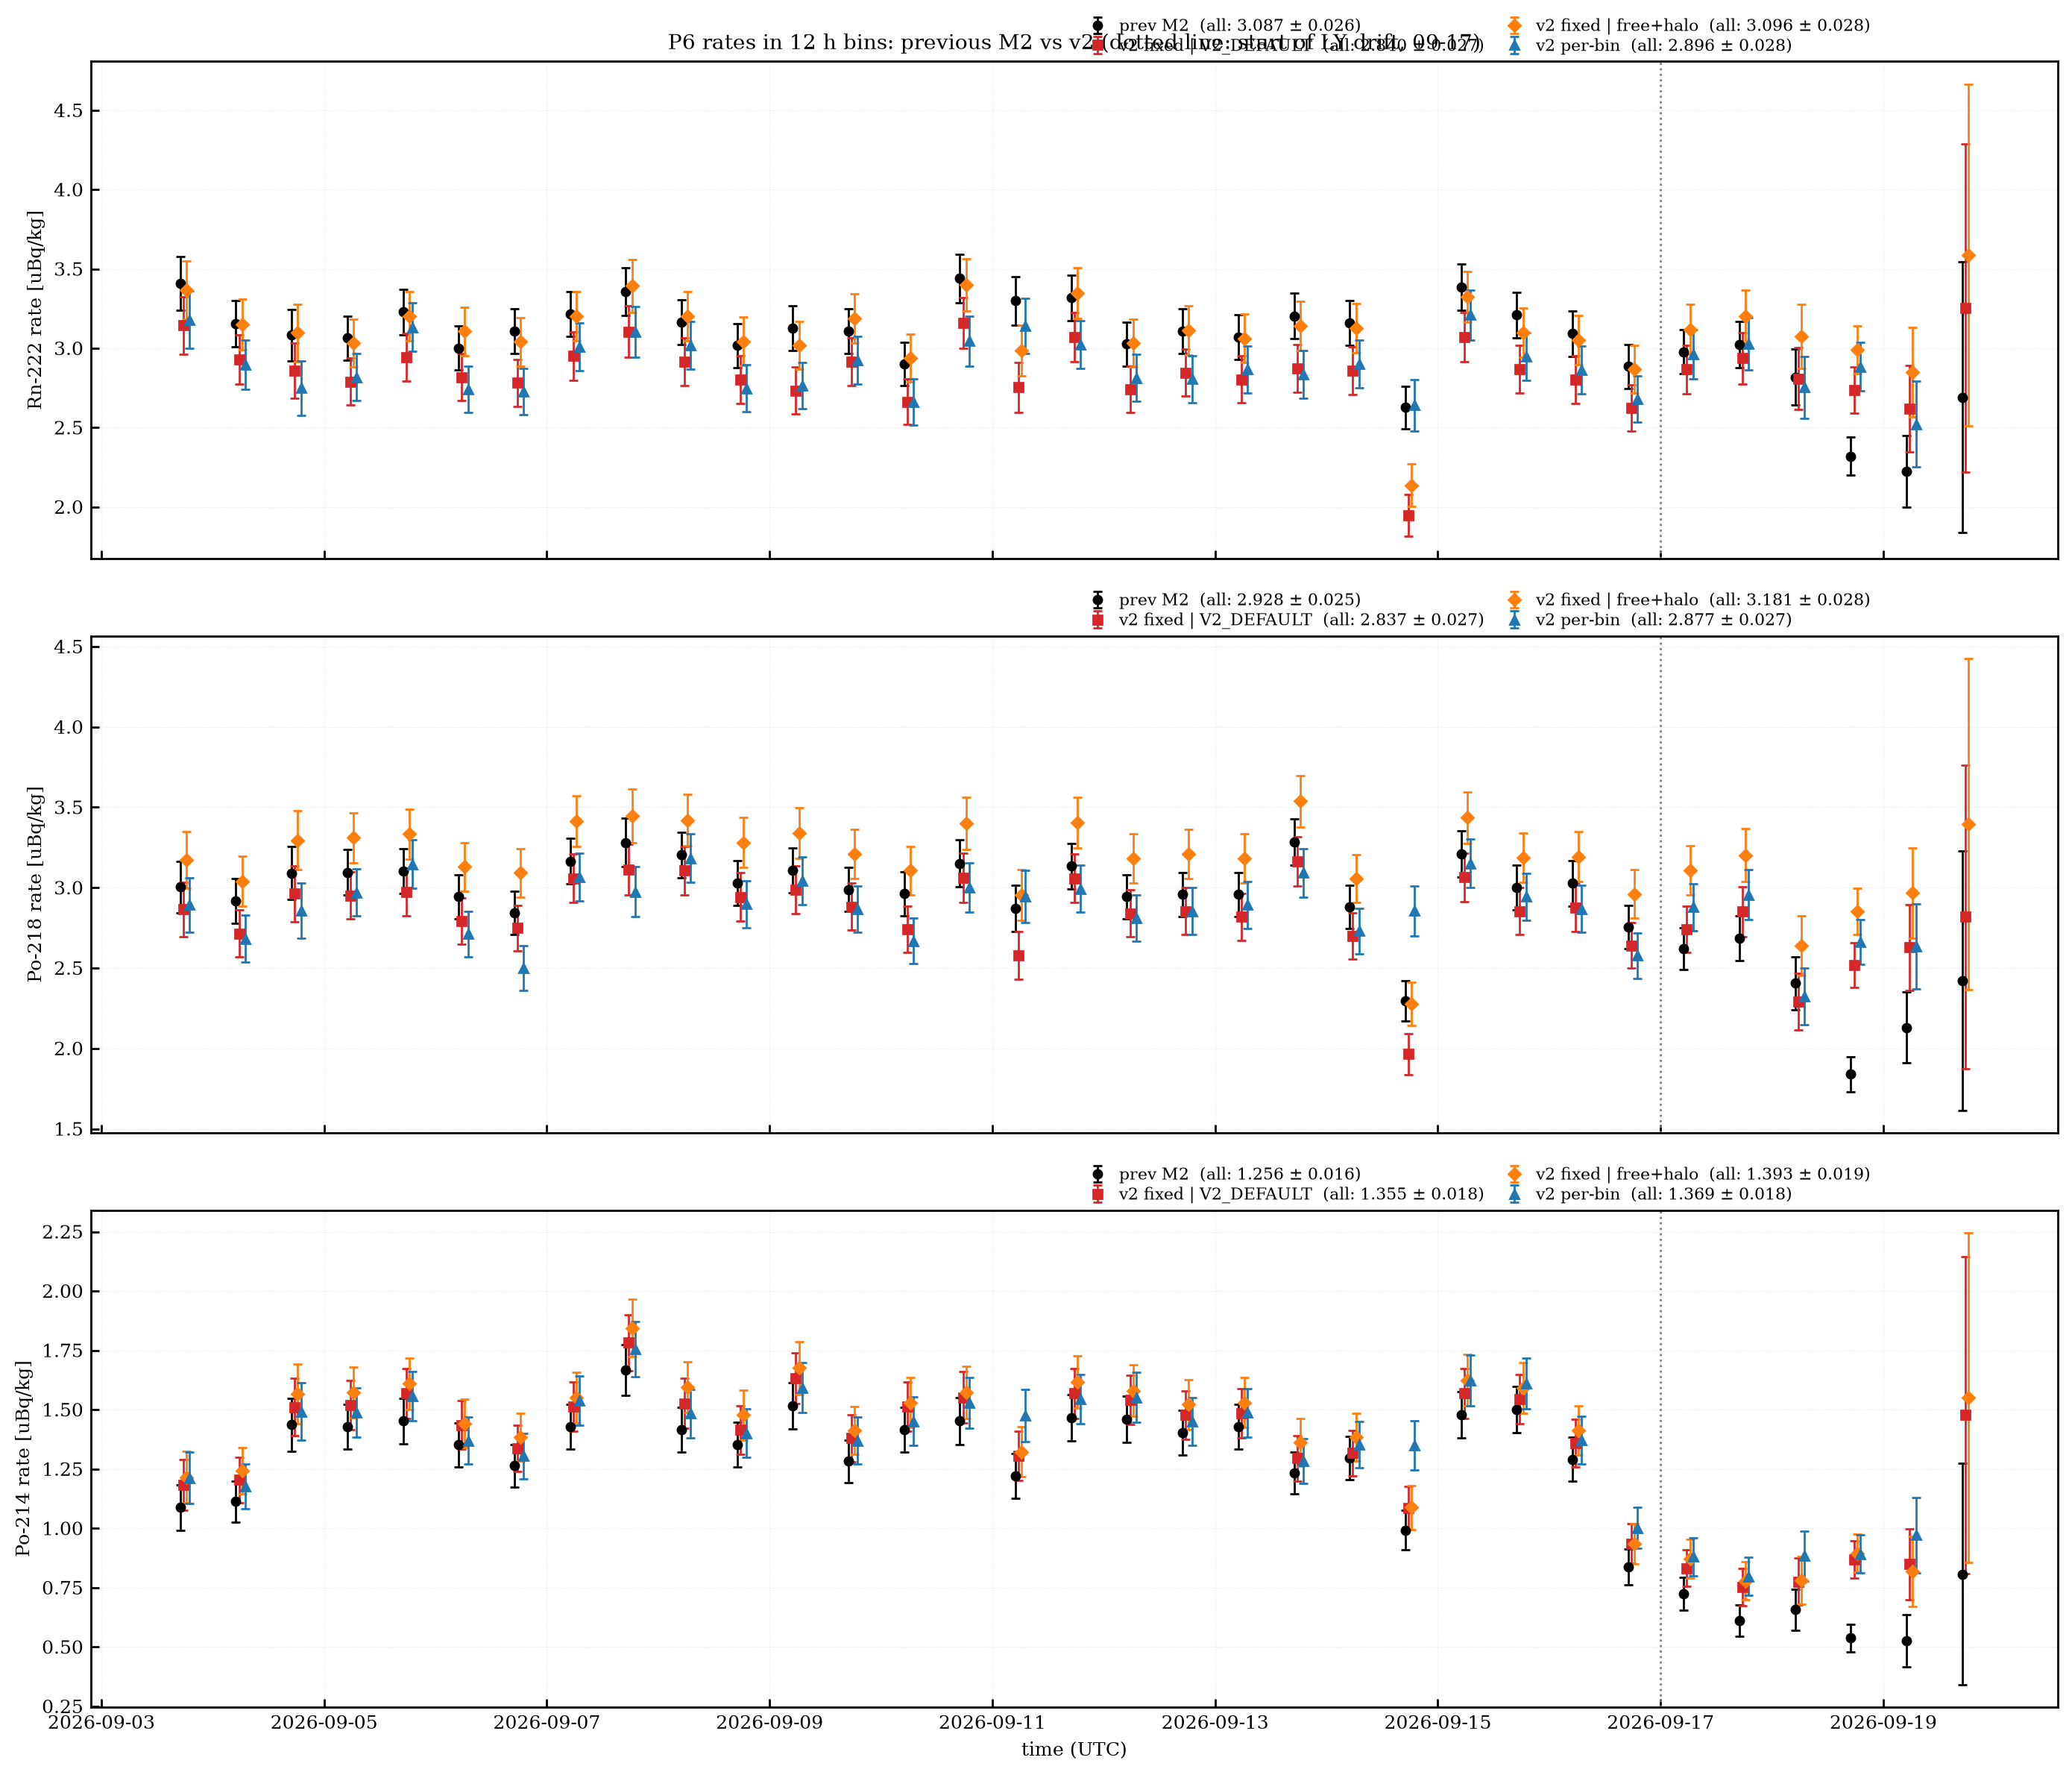

In [20]:
# ═══════════════════════════════════════════════════════════════
# CELL F — 12 h RATES: previous M2 vs v2 (fixed window on area_3 / per-bin windows)
# ═══════════════════════════════════════════════════════════════
# Methods (rate = n_corr / (livetime * 3660 kg), uBq/kg):
#   prev M2            : trend_per_run_P6.csv (raw ±2σ count, master partition fit)
#   v2 fixed | <cfg>   : area_3, one ±2σ window from the combined v2 fit,
#                        contamination scaled by livetime share, / acceptance
#   v2 per-bin         : area_2 (no drift corr.), V2_DEFAULT refit in each bin with the
#                        halo / Po-210 / bg-slope shape fixed from res_v2; own window
# Events and livetime are binned by the START time of their run.
T_BIN_H = 12
FIXED_CFGS = {'V2_DEFAULT': res_v2, 'free+halo': fits_v2['v2 free | area_3 | halo']}
SHAPE_FIX = [n for n in ('f_halo', 'r_halo', 'sig_Po-210', 'b1') if n in res_v2['names']]

prev = pd.read_csv(RUNS_CSV)
prev['run'] = prev['run'].astype(str).str.zfill(6)
runs_lt = prev.drop_duplicates('run').set_index('run')[['start_s', 'livetime_s']]
t_lo = np.floor(runs_lt['start_s'].min() / (T_BIN_H*3600)) * T_BIN_H*3600
runs_lt['tbin'] = ((runs_lt['start_s'] - t_lo) // (T_BIN_H*3600)).astype(int)
prev['tbin'] = prev['run'].map(runs_lt['tbin'])

ev_run = ev['run_name'].astype(str).str.zfill(6)
ev['tbin'] = ev_run.map(runs_lt['tbin'])
print('events without a run in %s: %d' % (RUNS_CSV, ev['tbin'].isna().sum()))
lt_bin = runs_lt.groupby('tbin')['livetime_s'].sum()
lt_tot = lt_bin.sum()

def corrected_count(x, res, iso, contam_scale=1.0):
    j = [s[0] for s in res['peaks']].index(iso)
    lo, hi = res['mu'][j] - 2*res['sigma'][j], res['mu'][j] + 2*res['sigma'][j]
    n_win = int(((x >= lo) & (x <= hi)).sum())
    cdf = res['cdf']
    contam = float(cdf(hi, 'bg') - cdf(lo, 'bg'))
    contam += sum(float(cdf(hi, i) - cdf(lo, i)) for i in range(len(res['peaks'])) if i != j)
    acc = float(cdf(hi, j) - cdf(lo, j)) / res['yield'][j]
    return n_win, (n_win - contam*contam_scale) / acc, np.sqrt(max(n_win, 1)) / acc

fix_vals = {n: res_v2['p_fit'][res_v2['names'].index(n)] for n in SHAPE_FIX}
rows = []
for b, lt in lt_bin.items():
    g = ev[ev['tbin'] == b]
    base = {'tbin': b, 't_start': t_lo + b*T_BIN_H*3600, 'livetime_s': lt, 'n_events': len(g)}
    norm_b = 1e6 / (lt * MASS_TOTAL_KG)
    pb = prev[prev['tbin'] == b]
    for iso in RATE_ISO:
        n = pb.loc[pb['isotope'] == iso, 'n_events'].sum()
        rows.append({**base, 'method': 'prev M2', 'isotope': iso, 'n_window': n, 'n_corr': n,
                     'rate': n*norm_b, 'rate_err': np.sqrt(max(n, 1))*norm_b})
    for cname, res in FIXED_CFGS.items():
        for iso in RATE_ISO:
            nw, nc, ne = corrected_count(g['area_3'].values, res, iso, lt / lt_tot)
            rows.append({**base, 'method': 'v2 fixed | ' + cname, 'isotope': iso, 'n_window': nw,
                         'n_corr': nc, 'rate': nc*norm_b, 'rate_err': ne*norm_b})
    r = fit_spectrum_v2(g, **{**V2_DEFAULT, 'col': 'area_2_corrected'}, fix=fix_vals) if len(g) > 300 else {}
    for iso in RATE_ISO:
        if 'yield' in r:
            nw, nc, ne = corrected_count(g['area_2_corrected'].values, r, iso)
            rows.append({**base, 'method': 'v2 per-bin', 'isotope': iso, 'n_window': nw, 'n_corr': nc,
                         'rate': nc*norm_b, 'rate_err': ne*norm_b, 'fit_status': r['status'],
                         'mu': r['mu'][[s[0] for s in r['peaks']].index(iso)]})

rates12 = pd.DataFrame(rows)
rates12['t_center'] = pd.to_datetime(rates12['t_start'] + T_BIN_H*1800, unit='s', utc=True)
rates12.to_csv('fit_test_rates_%dh_P6.csv' % T_BIN_H, index=False)
print('Wrote fit_test_rates_%dh_P6.csv  (%d bins)' % (T_BIN_H, len(lt_bin)))

# ── summary: whole period, stable days, drifted days (>= 09-17) ──
t_drift = pd.Timestamp('2026-09-17', tz='UTC')
def period_rate(df):
    lt_sum = df.drop_duplicates('tbin')['livetime_s'].sum()
    n = df['n_corr'].sum(); e = np.sqrt((df['rate_err']**2 * df['livetime_s']**2).sum())
    return n / (lt_sum*MASS_TOTAL_KG) * 1e6, e / lt_sum
rows = []
for (meth, iso), g in rates12.groupby(['method', 'isotope']):
    row = {'method': meth, 'isotope': iso}
    for lab, sel in [('all', g), ('before 09-17', g[g['t_center'] < t_drift]), ('09-17+', g[g['t_center'] >= t_drift])]:
        rt, er = period_rate(sel)
        row[lab] = '%.3f ± %.3f' % (rt, er)
    rows.append(row)
summ = pd.DataFrame(rows)
print(summ.to_string(index=False))
n_bad = (rates12.loc[rates12['method'] == 'v2 per-bin', 'fit_status'] != 'success').sum() // len(RATE_ISO)
print('per-bin fits not converged: %d / %d bins' % (n_bad, len(lt_bin)))

# ── plot: 3 isotopes vs time ──
styles = {'prev M2': ('k', 'o'), 'v2 fixed | V2_DEFAULT': ('tab:red', 's'),
          'v2 fixed | free+halo': ('tab:orange', 'D'), 'v2 per-bin': ('tab:blue', '^')}
fig, axes = plt.subplots(len(RATE_ISO), 1, figsize=(14, 4*len(RATE_ISO)), sharex=True)
for ax, iso in zip(axes, RATE_ISO):
    for k, (meth, (col, mk)) in enumerate(styles.items()):
        g = rates12[(rates12['method'] == meth) & (rates12['isotope'] == iso)]
        dt = pd.to_timedelta((k - 1.5) * 40, unit='min')
        ax.errorbar(g['t_center'] + dt, g['rate'], yerr=g['rate_err'], fmt=mk, ms=4, capsize=2,
                    color=col, lw=1, label='%s  (all: %s)' % (meth, summ.loc[(summ['method'] == meth)
                                                                          & (summ['isotope'] == iso), 'all'].iloc[0]))
    ax.axvline(t_drift, color='gray', ls=':', lw=1)
    ax.set_ylabel('%s rate [uBq/kg]' % iso); ax.grid(True, alpha=0.25); ax.legend(fontsize=8, loc='lower left')
axes[0].set_title('P6 rates in %d h bins: previous M2 vs v2 (dotted line: start of LY drift, 09-17)' % T_BIN_H)
axes[-1].set_xlabel('time (UTC)')
safe_tight(fig); plt.show()

AFT 0.150-0.455: 62084 events | windows: Rn-222 51286-54066, Po-218 56289-59200, Po-214 72530-76888, low 45000-51286
   r2_lo    r2_hi  n_events  N_low  frac_low  N_Rn-222  frac_Rn-222  N_Po-218  frac_Po-218  N_Po-214  frac_Po-214     mu_Rn   sig_Rn  sigIQR_Rn  Po218/Rn  Po214/Rn
   0.316 1069.746      6209     14     0.002      2261        0.364      2142        0.345       966        0.156 52543.590  483.152    483.424     0.947     0.427
1069.746 1895.009      6208     62     0.010      2230        0.359      2092        0.337       948        0.153 52489.261  585.182    591.260     0.938     0.425
1895.009 2497.963      6208    111     0.018      2045        0.329      2029        0.327       911        0.147 52577.030  684.863    700.888     0.992     0.445
2497.963 2916.799      6209    402     0.065      1722        0.277      1718        0.277       761        0.123 52585.306  773.643    806.213     0.998     0.442
2916.799 3145.952      6208   1643     0.265      1186        0

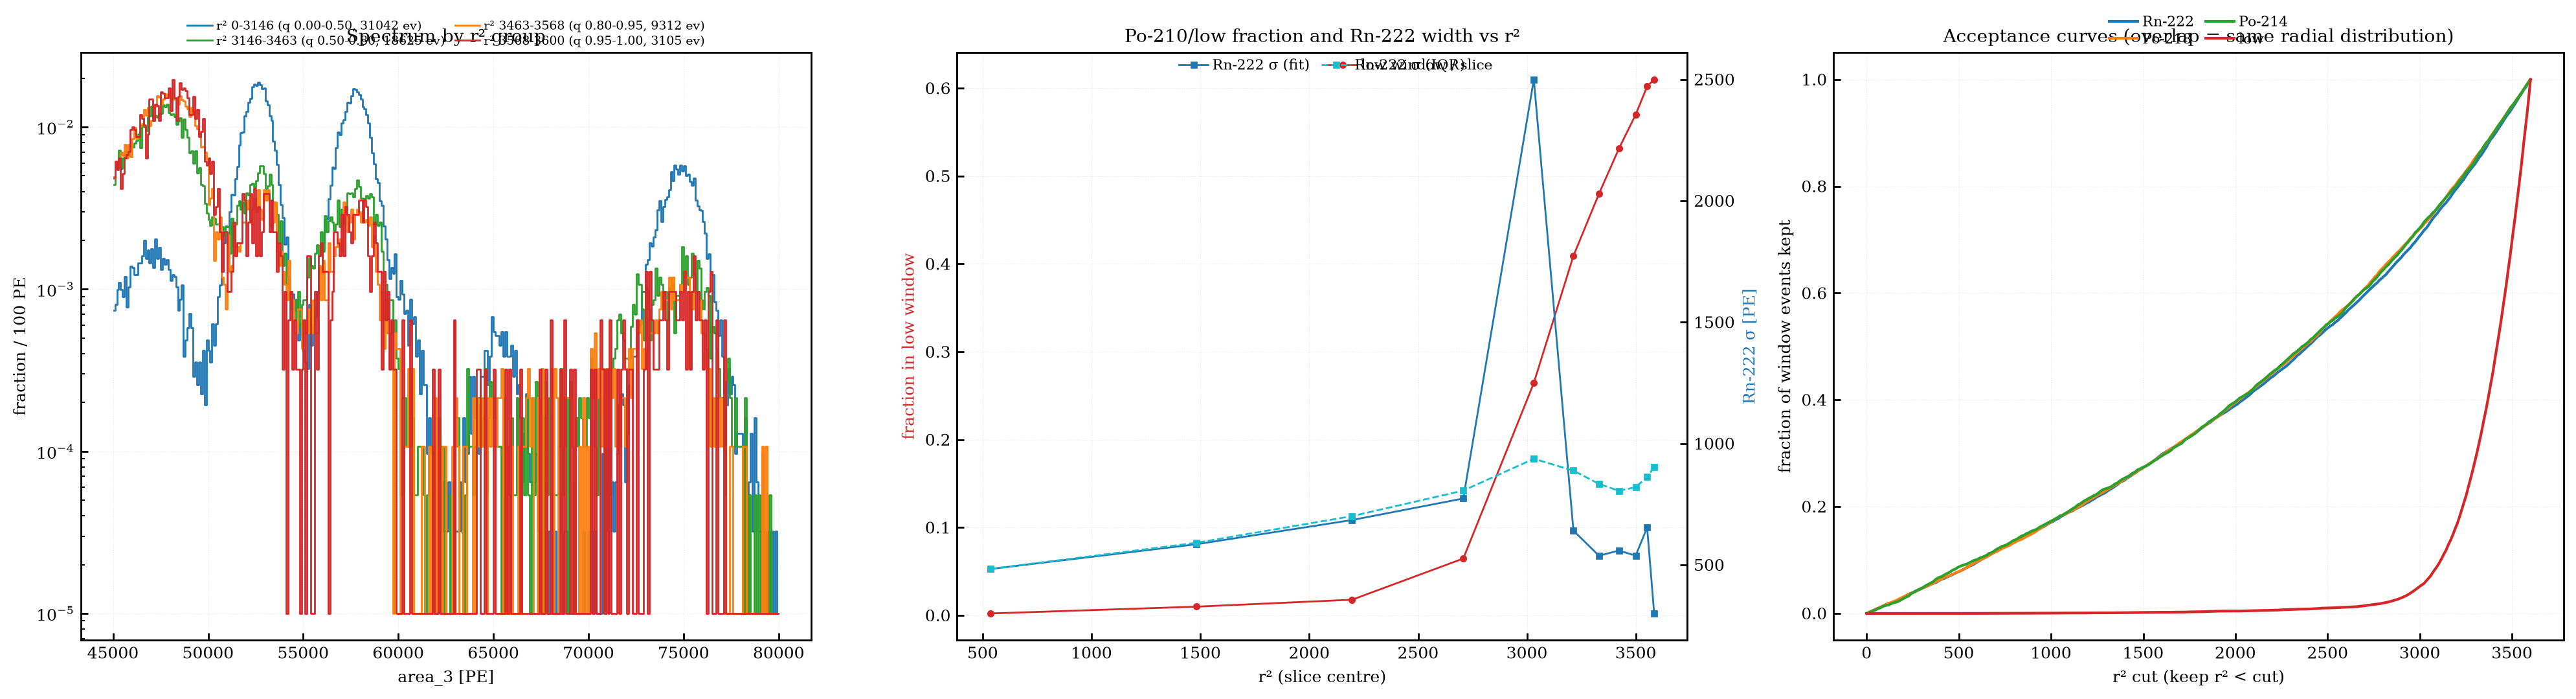

In [21]:
# ═══════════════════════════════════════════════════════════════
# CELL G — r² SPLIT (read-only diagnostic for an inner cut + acceptance)
# ═══════════════════════════════════════════════════════════════
# AFT [0.15, 0.455] (Dominick, 3660 kg), area_3 (time-corrected).
# Per equal-count r² slice: window counts / slice, Rn-222 mu & sigma, ratios.
# Windows: Rn-222 / Po-218 / Po-214 = ±2σ from res_v2; 'low' = 45k .. Rn window
# lower edge (Po-210 + low-side continuum).
# Cumulative window counts vs r² cut = acceptance curves (should overlap if
# the isotopes are spread the same way in radius).
R2_COL = 'r2_aft_corrected'
AFT_G = (0.15, 0.455)
RN_SPEC = [('Rn-222', 5.590, 53000, (50000, 57000), 700, (300, 2500))]

gsel = ev[(ev['area_fraction_top'] >= AFT_G[0]) & (ev['area_fraction_top'] <= AFT_G[1])
          & ev[R2_COL].notna()]
x3, r2v = gsel['area_3'].values, gsel[R2_COL].values
win = {}
for iso in RATE_ISO:
    j = [s[0] for s in res_v2['peaks']].index(iso)
    win[iso] = (res_v2['mu'][j] - 2*res_v2['sigma'][j], res_v2['mu'][j] + 2*res_v2['sigma'][j])
win['low'] = (45e3, win['Rn-222'][0])
in_win = {k: (x3 >= lo) & (x3 <= hi) for k, (lo, hi) in win.items()}
print('AFT %.3f-%.3f: %d events | windows: %s' % (AFT_G[0], AFT_G[1], len(gsel),
      ', '.join('%s %.0f-%.0f' % (k, lo, hi) for k, (lo, hi) in win.items())))

q_edges = np.nanquantile(r2v, list(np.linspace(0, 0.9, 10)) + [0.95, 1.0])
q_edges[-1] += 1e-6
rows = []
for lo, hi in zip(q_edges[:-1], q_edges[1:]):
    s = (r2v >= lo) & (r2v < hi)
    n = int(s.sum())
    row = {'r2_lo': lo, 'r2_hi': hi, 'n_events': n}
    for k in ['low'] + RATE_ISO:
        row['N_'+k] = int((s & in_win[k]).sum())
        row['frac_'+k] = row['N_'+k] / max(n, 1)
    sub3 = pd.DataFrame({'area_2_corrected': x3[s]})
    r = fit_spectrum(sub3, RN_SPEC, (50e3, 57e3), 140, bg_deg=1)
    row['mu_Rn'] = float(r['mu'][0]) if r.get('success') else np.nan
    row['sig_Rn'] = float(r['sigma'][0]) if r.get('success') else np.nan
    core = x3[s & (np.abs(x3 - res_v2['mu'][[p[0] for p in res_v2['peaks']].index('Rn-222')]) < 1500)]
    row['sigIQR_Rn'] = np.subtract(*np.percentile(core, [75, 25])) / 1.349 if len(core) > 20 else np.nan
    row['Po218/Rn'] = row['N_Po-218'] / max(row['N_Rn-222'], 1)
    row['Po214/Rn'] = row['N_Po-214'] / max(row['N_Rn-222'], 1)
    rows.append(row)

r2_split = pd.DataFrame(rows)
print(r2_split.round(3).to_string(index=False))
r2_split.to_csv('fit_test_r2_split_P6.csv', index=False)
print('\nWrote fit_test_r2_split_P6.csv')

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
# [0] spectra by r² group, normalised per event
ax = axes[0]
for (qlo, qhi), col in zip([(0, 0.5), (0.5, 0.8), (0.8, 0.95), (0.95, 1.0)],
                           ['tab:blue', 'tab:green', 'tab:orange', 'tab:red']):
    lo, hi = np.nanquantile(r2v, [qlo, qhi])
    s = (r2v >= lo) & (r2v <= hi)
    h, e = np.histogram(x3[s], bins=350, range=(45e3, 80e3))
    ax.step(0.5*(e[1:] + e[:-1]), np.maximum(h / max(s.sum(), 1), 1e-5), where='mid', color=col, lw=1,
            label='r² %.0f-%.0f (q %.2f-%.2f, %d ev)' % (lo, hi, qlo, qhi, s.sum()))
ax.set_yscale('log'); ax.set_xlabel('area_3 [PE]'); ax.set_ylabel('fraction / 100 PE')
ax.set_title('Spectrum by r² group'); ax.legend(fontsize=7); ax.grid(True, alpha=0.25)
# [1] Po-210/low fraction and Rn-222 width vs r²
ax = axes[1]
rc = 0.5*(r2_split['r2_lo'] + r2_split['r2_hi'])
ax.plot(rc, r2_split['frac_low'], 'o-', color='tab:red', label='low window / slice')
ax.set_xlabel('r² (slice centre)'); ax.set_ylabel('fraction in low window', color='tab:red')
ax2 = ax.twinx()
ax2.plot(rc, r2_split['sig_Rn'], 's-', color='tab:blue', label='Rn-222 σ (fit)')
ax2.plot(rc, r2_split['sigIQR_Rn'], 's--', color='tab:cyan', label='Rn-222 σ (IQR)')
ax2.set_ylabel('Rn-222 σ [PE]', color='tab:blue')
ax.set_title('Po-210/low fraction and Rn-222 width vs r²')
ax.legend(loc='upper left', fontsize=8); ax2.legend(loc='upper center', fontsize=8); ax.grid(True, alpha=0.25)
# [2] acceptance curves: cumulative fraction of window counts vs r² cut
ax = axes[2]
grid = np.linspace(np.nanmin(r2v), np.nanmax(r2v), 300)
for k, col in zip(RATE_ISO + ['low'], ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']):
    rk = np.sort(r2v[in_win[k]])
    ax.plot(grid, np.searchsorted(rk, grid, side='right') / max(len(rk), 1), color=col, lw=1.5, label=k)
ax.set_xlabel('r² cut (keep r² < cut)'); ax.set_ylabel('fraction of window events kept')
ax.set_title('Acceptance curves (overlap = same radial distribution)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.25)
safe_tight(fig); plt.show()

### How to read the v2 section

- **A**: `capture < 1` or `at_bound=True` on a day means the fixed combined window or bounds lose that day's peak.
  This is light-yield drift, not a change in rate.
- **B**: the chunk mu spread should drop to about the fit error, and the combined sigma should approach the daily sigma.
  If the three `ratio_*` columns disagree, the drift is not a pure scale; check for non-linearity.
- **C/E**: `pk_*` should be within about ±2% of 1, and pulls should show no structure within ±2σ of each peak.
  A positive-centre / negative-flank pull pattern means the peak is still a width mixture: use `tail='halo'`.
  `at_limit` flags parameters on a bound. For a small peak (Rn-220) that is fine if its N is about 0.
- **D**: `window/fit - 1` (window count with acceptance + leakage correction vs fitted yield) should be ≲ 1%.
  The spread across configs in E is the shape systematic on the rate.
- **Toys**: mean pull about 0 and width about 1 means the fit itself is unbiased.

To port to the master: the alpha-energy table and relative bounds, the `area_3` time correction,
and `window_rate_v2` (acceptance + leakage) in place of the raw ±2σ count in `_get_window` / M2.

## Next — port the winning config back

1. Set `FIT_PEAKS` in the master to the chosen component list and bounds
   (the widened Po-214 bound is the key change).
2. Set `FIT_RANGE` / background degree if the scan prefers another combo.
3. Fix the hardcoded "5-component" title in cell 64 to
   `'%d-component fit' % len(FIT_COMPONENTS)`.
4. Rerun the master's fit + rate sections.

> The saved pickle is the **post-FV** sample. If corrections / FV change,
> regenerate it from the master before re-running these tests.
